# Appendix C — Solutions to the Exercises

This appendix collects the solutions of the exercises, chapter by chapter. It grows as the book grows: each new chapter adds its own section.

**How to use it.** Try the exercise first, then read the hint in the chapter, and only then look here. For the manual exercises the solution is written out in full. For the computational exercises the solution is a complete, executable piece of code, followed by a short discussion of what the output shows; there are many correct ways to write such code, and yours may differ.

**A note on the code.** Each solution lives in a function (`solution_1_6()`, and so on), so that the cells do not overwrite each other's variables. The function names match the exercise numbers.

In [1]:
import platform
from importlib.metadata import version

print("Python", platform.python_version())
for pkg in ["numpy", "scipy", "pandas", "matplotlib", "scikit-learn"]:
    print(f"{pkg:<14}{version(pkg)}")

Python 3.15.2
numpy         2.5.5
scipy         1.18.1
pandas        3.1.1
matplotlib    3.11.2
scikit-learn  1.9.1


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42

# Same plotting style and color-blind-safe palette as in the chapters
BLUE, ORANGE, GREEN = "#0072B2", "#E69F00", "#009E73"
VERMILION, SKY, PURPLE = "#D55E00", "#56B4E9", "#CC79A7"
plt.rcParams.update({
    "figure.dpi": 110,
    "figure.figsize": (6.4, 4.0),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
})

## C.1 Chapter 1

### Manual exercises

**Solution 1.1 — Name the problem.**

| Task | Paradigm | Type |
|---|---|---|
| (a) tomorrow's electricity consumption | supervised | regression (the target is a real number) |
| (b) grouping customers without predefined groups | unsupervised | clustering (Chapter 12) |
| (c) spam or not spam | supervised | classification (two classes) |
| (d) learning a game by self-play, from wins and losses | reinforcement learning | the wins and losses are the reward signal (Chapter 22) |
| (e) reducing 1000 measurements to 10 numbers | unsupervised | dimensionality reduction (Chapter 13) |

**Solution 1.2 — Shapes.**
(a) $\mathbf{X} \in \mathbb{R}^{200 \times 5}$ and $\mathbf{y} \in \mathbb{R}^{200}$.
(b) The intercept column adds one column: $200 \times 6$.
(c) $\mathbf{X}^\top\mathbf{X}$ is $d \times d$, that is $5 \times 5$ (and $6 \times 6$ for the design matrix with the intercept). Its size depends on the number of features, not on the number of samples.
(d) Each entry of $\mathbf{X}\mathbf{w}$ is the dot product of a row of $\mathbf{X}$ with $\mathbf{w}$:

$$
\mathbf{X}\mathbf{w} = \begin{pmatrix} 1\cdot 1 + 2\cdot(-1) \\ 3\cdot 1 + 4\cdot(-1) \\ 5\cdot 1 + 6\cdot(-1) \end{pmatrix} = \begin{pmatrix} -1 \\ -1 \\ -1 \end{pmatrix}.
$$

The $i$-th entry is the prediction of the linear model $f(\mathbf{x}) = \mathbf{w}^\top\mathbf{x}$ for the $i$-th sample; here, the first feature minus the second.

**Solution 1.3 — Least squares by hand.** The points are $(0,2)$, $(1,2)$, $(2,5)$.

(a) $\mathbf{X} = \begin{pmatrix} 1 & 0 \\ 1 & 1 \\ 1 & 2 \end{pmatrix}$, $\mathbf{y} = \begin{pmatrix} 2 \\ 2 \\ 5 \end{pmatrix}$. Then $\mathbf{X}^\top\mathbf{X} = \begin{pmatrix} 3 & 3 \\ 3 & 5 \end{pmatrix}$ and $\mathbf{X}^\top\mathbf{y} = \begin{pmatrix} 9 \\ 12 \end{pmatrix}$. With $\det = 6$,

$$
\hat{\mathbf{w}} = \frac{1}{6}\begin{pmatrix} 5 & -3 \\ -3 & 3 \end{pmatrix}\begin{pmatrix} 9 \\ 12 \end{pmatrix}
= \frac{1}{6}\begin{pmatrix} 9 \\ 9 \end{pmatrix} = \begin{pmatrix} 3/2 \\ 3/2 \end{pmatrix},
$$

so the line is $\hat{y} = \tfrac32 + \tfrac32 x$.

(b) $\hat{\mathbf{y}} = (1.5,\ 3,\ 4.5)^\top$, hence $\mathbf{r} = \mathbf{y} - \hat{\mathbf{y}} = (0.5,\ -1,\ 0.5)^\top$. Then $\sum_i r_i = 0$ and $\mathbf{r}\cdot(0,1,2) = 0 - 1 + 1 = 0$: $\mathbf{X}^\top\mathbf{r} = \mathbf{0}$.

(c) $\text{MSE} = \frac{0.25 + 1 + 0.25}{3} = 0.5$. The mean of $\mathbf{y}$ is $3$ and $\sum_i (y_i - \bar y)^2 = 1 + 1 + 4 = 6$, so $R^2 = 1 - \frac{1.5}{6} = 0.75$.

**Solution 1.4 — Derive it yourself.**
(a) $L(w) = \sum_i (y_i - w x_i)^2$, so $L'(w) = -2\sum_i x_i (y_i - w x_i)$. Setting $L'(w) = 0$ gives $\sum_i x_i y_i = w \sum_i x_i^2$, that is

$$
\hat{w} = \frac{\sum_i x_i y_i}{\sum_i x_i^2}.
$$

(b) With a single column $\mathbf{x} = (x_1, \dots, x_n)^\top$ as the data matrix, $\mathbf{X}^\top\mathbf{X} = \mathbf{x}^\top\mathbf{x} = \sum_i x_i^2$ (a $1\times 1$ matrix) and $\mathbf{X}^\top\mathbf{y} = \sum_i x_i y_i$, so $(\mathbf{X}^\top\mathbf{X})^{-1}\mathbf{X}^\top\mathbf{y}$ is the same ratio.

(c) $L''(w) = 2\sum_i x_i^2$, which is strictly positive unless every $x_i$ is zero. Hence $L$ is strictly convex and $\hat{w}$ is its unique minimizer.

**Solution 1.5 — Which loss, which constant?**
(a) $f(c) = \sum_i (y_i - c)^2$ has $f'(c) = -2\sum_i (y_i - c)$, which vanishes at $c = \frac1n\sum_i y_i$; and $f'' = 2n > 0$. The minimizer is the mean.

(b) Let $g(c) = \sum_i \lvert y_i - c\rvert$, with $n = 2m - 1$ and $m = (n+1)/2$. The function $g$ is piecewise linear. At a point $c$ that is not a data point, $g'(c) = \#\{y_i < c\} - \#\{y_i > c\}$ (each term with $y_i < c$ contributes $+1$, each term with $y_i > c$ contributes $-1$).
- For $c$ between $y_{(m-1)}$ and $y_{(m)}$: $m - 1$ points lie below and $m$ above, so $g' = -1 < 0$.
- For $c$ between $y_{(m)}$ and $y_{(m+1)}$: $m$ points lie below and $m - 1$ above, so $g' = +1 > 0$.

More generally the slope is $2k - n$ when $k$ points lie below $c$, which is negative for $k < m$ and positive for $k \ge m$. So $g$ decreases up to $y_{(m)}$ and increases afterwards: the minimizer is $y_{(m)}$, the median.

(c) Replace $y_n$ by $10^6$. The order of the points is unchanged (it was already the largest, and it only grows), so the **median is unchanged**. The **mean** instead moves by $(10^6 - y_n)/n$, which can be enormous: one outlier drags the optimal constant of the squared loss arbitrarily far. The squared loss is therefore sensitive to outliers (it squares large errors), while the absolute loss is robust. When the data may contain outliers, the choice of loss matters as much as the choice of model.

### Python exercises

**Solution 1.6 — Meet a new data set.**

In [3]:
def solution_1_6():
    from sklearn.datasets import load_wine

    wine = load_wine(as_frame=True)
    X, y = wine.data, wine.target
    print("shape of X:", X.shape)
    print("classes:", dict(zip(wine.target_names.tolist(), np.bincount(y).tolist())))
    print("first five features:", X.columns[:5].tolist())

    stats = X.describe().loc[["mean", "std"]].T
    print("\nmean and standard deviation of each feature:")
    print(stats.round(3).to_string())
    print("\nfeature with the largest standard deviation:", stats["std"].idxmax())

solution_1_6()

shape of X: (178, 13)
classes: {'class_0': 59, 'class_1': 71, 'class_2': 48}
first five features: ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium']

mean and standard deviation of each feature:
                                 mean      std
alcohol                        13.001    0.812
malic_acid                      2.336    1.117
ash                             2.367    0.274
alcalinity_of_ash              19.495    3.340
magnesium                      99.742   14.282
total_phenols                   2.295    0.626
flavanoids                      2.029    0.999
nonflavanoid_phenols            0.362    0.124
proanthocyanins                 1.591    0.572
color_intensity                 5.058    2.318
hue                             0.957    0.229
od280/od315_of_diluted_wines    2.612    0.710
proline                       746.893  314.907

feature with the largest standard deviation: proline


The Wine data set has 178 samples, 13 features, and 3 classes. The feature `proline` lives on a scale of hundreds (its mean is in the 700s and its standard deviation above 300), while most other features are of order 1 to 100 and some are below 1. In a distance-based method such as k-NN, `proline` would dominate the Euclidean distance and the other features would barely matter: **standardize the features** first (Section 1.8).

**Solution 1.7 — A line on Iris.**

normal equations: [-0.36308  0.41576]
lstsq           : [-0.36308  0.41576]
scikit-learn    : [-0.36308  0.41576]
all agree: True

MSE = 0.0421 | baseline MSE = 0.5771 | R^2 = 0.9271


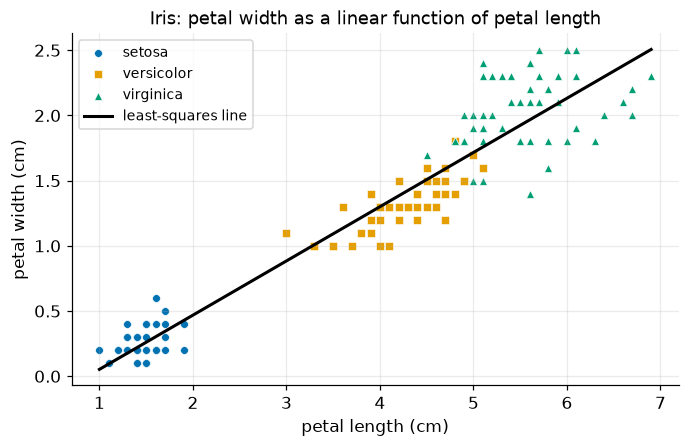

In [4]:
def solution_1_7():
    from sklearn.datasets import load_iris
    from sklearn.linear_model import LinearRegression

    iris = load_iris(as_frame=True)
    x = iris.data["petal length (cm)"].to_numpy()
    t = iris.data["petal width (cm)"].to_numpy()
    A = np.column_stack([np.ones_like(x), x])

    # (a) three ways to the same answer
    w_normal = np.linalg.solve(A.T @ A, A.T @ t)
    w_lstsq = np.linalg.lstsq(A, t, rcond=None)[0]
    lr = LinearRegression().fit(x.reshape(-1, 1), t)
    w_sk = np.array([lr.intercept_, lr.coef_[0]])
    print("normal equations:", w_normal.round(5))
    print("lstsq           :", w_lstsq.round(5))
    print("scikit-learn    :", w_sk.round(5))
    print("all agree:", np.allclose(w_normal, w_lstsq) and np.allclose(w_normal, w_sk))

    # (b) error, baseline, R^2
    t_hat = A @ w_normal
    mse = np.mean((t - t_hat) ** 2)
    mse_base = np.mean((t - t.mean()) ** 2)
    r2 = 1 - np.sum((t - t_hat) ** 2) / np.sum((t - t.mean()) ** 2)
    print(f"\nMSE = {mse:.4f} | baseline MSE = {mse_base:.4f} | R^2 = {r2:.4f}")

    # (c) plot
    fig, ax = plt.subplots(figsize=(6.4, 4.2))
    species = iris.target.to_numpy()
    for k, (name, color, marker) in enumerate(zip(iris.target_names, [BLUE, ORANGE, GREEN], ["o", "s", "^"])):
        ax.scatter(x[species == k], t[species == k], s=26, color=color, marker=marker,
                   edgecolor="white", linewidth=0.4, label=name)
    xs = np.linspace(x.min(), x.max(), 100)
    ax.plot(xs, w_normal[0] + w_normal[1] * xs, color="black", linewidth=2, label="least-squares line")
    ax.set_xlabel("petal length (cm)")
    ax.set_ylabel("petal width (cm)")
    ax.set_title("Iris: petal width as a linear function of petal length")
    ax.legend(fontsize=9)
    fig.tight_layout()
    plt.show()

solution_1_7()

The three methods agree to numerical precision. The line explains more than 90% of the variance of the petal width (compare the MSE with the baseline MSE, and read the $R^2$): on this data set the two petal measurements are strongly linearly related. Note that the cloud is not homogeneous across species, and the line is a compromise between the three groups.

**Solution 1.8 — Does scaling matter?**

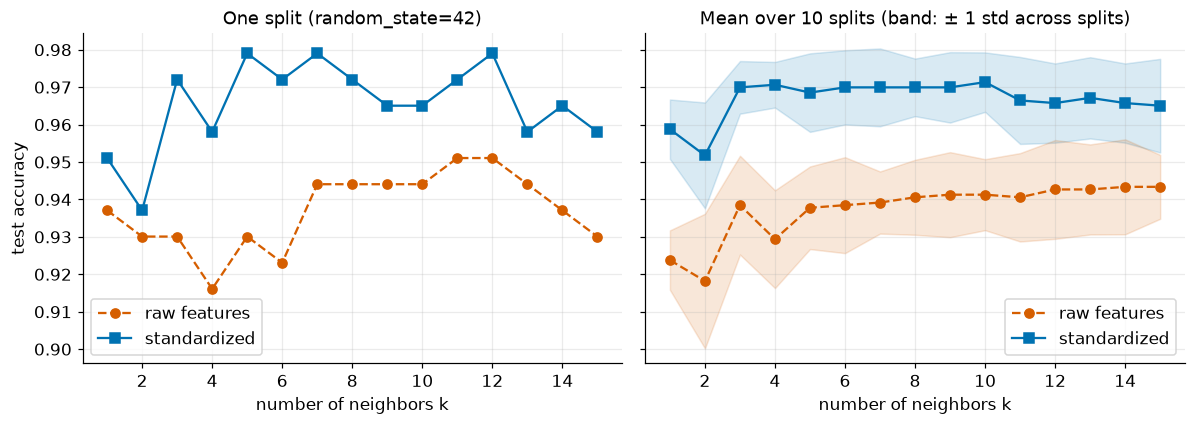

mean accuracy gain from scaling: 0.029
fraction of (split, k) pairs where scaling is at least as good: 1.000
fraction where scaling is strictly better: 0.987


In [5]:
def solution_1_8():
    from sklearn.datasets import load_breast_cancer
    from sklearn.model_selection import train_test_split
    from sklearn.neighbors import KNeighborsClassifier
    from sklearn.pipeline import make_pipeline
    from sklearn.preprocessing import StandardScaler

    X, y = load_breast_cancer(return_X_y=True, as_frame=True)
    ks = np.arange(1, 16)

    def test_accuracies(seed):
        X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, stratify=y, random_state=seed)
        raw = [KNeighborsClassifier(k).fit(X_tr, y_tr).score(X_te, y_te) for k in ks]
        scaled = [make_pipeline(StandardScaler(), KNeighborsClassifier(k)).fit(X_tr, y_tr).score(X_te, y_te)
                  for k in ks]
        return raw, scaled

    # the split of Section 1.8 (random_state = SEED)
    raw_1, scaled_1 = test_accuracies(SEED)
    # ten different splits
    seeds = range(10)
    all_raw, all_scaled = map(np.array, zip(*(test_accuracies(s) for s in seeds)))

    fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
    axes[0].plot(ks, raw_1, "o--", color=VERMILION, label="raw features")
    axes[0].plot(ks, scaled_1, "s-", color=BLUE, label="standardized")
    axes[0].set_title(f"One split (random_state={SEED})")
    axes[1].plot(ks, all_raw.mean(axis=0), "o--", color=VERMILION, label="raw features")
    axes[1].plot(ks, all_scaled.mean(axis=0), "s-", color=BLUE, label="standardized")
    axes[1].fill_between(ks, all_scaled.mean(0) - all_scaled.std(0), all_scaled.mean(0) + all_scaled.std(0),
                         color=BLUE, alpha=0.15)
    axes[1].fill_between(ks, all_raw.mean(0) - all_raw.std(0), all_raw.mean(0) + all_raw.std(0),
                         color=VERMILION, alpha=0.15)
    axes[1].set_title("Mean over 10 splits (band: ± 1 std across splits)")
    for ax in axes:
        ax.set_xlabel("number of neighbors k")
        ax.legend()
    axes[0].set_ylabel("test accuracy")
    fig.tight_layout()
    plt.show()

    diff = all_scaled - all_raw                      # shape (10 splits, 15 values of k)
    print(f"mean accuracy gain from scaling: {diff.mean():.3f}")
    print(f"fraction of (split, k) pairs where scaling is at least as good: {(diff >= 0).mean():.3f}")
    print(f"fraction where scaling is strictly better: {(diff > 0).mean():.3f}")

solution_1_8()

The conclusion is stable. Averaged over the ten splits, standardized features give a higher test accuracy for essentially every $k$ (the gain is about three percentage points in our run), and the printed fractions show that scaling was never worse and almost always strictly better across all the (split, $k$) pairs. A single split would have been enough to see the effect here, but *only* repeating the experiment lets us say that the conclusion does not depend on the lucky choice of one split. This habit, repeating the evaluation on several splits, is formalized as cross-validation in Chapter 5.

**Solution 1.9 — Your own overfitting experiment.**

In [6]:
def solution_1_9():
    from numpy.polynomial import polynomial as P
    from sklearn.datasets import load_diabetes
    from sklearn.model_selection import train_test_split

    d = load_diabetes(as_frame=True, scaled=False)
    target = d.target.to_numpy()
    MAX_DEG, N_SPLITS = 8, 100

    def median_test_errors(z, n_train):
        errs = np.zeros((N_SPLITS, MAX_DEG + 1))
        for s in range(N_SPLITS):
            z_tr, z_te, y_tr, y_te = train_test_split(z, target, train_size=n_train, random_state=s)
            for degree in range(MAX_DEG + 1):
                coef = P.polyfit(z_tr, y_tr, degree)
                errs[s, degree] = np.mean((y_te - P.polyval(z_te, coef)) ** 2)
        return np.median(errs, axis=0)

    rows = []
    for feature in ["bp", "s5"]:
        f = d.data[feature].to_numpy()
        z = (f - f.mean()) / f.std()
        for n_train in [30, 100, 300]:
            med = median_test_errors(z, n_train)
            rows.append({"feature": feature, "training size": n_train,
                         "best degree": int(med.argmin()),
                         "test MSE at best degree": round(float(med.min()), 0),
                         "test MSE at degree 1 (a line)": round(float(med[1]), 0),
                         "test MSE at degree 0 (baseline)": round(float(med[0]), 0)})
    print(pd.DataFrame(rows).to_string(index=False))

solution_1_9()

feature  training size  best degree  test MSE at best degree  test MSE at degree 1 (a line)  test MSE at degree 0 (baseline)
     bp             30            1                   5037.0                         5037.0                           6056.0
     bp            100            1                   4874.0                         4874.0                           5982.0
     bp            300            4                   4782.0                         4785.0                           5891.0
     s5             30            1                   4274.0                         4274.0                           6056.0
     s5            100            3                   4053.0                         4126.0                           5982.0
     s5            300            3                   3914.0                         4047.0                           5891.0


In the table, the **best degree does not decrease as the training set grows**, and it tends to increase: with 30 patients a straight line is the best choice for both features, while with 300 patients a slightly more flexible curve is preferred. The reason is that the variance of a flexible model comes from having too few samples to pin down its many coefficients; as $n$ grows this variance shrinks, and the best compromise moves towards more flexibility. Note also that the gain of the best degree over a straight line is small (a few percent at most, and nil for `bp` with 100 or fewer patients): the relationship between a single feature and the target is weak and almost linear, so there is little to gain from flexibility, and the errors for neighboring degrees are close. Every model, however, is clearly better than the baseline (degree 0). The idea that **the right complexity depends on the amount of data** returns in Chapters 3 and 4.

**Solution 1.10 — When $\mathbf{X}^\top\mathbf{X}$ is singular.**

In [7]:
def solution_1_10():
    from sklearn.datasets import load_diabetes

    d = load_diabetes(as_frame=True, scaled=False)
    bmi, target = d.data["bmi"].to_numpy(), d.target.to_numpy()
    A1 = np.column_stack([np.ones_like(bmi), bmi])            # intercept + bmi
    A2 = np.column_stack([np.ones_like(bmi), bmi, bmi])       # intercept + bmi + a duplicate of bmi

    # (a) rank and conditioning
    print("rank of A1:", np.linalg.matrix_rank(A1), "| rank of A2:", np.linalg.matrix_rank(A2),
          "(A2 has 3 columns but only 2 independent ones)")
    print(f"condition number of A1^T A1: {np.linalg.cond(A1.T @ A1):.3g}")
    print(f"condition number of A2^T A2: {np.linalg.cond(A2.T @ A2):.3g}")

    # (b) the normal equations
    try:
        w_solve = np.linalg.solve(A2.T @ A2, A2.T @ target)
        print("np.linalg.solve returned (numerically meaningless):", w_solve)
    except np.linalg.LinAlgError as err:
        print("np.linalg.solve raised LinAlgError:", err)

    # (c) lstsq
    w2 = np.linalg.lstsq(A2, target, rcond=None)[0]
    w1 = np.linalg.lstsq(A1, target, rcond=None)[0]
    print("\nlstsq on A2:", w2.round(4), "| norm:", round(float(np.linalg.norm(w2)), 4))
    print("lstsq on A1:", w1.round(4))
    print("same predictions with and without the duplicate column:", np.allclose(A2 @ w2, A1 @ w1))

    # (d) other solutions with the same predictions
    candidates = {"(w1, 0)": np.array([w1[0], w1[1], 0.0]),
                  "(w1/2, w1/2)  [what lstsq picks]": np.array([w1[0], w1[1] / 2, w1[1] / 2]),
                  "(3 w1/4, w1/4)": np.array([w1[0], 0.75 * w1[1], 0.25 * w1[1]])}
    print("\nweights giving exactly the same predictions, and their norms:")
    for name, w in candidates.items():
        print(f"  {name:<36} predictions equal: {np.allclose(A2 @ w, A1 @ w1)} | norm = {np.linalg.norm(w):.4f}")

solution_1_10()

rank of A1: 2 | rank of A2: 2 (A2 has 3 columns but only 2 independent ones)
condition number of A1^T A1: 2.63e+04
condition number of A2^T A2: inf
np.linalg.solve raised LinAlgError: Singular matrix

lstsq on A2: [-117.7734    5.1166    5.1166] | norm: 117.9954
lstsq on A1: [-117.7734   10.2331]
same predictions with and without the duplicate column: True

weights giving exactly the same predictions, and their norms:
  (w1, 0)                              predictions equal: True | norm = 118.2171
  (w1/2, w1/2)  [what lstsq picks]     predictions equal: True | norm = 117.9954
  (3 w1/4, w1/4)                       predictions equal: True | norm = 118.0509


(a) The matrix $\mathbf{A}_2$ has three columns but rank 2, because the third column equals the second. Consequently $\mathbf{A}_2^\top\mathbf{A}_2$ is singular, and its condition number is astronomically large (of the order of the inverse of machine precision, or beyond), while that of $\mathbf{A}_1^\top\mathbf{A}_1$ is moderate.

(b) The normal equations no longer have a unique solution. Depending on rounding errors, `np.linalg.solve` either raises a `LinAlgError` ("Singular matrix") or returns meaningless numbers; you must not rely on either behavior.

(c) `np.linalg.lstsq` works through the SVD and returns the solution of **minimum norm** among all least-squares solutions: it splits the coefficient of `bmi` equally between the two identical columns. The predictions are exactly those of the model that uses `bmi` once.

(d) In terms of the column space: adding a column that is already a linear combination of the others does not enlarge the column space, so the projection $\hat{\mathbf{y}}$ is the same. What changes is the *parametrization*: infinitely many weight vectors $(w_0, a, b)$ with $a + b = w_1$ produce the same $\hat{\mathbf{y}}$, and the normal equations are underdetermined. Ranking them by their norm, as `lstsq` does, picks one; **regularization** (Chapter 6) will do something similar in a principled way and will also make the problem well-conditioned.

## C.2 Chapter 2

### Manual exercises

**Solution 2.1 — Shapes and broadcasting.**

(a)

| Expression | Shapes | Result |
|---|---|---|
| `A + v` | $(5,3) + (3,)$ | valid, shape $(5,3)$: `v` is added to every row |
| `A + c` | $(5,3) + (5,1)$ | valid, shape $(5,3)$: `c` is added to every column |
| `v + c` | $(3,) + (5,1)$ | valid, shape $(5,3)$: a table of all sums $v_j + c_i$ |
| `A @ v` | $(5,3)\,@\,(3,)$ | valid, shape $(5,)$ |
| `A @ c` | $(5,3)\,@\,(5,1)$ | **error**: the inner dimensions are 3 and 5 |
| `c @ r` | $(5,1)\,@\,(1,3)$ | valid, shape $(5,3)$: the outer product |
| `r @ A` | $(1,3)\,@\,(5,3)$ | **error**: the inner dimensions are 3 and 5 |

(b) `np.mean((y - X @ w) ** 2)`. The shapes are: `X @ w` is $(n, d)\,@\,(d,) \to (n,)$; `y - X @ w` is $(n,)$; the square is $(n,)$; and the mean is a scalar, shape $()$.

(c) `y - y_hat` has shape $(n, n)$: the vector `y` is treated as a row $(1, n)$ and `y_hat` as a column, so the entry $(i, j)$ is $y_j - \hat y_i$. The mean of the squares is the average of $(y_j - \hat y_i)^2$ over **all pairs**. Expanding the square and averaging over $i$ and $j$ gives
$$
\frac{1}{n^2}\sum_{i,j}(y_j - \hat y_i)^2 = \overline{y^2} - 2\,\bar y\,\bar{\hat y} + \overline{\hat y^2} = \operatorname{Var}(y) + \operatorname{Var}(\hat y) + (\bar y - \bar{\hat y})^2,
$$
with the variances computed with the divisor $n$. It measures how different the *distributions* of the targets and of the predictions are, not how good each individual prediction is. On the data of the Pitfall, $\bar y = 2.5$, $\bar{\hat y} = 2.75$, $\operatorname{Var}(y) = 1.25$ and $\operatorname{Var}(\hat y) = 1.1875$, so the result is $1.25 + 1.1875 + 0.0625 = 2.5$, which is the "wrong MSE" printed in Section 2.3.6, while the correct MSE is 0.25.

**Solution 2.2 — Counting heads.**

(a) $\mathbb{P}(X = k) = \binom{3}{k}/8$, that is $\tfrac18, \tfrac38, \tfrac38, \tfrac18$ for $k = 0, 1, 2, 3$.

(b) $\mathbb{E}[X] = 0\cdot\tfrac18 + 1\cdot\tfrac38 + 2\cdot\tfrac38 + 3\cdot\tfrac18 = \tfrac{12}{8} = 1.5 = np$. Moreover $\mathbb{E}[X^2] = 0 + \tfrac38 + \tfrac{12}{8} + \tfrac98 = 3$, so $\operatorname{Var}(X) = 3 - 1.5^2 = 0.75 = np(1-p) = 3 \cdot \tfrac14$.

(c) $\mathbb{E}[Z] = 2 \cdot 1.5 - 3 = 0$ and $\operatorname{Var}(Z) = 2^2 \cdot 0.75 = 3$. Since $3 - X$ is the number of tails, $Z = X - (3 - X)$ is **heads minus tails**: the position, after three steps, of a walker that moves $\pm 1$ with equal probability. It is symmetric around 0.

**Solution 2.3 — A spam filter by Bayes.**

(a) With $S$ = spam, $\mathbb{P}(S) = 0.4$, $\mathbb{P}(\text{free}\mid S) = 0.6$, $\mathbb{P}(\text{free}\mid \bar S) = 0.05$:
$$
\mathbb{P}(S \mid \text{free}) = \frac{0.6 \cdot 0.4}{0.6 \cdot 0.4 + 0.05 \cdot 0.6} = \frac{0.24}{0.27} = \frac{8}{9} \approx 0.889.
$$

(b) Assuming that the two words are independent *within each class*,
$$
\mathbb{P}(S \mid \text{free}, \text{winner}) = \frac{0.4 \cdot 0.6 \cdot 0.3}{0.4 \cdot 0.6 \cdot 0.3 + 0.6 \cdot 0.05 \cdot 0.02} = \frac{0.072}{0.0726} \approx 0.992.
$$

(c) The assumption is **conditional independence given the class**: $\mathbb{P}(\text{free}, \text{winner}\mid S) = \mathbb{P}(\text{free}\mid S)\,\mathbb{P}(\text{winner}\mid S)$, and the same for ham. If the words are correlated inside a class (and in spam they probably are), the second word carries less new information than the product suggests, so the evidence is counted twice and the posterior tends to be *overconfident*. This is the "naive" assumption of the naive Bayes classifier: it is often wrong, yet the resulting classifier can still work well, because only the ranking of the classes matters.

**Solution 2.4 — Maximum likelihood for the exponential distribution.**

(a) $\ell(\lambda) = \sum_{i=1}^n \log(\lambda e^{-\lambda x_i}) = n\log\lambda - \lambda\sum_i x_i$. Then $\ell'(\lambda) = n/\lambda - \sum_i x_i = 0$ gives
$$
\hat\lambda = \frac{n}{\sum_i x_i} = \frac{1}{\bar x}.
$$

(b) $\ell''(\lambda) = -n/\lambda^2 < 0$ for every $\lambda > 0$: the log-likelihood is concave, so $\hat\lambda$ is the maximum.

(c) $\sum_i x_i = 5$ and $n = 4$, so $\bar x = 1.25$ and $\hat\lambda = 0.8$. The mean of the fitted distribution is $1/\hat\lambda = 1.25$, which is exactly the sample mean: for the exponential family, maximum likelihood matches the model's mean with the data's mean.

**Solution 2.5 — Covariance matrices and whitening.**

(a) $\det(\boldsymbol\Sigma - \lambda\mathbf{I}) = (5 - \lambda)(2 - \lambda) - 4 = \lambda^2 - 7\lambda + 6 = (\lambda - 6)(\lambda - 1)$, so $\lambda_1 = 6$ and $\lambda_2 = 1$. For $\lambda_1 = 6$: $(5 - 6)v_1 + 2v_2 = 0$, so $v_2 = v_1/2$ and $\mathbf{q}_1 = \tfrac{1}{\sqrt5}(2, 1)^\top$. For $\lambda_2 = 1$: $4v_1 + 2v_2 = 0$, so $\mathbf{q}_2 = \tfrac{1}{\sqrt5}(1, -2)^\top$ (eigenvectors are defined up to a sign). The variance of $\mathbf{x}$ is 6 along $\mathbf{q}_1$ (standard deviation $\sqrt6 \approx 2.45$) and 1 along $\mathbf{q}_2$.

(b) Using $\mathbb{E}[\mathbf{x}] = \mathbf{0}$ and the linearity of expectation, $\operatorname{Cov}(\mathbf{A}\mathbf{x}) = \mathbb{E}[\mathbf{A}\mathbf{x}\mathbf{x}^\top\mathbf{A}^\top] = \mathbf{A}\,\mathbb{E}[\mathbf{x}\mathbf{x}^\top]\,\mathbf{A}^\top = \mathbf{A}\boldsymbol\Sigma\mathbf{A}^\top$. (With a nonzero mean, apply the same steps to $\mathbf{x} - \boldsymbol\mu$.) For a vector $\mathbf{v}$, take $\mathbf{A} = \mathbf{v}^\top$: $\mathbf{v}^\top\boldsymbol\Sigma\mathbf{v} = \operatorname{Var}(\mathbf{v}^\top\mathbf{x}) \ge 0$, because a variance is an expectation of a square. Hence $\boldsymbol\Sigma$ is positive semidefinite.

(c) With $\mathbf{Q} = (\mathbf{q}_1\ \mathbf{q}_2)$ and $\boldsymbol\Lambda = \operatorname{diag}(6, 1)$, let $\mathbf{A} = \boldsymbol\Lambda^{-1/2}\mathbf{Q}^\top$. By (b),
$$
\mathbf{A}\boldsymbol\Sigma\mathbf{A}^\top = \boldsymbol\Lambda^{-1/2}\mathbf{Q}^\top(\mathbf{Q}\boldsymbol\Lambda\mathbf{Q}^\top)\mathbf{Q}\boldsymbol\Lambda^{-1/2} = \boldsymbol\Lambda^{-1/2}\boldsymbol\Lambda\boldsymbol\Lambda^{-1/2} = \mathbf{I}.
$$
Explicitly, $\mathbf{A} = \begin{pmatrix} 2/\sqrt{30} & 1/\sqrt{30} \\ 1/\sqrt5 & -2/\sqrt5 \end{pmatrix} \approx \begin{pmatrix} 0.365 & 0.183 \\ 0.447 & -0.894 \end{pmatrix}$. The transformation rotates the axes onto the eigenvectors and divides each coordinate by its standard deviation: the elliptical cloud becomes a round one.

(d) Let $\mathbf{z} = \mathbf{A}\mathbf{x}$; then $\mathbf{z} \sim \mathcal{N}(\mathbf{0}, \mathbf{I})$ and $\mathbf{x}^\top\boldsymbol\Sigma^{-1}\mathbf{x} = \mathbf{z}^\top\mathbf{z}$ (the squared Mahalanobis distance is the ordinary squared distance after whitening). For two standard Gaussian coordinates, $\mathbb{P}(\mathbf{z}^\top\mathbf{z} \le c^2) = 1 - e^{-c^2/2}$, so with $c^2 = 4$ the probability is $1 - e^{-2} \approx 0.865$.

The cell below checks (a), (c) and (d) numerically.

In [8]:
Sigma = np.array([[5.0, 2.0], [2.0, 2.0]])
lam, Q = np.linalg.eigh(Sigma)                     # eigenvalues in increasing order
lam, Q = lam[::-1], Q[:, ::-1]                     # decreasing order, as in the solution above
Q = Q * np.sign(Q[0, :])                           # sign convention: first component positive
print("eigenvalues:", lam, "| eigenvectors (columns):\n", Q.round(4))

A_white = np.diag(lam ** -0.5) @ Q.T
print("\nwhitening matrix A:\n", A_white.round(4))
print("A Sigma A^T = I:", np.allclose(A_white @ Sigma @ A_white.T, np.eye(2)))

x = np.random.default_rng(SEED).multivariate_normal([0, 0], Sigma, size=200_000)
d2 = np.einsum("ij,jk,ik->i", x, np.linalg.inv(Sigma), x)
print(f"\nfraction with x^T Sigma^-1 x <= 4: {(d2 <= 4).mean():.4f}   theory 1 - exp(-2) = {1 - np.exp(-2):.4f}")
print("covariance of the whitened sample:\n", np.cov(x @ A_white.T, rowvar=False).round(3))

eigenvalues: [6. 1.] | eigenvectors (columns):
 [[ 0.8944  0.4472]
 [ 0.4472 -0.8944]]

whitening matrix A:
 [[ 0.3651  0.1826]
 [ 0.4472 -0.8944]]
A Sigma A^T = I: True

fraction with x^T Sigma^-1 x <= 4: 0.8641   theory 1 - exp(-2) = 0.8647
covariance of the whitened sample:
 [[0.995 0.   ]
 [0.    1.008]]


### Python exercises

In [9]:
def solution_2_6():
    from sklearn.datasets import load_iris

    iris = load_iris(as_frame=True)
    frame, labels = iris.data, iris.target
    X, y = frame.to_numpy(), labels.to_numpy()

    # (a) class means: Boolean masks and a loop, then pandas
    means_mask = np.array([X[y == k].mean(axis=0) for k in range(3)])
    means_pandas = frame.groupby(labels).mean().to_numpy()
    print(pd.DataFrame(means_mask, index=iris.target_names, columns=frame.columns).round(3).to_string())
    print("agrees with pandas groupby:", np.allclose(means_mask, means_pandas))

    # (b) standardization with broadcasting
    Z = (X - X.mean(axis=0)) / X.std(axis=0)          # (150, 4) - (4,), then / (4,)
    print("\ncolumn means:", Z.mean(axis=0).round(10), "| column stds:", Z.std(axis=0).round(10))

    # (c) covariance of the standardized data = correlation matrix of the raw data
    cov_Z = np.cov(Z, rowvar=False, ddof=0)
    corr_X = np.corrcoef(X, rowvar=False)
    print("cov(standardized) equals corr(raw):", np.allclose(cov_Z, corr_X))
    print(pd.DataFrame(corr_X, index=frame.columns, columns=frame.columns).round(2).to_string())

solution_2_6()

            sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
setosa                  5.006             3.428              1.462             0.246
versicolor              5.936             2.770              4.260             1.326
virginica               6.588             2.974              5.552             2.026
agrees with pandas groupby: True

column means: [-0. -0. -0. -0.] | column stds: [1. 1. 1. 1.]
cov(standardized) equals corr(raw): True
                   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
sepal length (cm)               1.00             -0.12               0.87              0.82
sepal width (cm)               -0.12              1.00              -0.43             -0.37
petal length (cm)               0.87             -0.43               1.00              0.96
petal width (cm)                0.82             -0.37               0.96              1.00


(a) The loop over the species with a Boolean mask gives the same table as `groupby`. (b) Subtracting the vector of means and dividing by the vector of standard deviations broadcasts over the 150 rows; the standardized columns have mean 0 (up to rounding) and standard deviation 1 (`np.std` divides by $n$, the convention of `StandardScaler`). (c) The covariance of two standardized variables is $\operatorname{Cov}(x_i, x_j)/(\sigma_i\sigma_j)$, which is by definition their correlation $\rho_{ij}$: standardizing turns the covariance matrix into the correlation matrix. (Both must use the same divisor, which is why we pass `ddof=0`; with `ddof=1` the covariance matrix would be larger by the factor $n/(n-1)$.) The strong positive correlation between petal length and petal width, about 0.96, and the negative correlation between sepal width and the petal measurements are visible in the table.

In [10]:
def solution_2_7():
    from sklearn.datasets import load_wine
    from sklearn.model_selection import train_test_split
    from sklearn.neighbors import KNeighborsClassifier
    from sklearn.preprocessing import StandardScaler

    def knn_predict(X_train, y_train, X_test, k=5):
        # squared distances between all test and training points, shape (n_test, n_train)
        sq_train, sq_test = (X_train ** 2).sum(axis=1), (X_test ** 2).sum(axis=1)
        D2 = sq_test[:, None] + sq_train[None, :] - 2 * X_test @ X_train.T
        nearest = np.argpartition(D2, k - 1, axis=1)[:, :k]          # indices of the k smallest distances in each row
        votes = y_train[nearest]                                      # labels of the neighbors, shape (n_test, k)
        return np.array([np.bincount(row).argmax() for row in votes])  # majority vote (ties go to the smallest label)

    X, y = load_wine(return_X_y=True)
    agreement, acc_mine, acc_sklearn = [], [], []
    for seed in range(30):
        X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, stratify=y, random_state=seed)
        scaler = StandardScaler().fit(X_tr)
        Z_tr, Z_te = scaler.transform(X_tr), scaler.transform(X_te)
        mine = knn_predict(Z_tr, y_tr, Z_te, k=5)
        reference = KNeighborsClassifier(n_neighbors=5).fit(Z_tr, y_tr).predict(Z_te)
        agreement.append((mine == reference).mean())
        acc_mine.append((mine == y_te).mean())
        acc_sklearn.append((reference == y_te).mean())

    print(f"agreement with scikit-learn over 30 splits: mean {np.mean(agreement):.4f}, minimum {np.min(agreement):.4f}")
    print(f"mean test accuracy: ours {np.mean(acc_mine):.3f} | scikit-learn {np.mean(acc_sklearn):.3f}")

solution_2_7()

agreement with scikit-learn over 30 splits: mean 1.0000, minimum 1.0000
mean test accuracy: ours 0.960 | scikit-learn 0.960


The two classifiers make the same predictions on every test point of every split. The only loop is the one that counts the votes of each test point; the expensive part, the distances between all pairs, is a single matrix product (the Gram identity of Worked example 2.1). The accuracy of about 0.96 is the same as in Section 2.7.1, as it should be. With ties between distances or between votes the two implementations could in principle differ, but with continuous features they are rare.

target names (index = code): {0: 'malignant', 1: 'benign'}
samples per class: {0: 212, 1: 357}

five best separating features:
worst concave points    2.69
worst perimeter         2.60
mean concave points     2.55
worst radius            2.54
mean perimeter          2.29

three worst:
mean fractal dimension    0.03
texture error             0.02
symmetry error            0.01


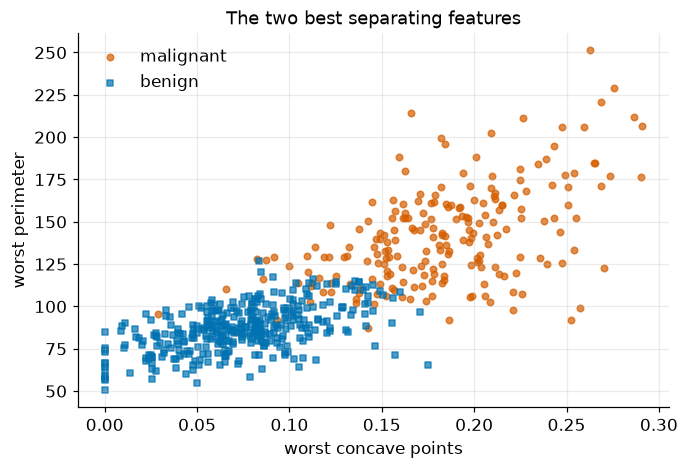


correlation of 'mean radius' and 'mean perimeter': 0.9979


In [11]:
def solution_2_8():
    import matplotlib.pyplot as plt
    from sklearn.datasets import load_breast_cancer

    bc = load_breast_cancer(as_frame=True)
    df = bc.frame
    X, t = df.drop(columns="target"), df["target"]

    # (a) classes
    print("target names (index = code):", dict(enumerate(bc.target_names.tolist())))
    print("samples per class:", t.value_counts().sort_index().to_dict())

    # (b) standardized difference between the class means (pooled standard deviation)
    n0, n1 = (t == 0).sum(), (t == 1).sum()
    m0, m1 = X[t == 0].mean(), X[t == 1].mean()
    pooled = np.sqrt(((n0 - 1) * X[t == 0].var() + (n1 - 1) * X[t == 1].var()) / (n0 + n1 - 2))
    d = ((m0 - m1).abs() / pooled).sort_values(ascending=False)
    print("\nfive best separating features:")
    print(d.head(5).round(2).to_string())
    print("\nthree worst:")
    print(d.tail(3).round(2).to_string())

    # (c) scatter plot of the two best features
    f1, f2 = d.index[:2]
    fig, ax = plt.subplots(figsize=(6.4, 4.4))
    for code, color, marker in [(0, VERMILION, "o"), (1, BLUE, "s")]:
        sel = t == code
        ax.scatter(X.loc[sel, f1], X.loc[sel, f2], s=18, color=color, marker=marker, alpha=0.7, label=bc.target_names[code])
    ax.set(xlabel=f1, ylabel=f2, title="The two best separating features")
    ax.legend(frameon=False)
    fig.tight_layout()
    plt.show()

    # (d) redundancy between two features
    print(f"\ncorrelation of 'mean radius' and 'mean perimeter': {df['mean radius'].corr(df['mean perimeter']):.4f}")

solution_2_8()

(a) The data set has 212 malignant tumors (code 0) and 357 benign ones (code 1). (b) The features describing the "worst" (largest) values of the concave points, the perimeter, and the radius, together with the mean concave points, separate the classes best: the class means differ by 2.5 to 2.7 pooled standard deviations, and the mean perimeter is fifth with 2.3. The worst features, the symmetry error, the texture error, and the mean fractal dimension, have a difference of at most 0.03 pooled standard deviations: the two classes look the same in these variables, taken one at a time. (c) In the scatter plot the two classes form two clouds with only a small overlap. (d) The correlation between `mean radius` and `mean perimeter` is 0.998: the perimeter of a nearly round tumor is just $2\pi$ times its radius, so the two columns carry the same information. A linear model with both features has almost linearly dependent columns (Exercise 1.10): the weights become unstable and hard to interpret, which is one of the reasons for the regularization of Chapter 6 and the feature selection of Chapter 10.

  n   uniform  exponential
  1    0.0577       0.1587
  2    0.0171       0.0956
  3    0.0106       0.0776
  5    0.0063       0.0611
 10    0.0033       0.0443

slope of log(KS) against log(n): uniform -1.21, exponential -0.54


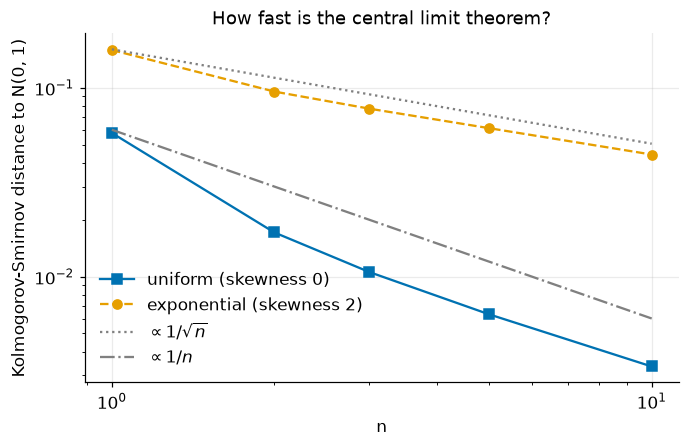

In [12]:
def solution_2_9():
    import matplotlib.pyplot as plt
    from scipy import stats

    rng = np.random.default_rng(SEED)
    reps, ns = 200_000, [1, 2, 3, 5, 10]
    uniform = rng.random((reps, max(ns)))                 # mean 1/2, standard deviation sqrt(1/12)
    exponential = rng.exponential(1.0, size=(reps, max(ns)))   # mean 1, standard deviation 1

    def ks_distance(samples, mu, sigma, n):
        z = (samples[:, :n].mean(axis=1) - mu) * np.sqrt(n) / sigma
        return stats.kstest(z, "norm").statistic

    ks_uniform = np.array([ks_distance(uniform, 0.5, np.sqrt(1 / 12), n) for n in ns])
    ks_expon = np.array([ks_distance(exponential, 1.0, 1.0, n) for n in ns])

    print(f"{'n':>3} {'uniform':>9} {'exponential':>12}")
    for n, a, b in zip(ns, ks_uniform, ks_expon):
        print(f"{n:>3} {a:>9.4f} {b:>12.4f}")
    slope_u = np.polyfit(np.log(ns), np.log(ks_uniform), 1)[0]
    slope_e = np.polyfit(np.log(ns), np.log(ks_expon), 1)[0]
    print(f"\nslope of log(KS) against log(n): uniform {slope_u:.2f}, exponential {slope_e:.2f}")

    fig, ax = plt.subplots(figsize=(6.4, 4.2))
    ax.loglog(ns, ks_uniform, "s-", color=BLUE, label="uniform (skewness 0)")
    ax.loglog(ns, ks_expon, "o--", color=ORANGE, label="exponential (skewness 2)")
    grid = np.array(ns, dtype=float)
    ax.loglog(grid, 0.16 / np.sqrt(grid), ":", color="gray", label=r"$\propto 1/\sqrt{n}$")
    ax.loglog(grid, 0.06 / grid, "-.", color="gray", label=r"$\propto 1/n$")
    ax.set(xlabel="n", ylabel="Kolmogorov-Smirnov distance to N(0, 1)", title="How fast is the central limit theorem?")
    ax.legend(frameon=False)
    fig.tight_layout()
    plt.show()

solution_2_9()

The distance to the Gaussian shrinks for both distributions, but at different speeds: the slope on the log-log plot is about $-0.54$ for the exponential distribution (close to the $-1/2$ of an error proportional to $1/\sqrt{n}$) and about $-1.2$ for the uniform one, whose error shrinks like $1/n$ (the fitted slopes are estimates, and for the uniform at $n = 10$ the distance, about 0.003, is already close to the noise level of the experiment, of the order of $1/\sqrt{200{,}000}$). The explanation is the **skewness**. The leading error term in the central limit theorem is proportional to the skewness of the original distribution divided by $\sqrt{n}$. The exponential distribution is strongly skewed (skewness 2), so this term is present; the uniform distribution is symmetric (skewness 0), the term vanishes, and the next one, of order $1/n$, dominates. In practice: for symmetric, light-tailed data the Gaussian approximation of an average is excellent already with a handful of samples; for skewed or heavy-tailed data it needs many more.

In [13]:
def solution_2_10():
    from sklearn.datasets import load_wine
    from sklearn.feature_selection import SelectKBest, f_classif
    from sklearn.model_selection import train_test_split
    from sklearn.neighbors import KNeighborsClassifier
    from sklearn.pipeline import make_pipeline
    from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler

    X, y = load_wine(return_X_y=True)
    seeds = range(30)

    # (a) scalers and k
    def mean_accuracy(make_model, k):
        scores = []
        for seed in seeds:
            X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, stratify=y, random_state=seed)
            scores.append(make_model(k).fit(X_tr, y_tr).score(X_te, y_te))
        return np.mean(scores)

    makers = {
        "no scaling":      lambda k: KNeighborsClassifier(n_neighbors=k),
        "standardization": lambda k: make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k)),
        "min-max":         lambda k: make_pipeline(MinMaxScaler(), KNeighborsClassifier(n_neighbors=k)),
        "robust":          lambda k: make_pipeline(RobustScaler(), KNeighborsClassifier(n_neighbors=k)),
    }
    table = pd.DataFrame({name: {f"k = {k}": mean_accuracy(maker, k) for k in (1, 5, 15)} for name, maker in makers.items()})
    print("(a) mean test accuracy over 30 splits:")
    print(table.round(3).to_string())

    # (b) leakage through the scaler
    print("\n(b) scaling the whole data set before splitting (leak) against the pipeline:")
    X_scaled_all = StandardScaler().fit_transform(X)                  # the mistake: statistics of the test samples are used
    for k in (1, 5, 15):
        diffs, leak_scores, ok_scores = [], [], []
        for seed in seeds:
            X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, stratify=y, random_state=seed)
            Z_tr, Z_te, _, _ = train_test_split(X_scaled_all, y, test_size=0.3, stratify=y, random_state=seed)
            leak = KNeighborsClassifier(n_neighbors=k).fit(Z_tr, y_tr).score(Z_te, y_te)
            ok = makers["standardization"](k).fit(X_tr, y_tr).score(X_te, y_te)
            leak_scores.append(leak); ok_scores.append(ok); diffs.append(leak - ok)
        print(f"  k = {k:>2}: leak {np.mean(leak_scores):.4f} | pipeline {np.mean(ok_scores):.4f} | "
              f"difference {np.mean(diffs):+.4f} (std over splits {np.std(diffs):.4f})")

    # (c) leakage through label-based feature selection, on pure noise
    rng = np.random.default_rng(SEED)
    leak_scores, ok_scores = [], []
    for rep in range(30):
        X_noise = rng.normal(size=(60, 2000))
        y_noise = rng.integers(0, 2, size=60)                          # random labels: nothing can be learned
        X_sel = SelectKBest(f_classif, k=10).fit_transform(X_noise, y_noise)     # the mistake: selection sees all labels
        X_tr, X_te, y_tr, y_te = train_test_split(X_sel, y_noise, test_size=0.3, random_state=rep)
        leak_scores.append(KNeighborsClassifier(n_neighbors=5).fit(X_tr, y_tr).score(X_te, y_te))
        X_tr, X_te, y_tr, y_te = train_test_split(X_noise, y_noise, test_size=0.3, random_state=rep)
        pipe = make_pipeline(SelectKBest(f_classif, k=10), KNeighborsClassifier(n_neighbors=5))
        ok_scores.append(pipe.fit(X_tr, y_tr).score(X_te, y_te))
    print("\n(c) pure noise, selection of 10 features out of 2000, 5-NN, 30 repetitions:")
    print(f"  selection before the split (leak): accuracy {np.mean(leak_scores):.3f} +/- {np.std(leak_scores):.3f}")
    print(f"  selection inside the pipeline    : accuracy {np.mean(ok_scores):.3f} +/- {np.std(ok_scores):.3f}")

solution_2_10()

(a) mean test accuracy over 30 splits:
        no scaling  standardization  min-max  robust
k = 1        0.733            0.953    0.955   0.948
k = 5        0.699            0.960    0.960   0.947
k = 15       0.691            0.962    0.968   0.953

(b) scaling the whole data set before splitting (leak) against the pipeline:
  k =  1: leak 0.9531 | pipeline 0.9531 | difference +0.0000 (std over splits 0.0000)


  k =  5: leak 0.9593 | pipeline 0.9605 | difference -0.0012 (std over splits 0.0095)
  k = 15: leak 0.9605 | pipeline 0.9617 | difference -0.0012 (std over splits 0.0082)



(c) pure noise, selection of 10 features out of 2000, 5-NN, 30 repetitions:
  selection before the split (leak): accuracy 0.820 +/- 0.067
  selection inside the pipeline    : accuracy 0.520 +/- 0.093


(a) Without scaling the accuracy is about 0.70 to 0.73; with any of the three scalers it is about 0.95 to 0.97. Standardization and min-max scaling are practically equivalent on this data set (min-max is slightly better for $k = 15$), and the robust scaler is a bit behind. The best $k$ depends on the scaler, which is a first hint that $k$ must be tuned (Chapter 5).

(b) Scaling the whole data set before the split gives results that differ from the correct pipeline by about $0.001$ or less on average, with a standard deviation over the splits of about 0.01 (for $k = 1$ the accuracies are even identical on every split): the difference is not systematic, it is lost in the noise. The reason is that the mean and standard deviation of 178 samples hardly change when 30% of the samples are left out: a scaler learns very little from the data. This is why leakage through scalers often goes unnoticed. It would be a mistake to conclude that the rule is unimportant.

(c) On random labels no method can be better than chance, so the correct accuracy is 0.5, and the pipeline indeed gives about 0.52. The "leaky" procedure reaches about 0.82: among 2000 random features, some happen to correlate with the random labels *of the whole data set, test samples included*, and keeping the ten best of them builds the test labels into the features. The model seems to have found real structure and has found none. The more the preprocessing step *learns*, in particular when it uses the labels, the larger the leak: **every step that is fitted must be inside the pipeline.**

## C.3 Chapter 3

### Manual exercises

**Solution 3.1 — The Bayes classifier with unequal priors.**

(a) With $\pi_0 = 0.8$, $\pi_1 = 0.2$, the Bayes classifier predicts class 1 when $\pi_1 p_1(x) > \pi_0 p_0(x)$:
$$
0.2\,e^{-(x-2)^2/2} > 0.8\,e^{-x^2/2}
\iff -\tfrac{(x-2)^2}{2} + \tfrac{x^2}{2} > \ln 4
\iff 2x - 2 > \ln 4
\iff x > 1 + \tfrac{\ln 4}{2} \approx 1.693.
$$
The threshold is **not** the midpoint $x = 1$: the rarer class must be more convincing, so the boundary moves toward its mean by $\sigma^2\ln(\pi_0/\pi_1)/(\mu_1 - \mu_0) = 0.693$.

(b) With $t = 1 + \tfrac{\ln 4}{2}$, the two error probabilities are $\mathbb{P}(x > t \mid y = 0) = 1 - \Phi(t) = 0.0452$ and $\mathbb{P}(x \le t \mid y = 1) = \Phi(t - 2) = \Phi(-0.307) = 0.3795$, so
$$
R^\ast = 0.8 \cdot 0.0452 + 0.2 \cdot 0.3795 = 0.1121.
$$

(c) "Always predict 0" is wrong exactly on class 1: $R = 0.2$. The midpoint rule has $R = 0.8\,(1 - \Phi(1)) + 0.2\,\Phi(-1) = \Phi(-1) = 0.1587$ (the two error probabilities are equal, so the priors do not matter). The Bayes classifier, with $0.1121$, is better than both: ignoring the priors costs $0.1587 - 0.1121 = 0.0466$, and ignoring the input entirely costs $0.2 - 0.1121 = 0.0879$.

**Solution 3.2 — Which prediction does each loss prefer?**

(a) Add and subtract $\eta(\mathbf{x})$ inside the square:
$$
(y - f)^2 = (y - \eta)^2 + 2\,(y - \eta)(\eta - f) + (\eta - f)^2 .
$$
Condition on $\mathbf{x}$: $\eta(\mathbf{x})$ and $f(\mathbf{x})$ are constants, and $\mathbb{E}[y - \eta(\mathbf{x}) \mid \mathbf{x}] = 0$, so the expectation of the cross term is $\mathbb{E}\big[2\,(\eta - f)\,\mathbb{E}[y - \eta \mid \mathbf{x}]\big] = 0$. Taking the expectation of the other two terms gives the result. Its first term is $R^\ast$ and does not depend on $f$; the second is non-negative and zero only for $f = \eta$.

(b) For $y$ uniform on $\{0, 1, 10\}$ the mean is $11/3 = 3.667$ and the variance is $101/3 - (11/3)^2 = 20.22$. The squared loss $\mathbb{E}[(y - a)^2] = 20.22 + (a - 3.667)^2$ is minimized by the **mean** $a = 3.667$. The expected absolute loss is piecewise linear in $a$ with kinks at the data values; its slope is $\tfrac13(\#\{y_i < a\} - \#\{y_i > a\})$, negative for $a < 1$ and positive for $a > 1$, so the minimum is at the **median** $a = 1$.

| Constant | $\mathbb{E}[(y - a)^2]$ | $\mathbb{E}\lvert y - a\rvert$ |
|---|---|---|
| mean, $a = 3.667$ | **20.22** | 4.22 |
| median, $a = 1$ | 27.33 | **3.33** |

Each constant wins on its own loss. The outlier (the value 10) drags the mean away from the bulk of the data and contributes with its *square* to the squared loss; the median is not moved by how far the outlier is. This is the reason why the absolute loss is called *robust*, and why the choice of the loss is part of the specification of the problem.

**Solution 3.3 — Sizing a test set.** Here $\varepsilon = 0.03$ and $\delta = 0.05$.

(a) Hoeffding: $n \ge \ln(2/\delta)/(2\varepsilon^2) = \ln 40/0.0018 = 2049.4$, so **2050** examples.

(b) Chebyshev, with $\sigma^2 \le \tfrac14$: $n \ge \sigma^2/(\varepsilon^2\delta) = 0.25/(0.0009 \cdot 0.05) = 5555.6$, so **5556** examples: 2.7 times more than Hoeffding.

(c) With $p = 0.05$, $\sigma^2 = p(1 - p) = 0.0475$ and $n \ge 0.0475/(0.0009 \cdot 0.05) = 1055.6$, so **1056** examples, about half of the Hoeffding value. Hoeffding uses only the range $[0, 1]$ of the variable, and must hold for the *worst* variable of that range ($p = \tfrac12$, variance $\tfrac14$); Chebyshev uses the actual variance, which for a rare event is 5 times smaller. The ratio of the two sample sizes is $2\sigma^2/(\delta\ln(2/\delta))$, which is $0.51$ here. Chebyshev's dependence on $\delta$ is much worse ($1/\delta$ instead of $\ln(1/\delta)$), so for a smaller $\delta$ Hoeffding wins again: with $\delta = 10^{-4}$ it needs 5,502 examples against 527,778 for Chebyshev with the same variance $0.0475$. (Bernstein's inequality, not covered here, uses the variance *and* has the logarithmic dependence on $\delta$.)

(d) For $m = 1000$: $\sqrt{\ln(40)/2000} = 0.043$, that is $\pm 4.3$ percentage points.

**Solution 3.4 — The realizable case.**

(a) Call a function $f$ **bad** if $R(f) > \varepsilon$. A bad function is consistent with one random example with probability $1 - R(f) < 1 - \varepsilon$, and with all $n$ independent examples with probability at most $(1 - \varepsilon)^n \le e^{-\varepsilon n}$ (because $1 - u \le e^{-u}$). The ERM output has zero training error, so if $R(\hat f) > \varepsilon$ some bad function is consistent with the whole sample. By the union bound over at most $\lvert\mathcal{H}\rvert$ bad functions, $\mathbb{P}(R(\hat f) > \varepsilon) \le \lvert\mathcal{H}\rvert\,e^{-\varepsilon n}$.

(b) Setting $\lvert\mathcal{H}\rvert\,e^{-\varepsilon n} \le \delta$ gives $n \ge (\ln\lvert\mathcal{H}\rvert + \ln(1/\delta))/\varepsilon$. For the conjunctions, $\ln 3^{10} = 10.99$ and $\ln(1/0.01) = 4.61$, so $n \ge 15.59/0.05 = 311.8$: **312 examples**.

(c) In the agnostic case Corollary 3.2 gives an estimation error of at most $2\varepsilon'$ with $\varepsilon' = \sqrt{(\ln\lvert\mathcal{H}\rvert + \ln(2/\delta))/(2n)}$; setting $2\varepsilon' = 0.05$ gives $n \ge 4\,(\ln\lvert\mathcal{H}\rvert + \ln(2/\delta))/(2 \cdot 0.05^2) = 4 \cdot 16.28/0.005 =$ **13,028 examples**, about 42 times more. The difference is in the dependence on the accuracy: **$1/\varepsilon$** when the training error can be zero, **$1/\varepsilon^2$** in general. In the realizable case a function with true risk $\varepsilon$ is eliminated very quickly, because a mistake on it is *certain* to appear in the sample if it is made often enough; in the agnostic case the empirical risks of good and almost good functions differ by amounts of order $\varepsilon$ that fluctuate with standard deviation of order $1/\sqrt{n}$, and telling them apart takes $n \sim 1/\varepsilon^2$.

**Solution 3.5 — Why $\sqrt{\ln m}$?**

(a) For any $s > 0$, Jensen's inequality for the convex function $z \mapsto e^{sz}$ gives
$$
e^{s\,\mathbb{E}[\max_j Z_j]} \le \mathbb{E}\big[e^{s\max_j Z_j}\big] = \mathbb{E}\big[\max_j e^{sZ_j}\big] \le \sum_{j=1}^m \mathbb{E}\big[e^{sZ_j}\big] \le m\,e^{s^2\sigma^2/2}.
$$
(The maximum of non-negative numbers is at most their sum; this is the union bound in disguise, and requires no independence.) Taking logarithms and dividing by $s$,
$$
\mathbb{E}\big[\max_j Z_j\big] \le \frac{\ln m}{s} + \frac{s\sigma^2}{2}.
$$
The right-hand side is minimized at $s = \sqrt{2\ln m}/\sigma$, where it equals $\sigma\sqrt{2\ln m}$. (For $m = 1$ the bound is $0$, which also follows from $s \to 0$.)

(b) Let $Z_j = \mu - \hat{R}_j = \tfrac1n\sum_{i=1}^n(\mu - \ell_{ji})$ be an average of $n$ independent centered variables, where each term $(\mu - \ell_{ji})/n$ lies in an interval of length $1/n$. By Hoeffding's lemma each term has $\mathbb{E}[e^{s(\mu - \ell_{ji})/n}] \le e^{s^2/(8n^2)}$, and the product of the $n$ independent factors is $\mathbb{E}[e^{sZ_j}] \le e^{s^2/(8n)}$, which is the hypothesis of (a) with $\sigma^2 = 1/(4n)$. Hence
$$
\mathbb{E}\big[\mu - \min_j\hat{R}_j\big] = \mathbb{E}\big[\max_j Z_j\big] \le \sqrt{\tfrac{1}{4n}}\sqrt{2\ln m} = \sqrt{\frac{\ln m}{2n}},
$$
the thin curves of Figure 3.4. Observe that independence *across candidates* was never used: the bound holds even if the $m$ candidates are strongly correlated (in that case it is just less tight). Only the *number* of candidates enters, through a logarithm, which is why we can afford enormous finite classes: $10^6$ candidates cost only $\sqrt{13.8/(2n)}$.

### Python exercises

In [14]:
def solution_3_6():
    from scipy import stats

    Sigma = np.array([[1.0, 0.5], [0.5, 1.0]])
    mu0, mu1 = np.array([0.0, 0.0]), np.array([2.0, 1.0])

    # (a) direction and threshold of the Bayes classifier (equal priors, equal covariances)
    w = np.linalg.solve(Sigma, mu1 - mu0)
    threshold = w @ (mu0 + mu1) / 2
    print(f"(a) w = {w.round(4)}, threshold = {threshold:.4f}: predict class 1 when w'x > threshold")

    # (b) Bayes risk from the Mahalanobis distance
    delta = np.sqrt((mu1 - mu0) @ w)
    print(f"(b) Delta = {delta:.4f}, Bayes risk Phi(-Delta/2) = {stats.norm.cdf(-delta / 2):.4f}")

    # (c) Monte Carlo
    rng = np.random.default_rng(SEED)
    n = 1_000_000
    y = rng.integers(0, 2, size=n)
    X = rng.multivariate_normal([0, 0], Sigma, size=n) + np.where(y[:, None] == 1, mu1, mu0)
    err_bayes = np.mean((X @ w > threshold) != y)
    print(f"(c) Monte Carlo risk of the Bayes classifier, n = 10^6: {err_bayes:.4f}")

    # (d) classifiers that use a single feature (threshold at the midpoint of the two means of that feature)
    for j in range(2):
        pred = X[:, j] > (mu0[j] + mu1[j]) / 2
        theory = stats.norm.cdf(-abs(mu1[j] - mu0[j]) / (2 * np.sqrt(Sigma[j, j])))
        print(f"(d) feature x{j + 1} alone: Monte Carlo {np.mean(pred != y):.4f}, theory Phi(-|dmu|/(2 sigma)) = {theory:.4f}")

    # Why x2 adds nothing: E[x2 | x1] is the same line in both classes
    slope = Sigma[0, 1] / Sigma[0, 0]
    for k, mu in enumerate((mu0, mu1)):
        print(f"E[x2 | x1, class {k}] = {mu[1] - slope * mu[0]:.1f} + {slope:.1f} x1")


solution_3_6()

(a) w = [2. 0.], threshold = 2.0000: predict class 1 when w'x > threshold
(b) Delta = 2.0000, Bayes risk Phi(-Delta/2) = 0.1587
(c) Monte Carlo risk of the Bayes classifier, n = 10^6: 0.1590
(d) feature x1 alone: Monte Carlo 0.1590, theory Phi(-|dmu|/(2 sigma)) = 0.1587
(d) feature x2 alone: Monte Carlo 0.3085, theory Phi(-|dmu|/(2 sigma)) = 0.3085
E[x2 | x1, class 0] = 0.0 + 0.5 x1
E[x2 | x1, class 1] = 0.0 + 0.5 x1


(a) For equal covariances and equal priors the Bayes classifier is linear: $\mathbf{w} = \boldsymbol\Sigma^{-1}(\boldsymbol\mu_1 - \boldsymbol\mu_0) = (2, 0)^\top$ and the threshold is $\mathbf{w}^\top(\boldsymbol\mu_0 + \boldsymbol\mu_1)/2 = 2$: predict class 1 when $2x_1 > 2$, that is $x_1 > 1$. The classifier **does not use $x_2$ at all**. (b) $\Delta^2 = \mathbf{w}^\top(\boldsymbol\mu_1 - \boldsymbol\mu_0) = 4$, so $R^\ast = \Phi(-1) = 0.1587$, and (c) the Monte Carlo value $0.1590$ agrees within the sampling error (about $0.0004$ for $10^6$ points).

(d) The feature $x_1$ alone reaches the Bayes risk, $0.1587$; the feature $x_2$ alone gives $\Phi(-0.5) = 0.3085$, which is much better than chance. Both facts are consistent: $x_2$ *is* informative by itself, because it is correlated with $x_1$ and the class shifts both means, but **given $x_1$ it adds nothing**, since the conditional mean $\mathbb{E}[x_2 \mid x_1] = 0.5\,x_1$ is the same line in the two classes. This is the first example of a principle that will return in feature selection (Chapter 10): the usefulness of a feature depends on which other features are already available.

In [15]:
def solution_3_7():
    rng = np.random.default_rng(SEED)
    sigma = 0.3

    def draw(n):
        x = rng.uniform(0, 1, n)
        return x, np.sin(2 * np.pi * x) + rng.normal(0, sigma, n)

    x_big, y_big = draw(100_000)
    x_test, y_test = draw(100_000)
    rows = []
    for m in (1, 3, 6):
        f_H = np.polyfit(x_big, y_big, m)
        risk_H = np.mean((y_test - np.polyval(f_H, x_test)) ** 2)
        approx = risk_H - sigma ** 2
        for n in (30, 300):
            risks = []
            for _ in range(300):
                x, y = draw(n)
                coef = np.polyfit(x, y, m)
                risks.append(np.mean((y_test - np.polyval(coef, x_test)) ** 2))
            rows.append({"degree m": m, "n": n, "R(f_H)": risk_H, "approximation": approx,
                         "E[R(f_S)]": np.mean(risks), "estimation": np.mean(risks) - risk_H,
                         "median R(f_S)": np.median(risks)})
    table = pd.DataFrame(rows)
    print(f"Bayes risk R* = {sigma ** 2:.4f}")
    print(table.round(4).to_string(index=False))


solution_3_7()

Bayes risk R* = 0.0900
 degree m   n  R(f_H)  approximation  E[R(f_S)]  estimation  median R(f_S)
        1  30  0.2830         0.1930     0.3044      0.0214         0.2981
        1 300  0.2830         0.1930     0.2851      0.0021         0.2845
        3  30  0.0942         0.0042     0.1110      0.0168         0.1065
        3 300  0.0942         0.0042     0.0956      0.0014         0.0953
        6  30  0.0899        -0.0001     0.1911      0.1012         0.1180
        6 300  0.0899        -0.0001     0.0921      0.0022         0.0919


The approximation errors are $0.193$ for lines ($m = 1$, a sine period cannot be fitted by a line), $0.004$ for cubics and about zero for $m = 6$ (the value $-0.0001$ is a Monte Carlo error; the sine is almost exactly a degree-6 polynomial on $[0, 1]$). The estimation error is the opposite: it is largest for the richest class and shrinks with $n$.

At $n = 30$ the best degree is $m = 3$ (mean risk $0.111$ against $0.304$ for $m = 1$ and $0.191$ for $m = 6$), at $n = 300$ it is $m = 6$ ($0.0921$ against $0.0956$ for $m = 3$): **the best complexity grows with the sample size**, as in Figure 3.3. The mean risk of $m = 6$ at $n = 30$ is much larger than its median ($0.191$ against $0.118$): a few of the 300 samples produce a polynomial that oscillates wildly near the edges of $[0, 1]$ and has an enormous risk. This is *variance* in its purest form, a rich class reacting to the idiosyncrasies of one small sample; a degree-9 polynomial fitted to 20 points has such an extreme mean risk, dominated by a handful of samples, that the mean is meaningless. Chapter 4 formalizes it with the bias–variance decomposition.

In [16]:
def solution_3_8():
    from itertools import product

    def dichotomies(points, rule_family):
        return len({tuple(rule(x) for x in points) for rule in rule_family(points)})

    def half_lines(points):                       # I[x > t]: thresholds between consecutive points
        cuts = np.concatenate(([points[0] - 1], (points[:-1] + points[1:]) / 2, [points[-1] + 1]))
        return [lambda x, t=t: int(x > t) for t in cuts]

    def interval_complements(points):             # I[x < a or x > b]
        cuts = np.concatenate(([points[0] - 1], (points[:-1] + points[1:]) / 2, [points[-1] + 1]))
        return [lambda x, a=a, b=b: int(x < a or x > b) for a in cuts for b in cuts if a <= b]

    print(" n | half-lines | n+1 | complements of intervals | n(n+1)/2+1")
    for n in range(1, 9):
        pts = np.arange(n, dtype=float)
        print(f"{n:>2} | {dichotomies(pts, half_lines):>10} | {n + 1:>3} | {dichotomies(pts, interval_complements):>24} | {n * (n + 1) // 2 + 1:>10}")

    # (b) sign(sin(omega x)) shatters x_j = 10^-j
    m = 6
    x = 10.0 ** -np.arange(1, m + 1)
    ok = 0
    for labels in product([-1, 1], repeat=m):
        b = (1 - np.array(labels)) / 2
        omega = np.pi * (1 + np.sum(b * 10.0 ** np.arange(1, m + 1)))
        ok += np.all(np.sign(np.sin(omega * x)) == np.array(labels))
    print(f"\nsign(sin(omega x)) reproduces {ok} of {2 ** m} labelings of the {m} points x_j = 10^-j")


solution_3_8()

 n | half-lines | n+1 | complements of intervals | n(n+1)/2+1
 1 |          2 |   2 |                        2 |          2
 2 |          3 |   3 |                        4 |          4
 3 |          4 |   4 |                        7 |          7
 4 |          5 |   5 |                       11 |         11
 5 |          6 |   6 |                       16 |         16
 6 |          7 |   7 |                       22 |         22
 7 |          8 |   8 |                       29 |         29
 8 |          9 |   9 |                       37 |         37

sign(sin(omega x)) reproduces 64 of 64 labelings of the 6 points x_j = 10^-j


(a) For $n$ distinct points on a line the half-lines produce $n + 1$ dichotomies (the threshold falls in one of the $n + 1$ gaps), so $\Pi(n) = n + 1$; since $\Pi(2) = 3 < 2^2$, no pair of points is shattered and $d_{\mathrm{VC}} = 1$. The complements of intervals produce $n(n + 1)/2 + 1$ dichotomies, exactly as the intervals do: the points labeled 0 form a contiguous block, which is empty or one of the $n(n+1)/2$ possible blocks. For $n = 2$ all four labelings are possible, but for $n = 3$ the labeling $(0, 1, 0)$ is not (its zeros are not contiguous), so $\Pi(3) = 7 < 8$ and $d_{\mathrm{VC}} = 2$. Both counts agree with the output above.

(b) The table confirms that all $2^6 = 64$ labelings of $x_j = 10^{-j}$ are reproduced by $\mathrm{sign}(\sin(\omega x))$ with the prescribed $\omega$. The proof for general $m$ is the one outlined in the hint: for $i > j$ the term $\pi b_i 10^{i-j}$ is an even multiple of $\pi$ (it is $\pi$ times a multiple of 10) and does not change the sign of the sine; the term $i = j$ gives $\pi b_j$; the terms with $i < j$ add up to less than $\pi/5$ and the term $\pi 10^{-j}$ is smaller still. So the argument of the sine lies in $(\pi b_j, \pi b_j + \pi/2) \bmod 2\pi$, where the sign is $+$ for $b_j = 0$ and $-$ for $b_j = 1$. A class with a single parameter can therefore shatter arbitrarily large sets: the **number of parameters is not the capacity**.

In [17]:
def solution_3_9():
    from sklearn.datasets import load_breast_cancer
    from sklearn.preprocessing import StandardScaler

    rng = np.random.default_rng(SEED)
    X30 = StandardScaler().fit_transform(load_breast_cancer().data)[rng.choice(569, 100, replace=False)]
    n = 100
    sigmas = rng.choice([-1.0, 1.0], size=(2000, n))
    rows = []
    for d in (30, 100, 300, 1000, 3000):
        X = np.hstack([X30, rng.normal(size=(n, d - 30))])
        S = sigmas @ X                                                   # 2000 x d: the sums sum_i sigma_i x_ij
        r2 = np.mean(np.linalg.norm(S, axis=1)) / n
        r1 = np.mean(np.max(np.abs(S), axis=1)) / n
        b2 = np.sqrt(np.sum(X ** 2)) / n
        b1 = np.max(np.linalg.norm(X, axis=0)) * np.sqrt(2 * np.log(2 * d)) / n
        rows.append({"d": d, "l2 ball": r2, "bound l2": b2, "l1 ball": r1, "bound l1": b1})
    table = pd.DataFrame(rows)
    print(table.round(4).to_string(index=False))
    print(f"\nl2 complexity grows by a factor {table['l2 ball'].iloc[-1] / table['l2 ball'].iloc[0]:.2f} from d = 30 to d = 3000 "
          f"(sqrt(3000/30) = {np.sqrt(100):.0f});")
    print(f"l1 complexity grows by a factor {table['l1 ball'].iloc[-1] / table['l1 ball'].iloc[0]:.2f}")


solution_3_9()

   d  l2 ball  bound l2  l1 ball  bound l1
  30   0.5202    0.5487   0.1873    0.3655
 100   0.9961    1.0019   0.2685    0.4157
 300   1.7337    1.7370   0.3071    0.4568
1000   3.1594    3.1607   0.3432    0.4979
3000   5.4748    5.4762   0.3732    0.5327

l2 complexity grows by a factor 10.52 from d = 30 to d = 3000 (sqrt(3000/30) = 10);
l1 complexity grows by a factor 1.99


The $\ell_2$ complexity grows like $\sqrt{d}$ (a factor 10.5 from $d = 30$ to $d = 3000$, against $\sqrt{100} = 10$) and the bound $\sqrt{\sum_i\lVert\mathbf{x}_i\rVert^2}/n$ is nearly exact, because the squared norms of the rows are dominated by the $d - 30$ noise coordinates, whose squares add up to about $d$ per row. The point of Proposition 3.6 is that the bound depends on the *norm* of the data and not on the dimension: if the norm grows with $d$, as it does when we append noise columns, so does the bound, and **bounding $\lVert\mathbf{w}\rVert_2 \le 1$ does not protect against a large number of irrelevant features of order 1 each**. The $\ell_1$ complexity grows only by a factor of 2, as $\sqrt{\ln 2d}$ (the maximum over $2d$ signed columns, each of which behaves like a Gaussian with the same variance proxy) and the bound follows with a small slack (ratio between 1.4 and 2). This is the mathematical reason why $\ell_1$ regularization (Lasso, Chapter 10) works well when there are many irrelevant features, *provided that the true weight vector has a small $\ell_1$ norm*, that is, that it is sparse.

In [18]:
def solution_3_10():
    from scipy import stats

    rng = np.random.default_rng(SEED)
    z = stats.norm.ppf(0.975)
    reps = 20_000
    rows = []
    for p in (0.03, 0.2):
        for m in (20, 50, 200):
            K = rng.binomial(m, p, size=reps)
            ph = K / m
            hoeff = np.sqrt(np.log(2 / 0.05) / (2 * m)) * np.ones(reps)
            wald = z * np.sqrt(ph * (1 - ph) / m)
            centre = (ph + z ** 2 / (2 * m)) / (1 + z ** 2 / m)
            half_w = z * np.sqrt(ph * (1 - ph) / m + z ** 2 / (4 * m ** 2)) / (1 + z ** 2 / m)
            for name, lo, hi in [("Hoeffding", ph - hoeff, ph + hoeff), ("Wald", ph - wald, ph + wald),
                                 ("Wilson", centre - half_w, centre + half_w)]:
                rows.append({"p": p, "m": m, "interval": name, "coverage": np.mean((lo <= p) & (p <= hi)),
                             "mean width": np.mean(hi - lo)})
    table = pd.DataFrame(rows).pivot(index=["p", "m"], columns="interval", values=["coverage", "mean width"])
    print(table.round(3).to_string())


solution_3_10()

          coverage               mean width              
interval Hoeffding   Wald Wilson  Hoeffding   Wald Wilson
p    m                                                   
0.03 20      1.000  0.458  0.979      0.607  0.097  0.198
     50      1.000  0.784  0.937      0.384  0.081  0.109
     200     1.000  0.933  0.944      0.192  0.046  0.049
0.20 20      1.000  0.924  0.957      0.607  0.335  0.326
     50      0.999  0.935  0.950      0.384  0.218  0.215
     200     1.000  0.941  0.959      0.192  0.110  0.110


**Hoeffding's interval is valid but very conservative**: its coverage is 1.000 (or 0.999) in every row, much above the nominal 0.95, and it is two to five times wider than the others (a half-width of 0.30 for $m = 20$, which is useless for estimating an error rate of 0.03). **The Wald interval fails where it matters:** for a small error rate and a small test set its coverage is only 0.46 ($p = 0.03$, $m = 20$) and 0.78 ($m = 50$), because when $K = 0$ it collapses to a point and in general it relies on a normal approximation that is not accurate for $mp < 5$. For $p = 0.2$ and $m \ge 50$ it is fine. **The Wilson interval** has coverage close to 0.95 in all cases (0.937 to 0.979) and a width that is similar to the Wald interval where the latter works and larger where the Wald fails. It is the interval to report in practice; the Clopper–Pearson interval (`method="exact"`) is a conservative alternative that guarantees coverage at least 0.95 at the price of being slightly wider. Hoeffding's interval remains the right tool when a *guaranteed* statement without any approximation is needed, and as the formula to plan the size of a test set in advance.

## C.4 Chapter 4

### Manual exercises

**Solution 4.1 — k-NN by hand, with weights.** The distances from $x = 5$ to $1, 2, 4, 7, 9, 10$ are $4, 3, 1, 2, 4, 5$. Sorted: $x = 4$ (distance 1, label 1), $x = 7$ (2, label 1), $x = 2$ (3, label 0), then $x = 1$ and $x = 9$ **tied** at distance 4 (labels 0 and 0), and $x = 10$ (5, label 0).

(a) $k = 1$: label 1. $k = 3$: the neighbors are $4, 7, 2$ with labels $1, 1, 0$: label **1**. $k = 5$: the neighbors are $4, 7, 2, 1, 9$ (the tie at distance 4 does not matter, because both tied points enter) with labels $1, 1, 0, 0, 0$: label **0**. The prediction changes with $k$.

(b) Weighted votes with $k = 5$: class 1 receives $1/1 + 1/2 = 1.5$; class 0 receives $1/3 + 1/4 + 1/4 = 0.833$. The predicted class is **1**: the two close neighbors outweigh the three far ones, and the weighted vote is less sensitive to the choice of $k$ (it agrees with $k = 1$ and $k = 3$).

(c) With $k = 6$ all the training points vote: the labels are $0, 0, 1, 1, 0, 0$, four zeros against two ones, so the vote gives 0 **for every query whatsoever**. It is a property of the method with $k = n$, not of the query: it ignores $x$ and returns the majority class of the training set, which is the rule of the smallest flexibility (the constant predictor of Chapter 1). If the classes had been split evenly, the answer would have depended on the tie-breaking rule of the implementation, as in Worked example 4.1.

(d) The training error of 1-NN is **0**: each training point is its own nearest neighbor (distance 0). For 6-NN it is the proportion of points whose label differs from the training majority (0): $2/6 = 1/3$. The training error cannot be used to choose $k$.

**Solution 4.2 — Bias and variance at the boundary and in the interior.** With $f(x) = x$ and the formulas of Section 4.5.2:

(a) At $x_0 = 0$ the $k$ nearest neighbors are $x_1, \dots, x_k$ (that is, $0, 0.01, \dots, (k-1)/100$), whose average is $(k - 1)/200$. Hence the bias is $-(k - 1)/200$, the variance is $\sigma^2/k = 0.25/k$, and the expected squared error is
$$
0.25 + \Big(\frac{k - 1}{200}\Big)^2 + \frac{0.25}{k}.
$$
For $k = 1, 5, 11, 21, 31, 51$ it is $0.500$, $0.300$, $0.275$, $0.272$, $0.281$, $0.317$.

(b) At $x_0 = 0.5$ and odd $k$ the neighbors are symmetric around $x_0$, so the average of the linear function over them is exactly $f(x_0)$: the **bias is zero for every odd $k$**, and the error is $0.25 + 0.25/k$, which decreases with $k$ down to $0.25 + 0.25/101 = 0.2525$ for $k = 101$.

(c) At the boundary the best $k$ minimizes $((k - 1)/200)^2 + 0.25/k$; the derivative vanishes where $k^2(k - 1) = 5000$, which is $k \approx 17$ (integer minimum at $k = 17$, with an excess error of $0.0211$). In the interior the best $k$ is the largest possible, because there is no bias to pay for. A single $k$ for the whole range is therefore a compromise: $k = 17$ is too small in the interior (excess error $0.25/17 = 0.0147$, against $0.0025$ with $k = 101$), and a large $k$ is damaging at the boundary ($k = 101$: the bias is $-0.5$, so bias$^2 = 0.25$ and the excess error is $0.2525$). This is one reason why local methods that adapt the neighborhood to the location, or correct the boundary bias by fitting a *local line* instead of a local constant, are preferred in practice.

**Solution 4.3 — Cover–Hart with numbers.**

(a) $R^\ast = \tfrac12\min\{0.9, 0.1\} + \tfrac12\min\{0.2, 0.8\} = \tfrac12 (0.1) + \tfrac12 (0.2) = \mathbf{0.15}$.

(b) $R_{1\text{-NN}} = \tfrac12\cdot 2 \cdot 0.9 \cdot 0.1 + \tfrac12 \cdot 2 \cdot 0.2 \cdot 0.8 = 0.09 + 0.16 = \mathbf{0.25}$. The bound is $2R^\ast(1 - R^\ast) = 2 \cdot 0.15 \cdot 0.85 = 0.255$: the 1-NN risk is just below it, almost twice the Bayes risk (the ratio is $1.67$). The bound is nearly attained here because $r = \min(\eta, 1-\eta)$ takes the two values 0.1 and 0.2, which are close to each other; Jensen's inequality used in the proof is an equality when $r$ is constant.

(c) For $\eta = 0.9$: $p_1 = 3(0.81) - 2(0.729) = 0.972$ and the error is $0.9(0.028) + 0.1(0.972) = 0.1224$. For $\eta = 0.2$: $p_1 = 3(0.04) - 2(0.008) = 0.104$ and the error is $0.2(0.896) + 0.8(0.104) = 0.2624$. Averaging, $R_{3\text{-NN}} = \tfrac12(0.1224 + 0.2624) = \mathbf{0.1924}$.

(d) The gap between 1-NN and Bayes is $0.25 - 0.15 = 0.10$; with $k = 3$ it is $0.1924 - 0.15 = 0.0424$, so $k = 3$ closes $(0.25 - 0.1924)/0.10 = 58\%$ of the gap. Larger $k$ closes more, and the limit is the Bayes risk.

**Solution 4.4 — Counting in high dimensions.**

(a) $n s^d = 1$ with $s = 0.1$ gives $n = 10^d$: $10, 100, 10^5, 10^{10}$ and $10^{20}$ points for $d = 1, 2, 5, 10, 20$. (Ten billion points in dimension 10 just to have one neighbor within 10% of the range of every feature.)

(b) $s = (k/n)^{1/d} = (10^{-5})^{1/d}$: $0.003$ for $d = 2$, $0.316$ for $d = 10$, $0.794$ for $d = 50$ and $0.891$ for $d = 100$. With a million points, in dimension 10 the cube that contains ten points spans 32% of each range; in dimension 100, 89%.

(c) A point is *not* within $0.05$ of the boundary when all its coordinates lie in $[0.05, 0.95]$, which has probability $0.9^d$. The fraction near the boundary is $1 - 0.9^d$: $0.19$ for $d = 2$, $0.65$ for $d = 10$ and $0.995$ for $d = 50$. In high dimensions almost all the points are near the boundary of the cube, and the neighbors of a typical point are all on one side of it: the boundary effect of Figures 4.4 and 4.5, now everywhere.

**Solution 4.5 — The best $k$ in $d$ dimensions.**

(a) The bias at $\mathbf{x}_0$ is $\frac1k\sum_{i}(f(\mathbf{x}_0) - f(\mathbf{x}_i))$, and each term is at most $L\lVert\mathbf{x}_0 - \mathbf{x}_i\rVert \le Lr$ in absolute value, so $\text{bias}^2 \le L^2r^2$. The variance is $\sigma^2/k$ (Section 4.5.2). From $k = n v_d r^d$ we get $r = (k/(n v_d))^{1/d}$ and the bound $L^2\big(k/(nv_d)\big)^{2/d} + \sigma^2/k$.

(b) Differentiating, $\frac{2}{d}L^2(nv_d)^{-2/d}k^{2/d - 1} - \sigma^2k^{-2} = 0$, i.e. $k^{(d+2)/d} = \frac{d\sigma^2}{2L^2}(nv_d)^{2/d}$, and raising to the power $d/(d+2)$ gives
$$
k^\ast = \Big(\frac{d\sigma^2}{2L^2}\Big)^{d/(d+2)}(nv_d)^{2/(d+2)} .
$$
At the optimum the two terms are of the same order (the variance term is $\sigma^2/k^\ast \propto n^{-2/(d+2)}$), so the minimal bound is proportional to $n^{-2/(d+2)}$.

(c) To halve a bound that is $\propto n^{-2/(d+2)}$ the sample size must be multiplied by $2^{(d+2)/2}$: $2.8$ for $d = 1$, $4$ for $d = 2$, $11.3$ for $d = 5$ and $64$ for $d = 10$.

(d) For $n = 10^4$, $L = \sigma = 1$: $k^\ast = 585$ for $d = 1$ (a fraction $0.058$ of the data), $43$ for $d = 5$ and $21$ for $d = 10$, with bounds $0.0026$, $0.081$ and $0.289$ on the excess error (for a noise variance of 1). In dimension 10, even with 10,000 points the best neighborhood contains only 21 points and has a radius $r = (21/(10^4 \cdot 2.55))^{1/10} = 0.48$, about half of the range of each feature: the Lipschitz assumption is then not enough to say that the function is nearly constant in the neighborhood, and the guarantee is poor. (The bound is an upper bound and real problems are often easier, as Digits shows; but the exponent $2/(d+2)$ cannot be improved without assumptions beyond Lipschitz continuity.)

### Python exercises

In [19]:
def solution_4_6():
    from sklearn.datasets import load_diabetes
    from sklearn.model_selection import train_test_split
    from sklearn.neighbors import KNeighborsRegressor

    X, y = load_diabetes(return_X_y=True)

    def knn_regress(X_train, y_train, X_test, k):
        """k-NN regression with the Euclidean distance: average of the targets of the k nearest training points."""
        sq_train, sq_test = (X_train ** 2).sum(axis=1), (X_test ** 2).sum(axis=1)
        D2 = sq_test[:, None] + sq_train[None, :] - 2 * X_test @ X_train.T
        nearest = np.argpartition(D2, kth=k - 1, axis=1)[:, :k]
        return y_train[nearest].mean(axis=1)

    k, agree, mse_ours, mse_sk = 20, [], [], []
    for seed in range(30):
        Xa, Xb, ya, yb = train_test_split(X, y, test_size=0.3, random_state=seed)
        ours = knn_regress(Xa, ya, Xb, k)
        theirs = KNeighborsRegressor(n_neighbors=k).fit(Xa, ya).predict(Xb)
        agree.append(np.mean(np.isclose(ours, theirs)))
        mse_ours.append(np.mean((ours - yb) ** 2)); mse_sk.append(np.mean((theirs - yb) ** 2))
    print(f"fraction of identical predictions, averaged over 30 splits: {np.mean(agree):.4f} (minimum {np.min(agree):.4f})")
    print(f"mean test MSE, k = {k}: ours {np.mean(mse_ours):.1f} | scikit-learn {np.mean(mse_sk):.1f}")


solution_4_6()

fraction of identical predictions, averaged over 30 splits: 1.0000 (minimum 1.0000)
mean test MSE, k = 20: ours 3310.4 | scikit-learn 3310.4


The two implementations agree on **every** prediction of every split (the fraction of identical predictions is 1.0000), and the mean test MSE for $k = 20$ on the ten features is 3,310 on these 30 splits (the value 3,283 of Section 4.4 was obtained with 20 other splits). Regression has no vote, so the tie problem of classification is only relevant when the sum of the targets of the neighbors is affected by which of the tied points is chosen, which is a very rare event on continuous data.

In [20]:
def solution_4_7():
    import warnings

    rng = np.random.default_rng(SEED)
    f_step = lambda x: (x > 0.5).astype(float)
    sigma, n, n_sets = 0.3, 100, 2000
    points = np.array([0.2, 0.5])
    knn_ks, degrees = [1, 5, 10, 20, 50], [1, 3, 9]

    preds = {("k-NN", k): np.zeros((n_sets, 2)) for k in knn_ks}
    preds.update({("polynomial", m): np.zeros((n_sets, 2)) for m in degrees})
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")                                   # polyfit warns about the conditioning of degree 9
        for s in range(n_sets):
            x = rng.uniform(0, 1, n)
            y = f_step(x) + rng.normal(0, sigma, n)
            order = np.argsort(np.abs(x[None, :] - points[:, None]), axis=1)
            for k in knn_ks:
                preds[("k-NN", k)][s] = y[order[:, :k]].mean(axis=1)
            for m in degrees:
                preds[("polynomial", m)][s] = np.polyval(np.polyfit(x, y, m), points)

    rows = []
    for (family, par), P in preds.items():
        for j, x0 in enumerate(points):
            b2 = (P[:, j].mean() - f_step(np.array([x0]))[0]) ** 2
            v = P[:, j].var()
            rows.append({"method": f"{family}, {'k' if family == 'k-NN' else 'degree'} = {par}", "x0": x0, "bias^2": b2, "variance": v, "expected error": sigma ** 2 + b2 + v})
    table = pd.DataFrame(rows).pivot(index="method", columns="x0", values=["bias^2", "variance", "expected error"])
    order_rows = [f"k-NN, k = {k}" for k in knn_ks] + [f"polynomial, degree = {m}" for m in degrees]
    print(table.loc[order_rows].round(4).to_string())
    print(f"\nnoise level sigma^2 = {sigma ** 2:.2f}")


solution_4_7()

                        bias^2         variance         expected error        
x0                         0.2     0.5      0.2     0.5            0.2     0.5
method                                                                        
k-NN, k = 1             0.0000  0.2606   0.0863  0.3335         0.1763  0.6840
k-NN, k = 5             0.0000  0.2584   0.0184  0.0681         0.1084  0.4165
k-NN, k = 10            0.0000  0.2523   0.0092  0.0349         0.0992  0.3773
k-NN, k = 20            0.0000  0.2510   0.0044  0.0180         0.0944  0.3591
k-NN, k = 50            0.0014  0.2502   0.0048  0.0068         0.0962  0.3470
polynomial, degree = 1  0.0023  0.2497   0.0029  0.0016         0.0951  0.3413
polynomial, degree = 3  0.0118  0.2509   0.0034  0.0038         0.1052  0.3447
polynomial, degree = 9  0.0022  0.2512   0.0079  0.0110         0.1001  0.3522

noise level sigma^2 = 0.09


**At $x_0 = 0.2$**, in the flat part of the function, k-NN has no bias until the neighborhood becomes wide enough to reach the jump ($k = 50$: bias$^2 = 0.0014$), so the expected error falls from $0.176$ at $k = 1$ (variance $0.086 \approx \sigma^2$) to a minimum of $0.094$ at $k = 20$, close to the noise floor $0.09$; for larger $k$ the bias starts to grow. Among the polynomials, degree 1 is best ($0.095$): a line is a good local approximation of a constant (bias$^2$ $0.0023$) and has small variance ($0.0029$), degree 3 has the largest bias at this point ($0.0118$, the cubic oscillates to approximate the step) and degree 9 a lower bias ($0.0022$) but the largest variance ($0.0079$).

**At $x_0 = 0.5$**, exactly at the jump, *every* method has bias$^2 \approx 0.25$: a smooth predictor, or an average over neighbors on both sides of the jump, returns about $0.5$ while $f(0.5) = 0$, and the bias is $0.5$ whatever the method. Nothing can be done about it with this kind of method (a discontinuity is not "smooth"), so the ranking is decided by the variance, and it is *inverted* with respect to the previous point: the larger the $k$, the better ($0.684$ at $k = 1$, $0.347$ at $k = 50$), and the degree-1 polynomial, with the smallest variance, is best overall ($0.341$). The same method is therefore best or worst depending on the location: the optimal degree of smoothing depends on where we are in the input space, a fact that adaptive methods exploit (Chapter 11).

kernel regression, test MSE by bandwidth h: {0.004: 4007, 0.006: 3924, 0.008: 3890, 0.012: 3869, 0.016: 3863, 0.024: 3894, 0.032: 3982, 0.048: 4271, 0.064: 4600, 0.1: 5134}
k-NN regression, test MSE by k           : {10: 4162, 20: 4033, 30: 4053, 40: 3965, 60: 3982, 80: 4003}
best: h = 0.016 (MSE 3863) | k = 40 (MSE 3965)
x = -0.05: points within +/- h:  88 | radius of the 40-NN neighborhood: 0.008 | fits: kernel 108, k-NN 111
x = +0.00: points within +/- h: 112 | radius of the 40-NN neighborhood: 0.006 | fits: kernel 150, k-NN 141
x = +0.10: points within +/- h:  17 | radius of the 40-NN neighborhood: 0.035 | fits: kernel 247, k-NN 238
x = +0.15: points within +/- h:   2 | radius of the 40-NN neighborhood: 0.082 | fits: kernel 286, k-NN 252


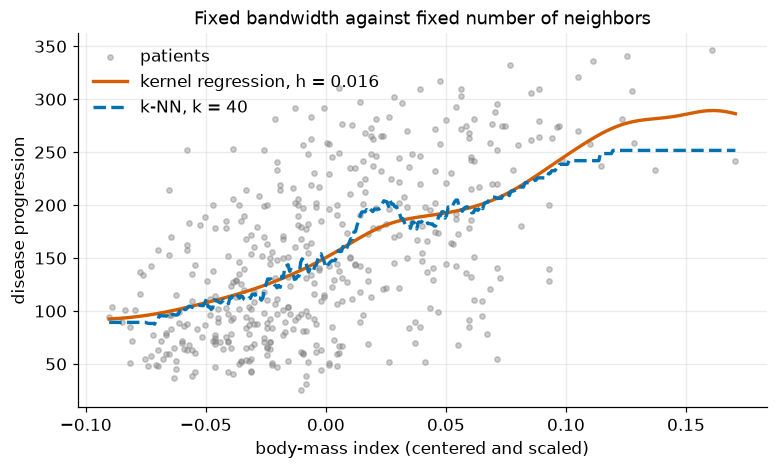

In [21]:
def solution_4_8():
    from sklearn.datasets import load_diabetes
    from sklearn.model_selection import train_test_split
    from sklearn.neighbors import KNeighborsRegressor

    X, y = load_diabetes(return_X_y=True)
    x = X[:, 2]                                                           # bmi

    def nadaraya_watson(x_train, y_train, x_test, h):
        d2 = (x_test[:, None] - x_train[None, :]) ** 2
        w = np.exp(-(d2 - d2.min(axis=1, keepdims=True)) / (2 * h * h))    # subtracting the smallest d2 avoids 0/0 far from the data
        return (w * y_train).sum(axis=1) / w.sum(axis=1)

    hs = np.array([0.004, 0.006, 0.008, 0.012, 0.016, 0.024, 0.032, 0.048, 0.064, 0.1])
    ks = [10, 20, 30, 40, 60, 80]
    mse_h, mse_k = np.zeros((20, len(hs))), np.zeros((20, len(ks)))
    for r in range(20):
        xa, xb, ya, yb = train_test_split(x, y, test_size=0.3, random_state=r)
        for j, h in enumerate(hs):
            mse_h[r, j] = np.mean((nadaraya_watson(xa, ya, xb, h) - yb) ** 2)
        for j, k in enumerate(ks):
            mse_k[r, j] = np.mean((KNeighborsRegressor(n_neighbors=k).fit(xa[:, None], ya).predict(xb[:, None]) - yb) ** 2)
    print("kernel regression, test MSE by bandwidth h:", {float(h): int(round(v)) for h, v in zip(hs, mse_h.mean(axis=0))})
    print("k-NN regression, test MSE by k           :", {k: int(round(v)) for k, v in zip(ks, mse_k.mean(axis=0))})
    h_best, k_best = hs[mse_h.mean(axis=0).argmin()], ks[mse_k.mean(axis=0).argmin()]
    print(f"best: h = {h_best} (MSE {mse_h.mean(axis=0).min():.0f}) | k = {k_best} (MSE {mse_k.mean(axis=0).min():.0f})")

    grid = np.linspace(x.min(), x.max(), 400)
    fit_h = nadaraya_watson(x, y, grid, h_best)
    fit_k = KNeighborsRegressor(n_neighbors=k_best).fit(x[:, None], y).predict(grid[:, None])
    for x_probe in (-0.05, 0.0, 0.1, 0.15):
        in_window = int(np.sum(np.abs(x - x_probe) <= h_best))
        print(f"x = {x_probe:+.2f}: points within +/- h: {in_window:>3} | radius of the {k_best}-NN neighborhood: {np.sort(np.abs(x - x_probe))[k_best - 1]:.3f}"
              f" | fits: kernel {nadaraya_watson(x, y, np.array([x_probe]), h_best)[0]:.0f}, k-NN {fit_k[np.argmin(np.abs(grid - x_probe))]:.0f}")

    fig, ax = plt.subplots(figsize=(7.2, 4.4))
    ax.scatter(x, y, s=12, color="gray", alpha=0.4, label="patients")
    ax.plot(grid, fit_h, color=VERMILION, linewidth=2.2, label=f"kernel regression, h = {h_best}")
    ax.plot(grid, fit_k, color=BLUE, linewidth=2.2, linestyle="--", label=f"k-NN, k = {k_best}")
    ax.set(xlabel="body-mass index (centered and scaled)", ylabel="disease progression", title="Fixed bandwidth against fixed number of neighbors")
    ax.legend(frameon=False, loc="upper left")
    fig.tight_layout()
    plt.show()


solution_4_8()

With a bandwidth of $h = 0.016$ the kernel regression has a test MSE of 3,863, against 3,966 for the best k-NN ($k = 40$): about 3% lower, a difference that these 20 splits cannot establish as significant. The figure and the last lines of the output show where the two methods differ. In the **dense** region ($x = -0.05$ and $x = 0$: 88 and 112 points in the window $\pm h$) the two fits coincide (108 against 107, and 150 against 147), because both average a few dozen nearby points. In the **sparse** region ($x = 0.15$) only 2 patients fall within $\pm h$: the kernel estimate (286) is determined by two points and is therefore noisy (the wiggle at the right end of the figure), while k-NN is forced to average 40 patients, reaching out to a distance of $0.082$, which gives a flat, smoother and more biased estimate (248; all its neighbors lie on one side). This is the essential difference: **a fixed bandwidth has the same bias everywhere and a variance that depends on the local density, while a fixed $k$ has the same variance everywhere and a bias that grows where the data are sparse.** (Kernel regression also gives a smooth curve, whereas k-NN gives a staircase.) Both are special cases of local averaging with weights that decrease with the distance, and Chapter 9 will show kernels in a different role.

In [22]:
def solution_4_9():
    from sklearn.datasets import load_breast_cancer
    from sklearn.feature_selection import SelectKBest, f_classif
    from sklearn.linear_model import LogisticRegression
    from sklearn.model_selection import train_test_split
    from sklearn.neighbors import KNeighborsClassifier
    from sklearn.pipeline import make_pipeline
    from sklearn.preprocessing import StandardScaler

    X, y = load_breast_cancer(return_X_y=True)
    rows = []
    for m in (100, 1000):
        res = {"5-NN": [], "selection + 5-NN (pipeline)": [], "logistic regression": [], "selection BEFORE the split + 5-NN (leak)": []}
        kept = []
        for r in range(15):
            Z = np.hstack([X, np.random.default_rng(r).normal(size=(len(X), m))])
            Za, Zb, ya, yb = train_test_split(Z, y, test_size=0.3, random_state=r, stratify=y)
            res["5-NN"].append(make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)).fit(Za, ya).score(Zb, yb))
            pipe = make_pipeline(StandardScaler(), SelectKBest(f_classif, k=30), KNeighborsClassifier(n_neighbors=5)).fit(Za, ya)
            res["selection + 5-NN (pipeline)"].append(pipe.score(Zb, yb))
            kept.append(pipe[1].get_support()[:30].sum())
            res["logistic regression"].append(make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)).fit(Za, ya).score(Zb, yb))
            # the mistake: the selection sees all the labels, test samples included
            Zs = SelectKBest(f_classif, k=30).fit_transform(StandardScaler().fit_transform(Z), y)
            Zsa, Zsb, ysa, ysb = train_test_split(Zs, y, test_size=0.3, random_state=r, stratify=y)
            res["selection BEFORE the split + 5-NN (leak)"].append(KNeighborsClassifier(n_neighbors=5).fit(Zsa, ysa).score(Zsb, ysb))
        print(f"\n{m} noise columns:")
        for name, v in res.items():
            print(f"  {name:<42}{np.mean(v):.4f}  (std {np.std(v):.4f})")
        print(f"  original features among the 30 selected: {np.mean(kept):.1f} of 30")


solution_4_9()


100 noise columns:
  5-NN                                      0.9103  (std 0.0194)
  selection + 5-NN (pipeline)               0.9548  (std 0.0120)
  logistic regression                       0.9450  (std 0.0108)
  selection BEFORE the split + 5-NN (leak)  0.9556  (std 0.0141)
  original features among the 30 selected: 25.5 of 30



1000 noise columns:
  5-NN                                      0.8031  (std 0.0333)
  selection + 5-NN (pipeline)               0.9571  (std 0.0129)
  logistic regression                       0.9232  (std 0.0178)
  selection BEFORE the split + 5-NN (leak)  0.9536  (std 0.0146)
  original features among the 30 selected: 25.0 of 30


With 100 noise columns the plain 5-NN has an accuracy of 0.910; with the selection step inside the pipeline it recovers 0.955, better than logistic regression (0.945); with 1,000 noise columns the numbers are 0.803 and 0.957 against 0.923. On average 25 of the 30 selected features are original ones, out of 100 or 1,000 candidates that are mostly noise: the F-statistic of Chapter 10 finds the informative features easily because they carry a strong signal. The scores of 5-NN are almost the same with 100 and with 1,000 noise columns *after the selection*, which shows that it is the number of *irrelevant features that reach the distance* that damages k-NN, not the number of columns in the table.

(c) The version with the selection done **before** the split (the leak of Section 2.7) gives 0.956 and 0.954: practically the same as the correct pipeline, and well inside the standard deviation over the splits (0.012 to 0.015). Here the leak is harmless because the signal is real and strong: the same 25 or so original features would be selected from the training set alone. As in Exercise 2.10, the leak becomes dangerous when the selection can exploit *chance* correlations, that is when there are many candidate features and few samples or no real signal; the pipeline is the safe habit in every case, because one cannot know beforehand which case one is in.

d = 2   (Bayes risk 0.1587)
       k ≈ √n  k ≈ n^(2/3)
n                         
30     0.1855       0.2097
100    0.1682       0.1651
300    0.1626       0.1598
1000   0.1589       0.1572
3000   0.1588       0.1573
10000  0.1570       0.1570
   smallest n within 0.01 of the Bayes risk, k ≈ √n: 100
   smallest n within 0.01 of the Bayes risk, k ≈ n^(2/3): 100



d = 10   (Bayes risk 0.1587)
       k ≈ √n  k ≈ n^(2/3)
n                         
30     0.2628       0.2600
100    0.2129       0.2048
300    0.1799       0.1693
1000   0.1696       0.1630
3000   0.1636       0.1593
10000  0.1600       0.1573
   smallest n within 0.01 of the Bayes risk, k ≈ √n: 3000
   smallest n within 0.01 of the Bayes risk, k ≈ n^(2/3): 1000



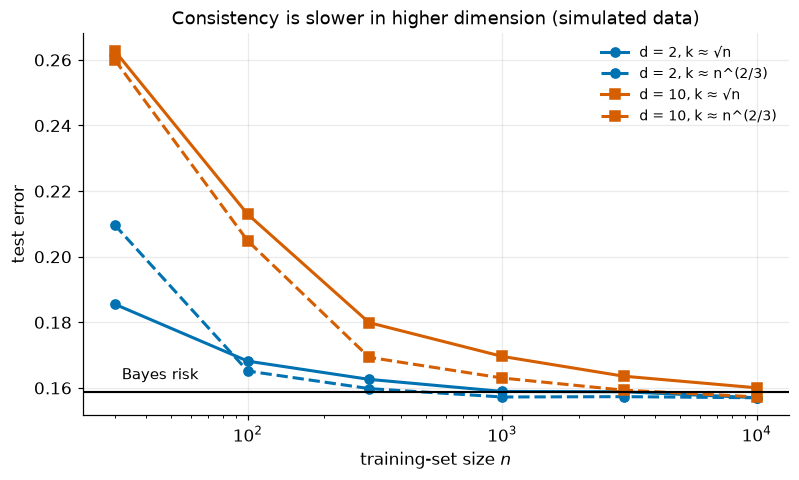

In [23]:
def solution_4_10():
    from scipy import stats
    from sklearn.neighbors import KNeighborsClassifier

    rng = np.random.default_rng(SEED)
    bayes = stats.norm.cdf(-1)
    sizes = [30, 100, 300, 1000, 3000, 10000]
    rules = {"k ≈ √n": lambda n: min(int(round(np.sqrt(n))) | 1, n), "k ≈ n^(2/3)": lambda n: min(int(round(n ** (2 / 3))) | 1, n)}

    def draw(n, d):
        y = rng.integers(0, 2, n)
        X = rng.normal(size=(n, d))
        X[:, 0] += 2 * y
        return X, y

    results = {}
    for d in (2, 10):
        X_fresh, y_fresh = draw(20_000, d)
        rows = []
        for n in sizes:
            errs = {name: [] for name in rules}
            for _ in range(6):
                X_s, y_s = draw(n, d)
                for name, k_of_n in rules.items():
                    model = KNeighborsClassifier(n_neighbors=k_of_n(n), algorithm="brute").fit(X_s, y_s)
                    errs[name].append(np.mean(model.predict(X_fresh) != y_fresh))
            rows.append({"n": n, **{name: np.mean(v) for name, v in errs.items()}})
        results[d] = pd.DataFrame(rows).set_index("n")
        print(f"d = {d}   (Bayes risk {bayes:.4f})")
        print(results[d].round(4).to_string())
        for name in rules:
            ok = results[d].index[(results[d][name] - bayes) <= 0.01]
            print(f"   smallest n within 0.01 of the Bayes risk, {name}: {ok.min() if len(ok) else 'none in the grid'}")
        print()

    fig, ax = plt.subplots(figsize=(7.4, 4.5))
    for d, (color, marker) in {2: (BLUE, "o"), 10: (VERMILION, "s")}.items():
        for name, ls in zip(rules, ["-", "--"]):
            ax.plot(sizes, results[d][name], color=color, marker=marker, linestyle=ls, linewidth=2, label=f"d = {d}, {name}")
    ax.axhline(bayes, color="black", linewidth=1.4)
    ax.text(32, bayes + 0.004, "Bayes risk", fontsize=9.5)
    ax.set_xscale("log")
    ax.set(xlabel="training-set size $n$", ylabel="test error", title="Consistency is slower in higher dimension (simulated data)")
    ax.legend(frameon=False, fontsize=9)
    fig.tight_layout()
    plt.show()


solution_4_10()

In dimension 2 the error is within 0.01 of the Bayes risk (0.1587) from $n = 100$ on for both rules, and reaches 0.157 at $n = 10{,}000$, as in Figure 4.8. In dimension 10, **with exactly the same Bayes risk and with only the first coordinate informative**, the convergence is much slower: at $n = 100$ the errors are 0.213 and 0.205 (against 0.168 and 0.165 in dimension 2), and the smallest $n$ of the grid within 0.01 of the Bayes risk is 3,000 for $k \approx \sqrt{n}$ and 1,000 for $k \approx n^{2/3}$, 30 and 10 times larger than in dimension 2. Nine useless coordinates make the distances noisy: two points of the same class are as far apart as two of different classes unless $n$ is large enough for the nearest neighbors to be close in all ten coordinates at once, which is the third face of the curse (Section 4.7.1). Note also that the larger $k$ is better in dimension 10 at every $n$ of the grid: when the individual neighbors are less informative, averaging more of them pays. (Exercise 4.9 shows how to reduce the penalty, by removing the useless coordinates.)

## C.5 Chapter 5

### Manual exercises

**Solution 5.1 — How much can a validation set tell?**

(a) $\hat p = 0.87$, so $\operatorname{SE} = \sqrt{0.87 \cdot 0.13/100} = 0.0336$ and the 95% interval is $0.87 \pm 1.96 \cdot 0.0336 = 0.87 \pm 0.066$, that is **[0.804, 0.936]**: a validation set of 100 examples cannot distinguish an 81% model from a 93% one.

(b) We need $1.96\sqrt{p(1-p)/m} \le 0.02$, that is $m \ge 1.96^2\,p(1-p)/0.02^2$. For $p = 0.9$: $m \ge 3.8416 \cdot 0.09/0.0004 = 864.4$, so **865 examples**. In the worst case $p = \tfrac12$, $p(1-p) = 0.25$ and $m \ge 2{,}401$.

(c) Hoeffding's inequality (Section 3.10.2) asks for $m \ge \ln(2/0.05)/(2 \cdot 0.02^2) = 4611.1$, that is **4,612 examples**: about twice the worst-case number of the normal approximation, and 5.3 times the number for $p = 0.9$. Hoeffding uses only the fact that the loss is in $[0, 1]$, so it holds for every $m$ and every $p$ without any approximation, but it ignores the variance $p(1-p)$, which is what makes the normal interval narrower when the accuracy is high. (The Wilson interval of Section 3.10.2 gets the best of both: it is valid for small samples and uses the variance.)

(d) The first model is right on $85 + 5 = 90$ examples and the second on $85 + 2 = 87$. Only the $b + c = 7$ discordant examples carry information: if the models had the same error rate, $b \sim \text{Binomial}(7, \tfrac12)$, and
$$
p = 2\,\mathbb{P}\big(\text{Bin}(7, \tfrac12) \le 2\big) = 2\cdot\frac{1 + 7 + 21}{128} = \frac{58}{128} = \mathbf{0.453}.
$$
The unpaired comparison of two accuracies would give $z = 0.03/\sqrt{0.09/100 + 0.1131/100} = 0.67$, that is $p \approx 0.51$. Pairing helps, but here only slightly: with seven discordant examples the data simply contain little evidence about the difference.

**Solution 5.2 — Counting model fits.**

(a) Each of the $5 \times 4 = 20$ configurations is evaluated with $5 \times 3 = 15$ fits, so $20 \cdot 15 = 300$, plus one refit of the winner: **301 fits**.

(b) Each outer fold runs the whole search on its training part (301 fits, including the refit of its winner, which is the model scored on the outer held-out fold): $5 \times 301 = \mathbf{1{,}505}$ fits.

(c) Random search with 20 draws evaluates 20 configurations, exactly as many as the grid: $20 \cdot 15 + 1 = \mathbf{301}$ fits. (Random search saves nothing here; its advantage is that a *smaller* number of draws, say 8 or 10, often does as well as the full grid; see Exercise 5.8.)

(d) Leave-one-out needs $n = 1000$ fits per configuration: $12 \cdot 1000 + 1 = \mathbf{12{,}001}$ fits.

For a model that takes one minute to fit these are 301 minutes (five hours), 1,505 minutes (25 hours) and 12,001 minutes (more than eight days). The design must change: fewer folds or no repeats, a smaller or random search, successive halving, a faster surrogate model for the search, parallel execution, or a single validation split instead of cross-validation.

**Solution 5.3 — ROC and AUC by hand.** Sorted by decreasing score, the examples are $0.9^{+}, 0.7^{-}, 0.6^{+}, 0.4^{+}, 0.4^{-}, 0.2^{-}, 0.1^{-}$, with $n_+ = 3$ and $n_- = 4$.

(a) Lowering the threshold past each block of scores, the curve moves up by $1/3$ for each positive and right by $1/4$ for each negative; the two tied examples at 0.4 are passed together, a diagonal step. The points $(\text{FPR}, \text{TPR})$ are
$$
(0, 0),\ (0, \tfrac13),\ (\tfrac14, \tfrac13),\ (\tfrac14, \tfrac23),\ (\tfrac12, 1),\ (\tfrac34, 1),\ (1, 1).
$$

(b) Trapezoid rule: the vertical steps have zero width; the horizontal step from $(0, \tfrac13)$ to $(\tfrac14, \tfrac13)$ contributes $\tfrac14\cdot\tfrac13 = \tfrac1{12}$; the diagonal step from $(\tfrac14, \tfrac23)$ to $(\tfrac12, 1)$ contributes $\tfrac14\cdot\tfrac{(2/3 + 1)}{2} = \tfrac{5}{24}$; the last two steps contribute $\tfrac14 + \tfrac14 = \tfrac12$. The total is $\tfrac{2}{24} + \tfrac{5}{24} + \tfrac{12}{24} = \tfrac{19}{24} = \mathbf{0.7917}$. Counting pairs: the positive 0.9 beats all 4 negatives; the positive 0.6 beats 3 (0.4, 0.2, 0.1) and loses to 0.7; the positive 0.4 beats 2 (0.2, 0.1), loses to 0.7 and ties with the other 0.4, which counts $\tfrac12$. The total is $4 + 3 + 2.5 = 9.5$ pairs of 12, and $9.5/12 = \tfrac{19}{24}$: **the two computations agree**, as Proposition 5.1 says.

(c) Predicting positive when the score is at least $t$:

| $t$ | TP | FP | precision | recall | $F_1$ |
|---|---|---|---|---|---|
| 0.9 | 1 | 0 | 1 | 1/3 | 0.500 |
| 0.7 | 1 | 1 | 1/2 | 1/3 | 0.400 |
| 0.6 | 2 | 1 | 2/3 | 2/3 | 0.667 |
| 0.4 | 3 | 2 | 3/5 | 1 | **0.750** |
| 0.2 | 3 | 3 | 1/2 | 1 | 0.667 |
| 0.1 | 3 | 4 | 3/7 | 1 | 0.600 |

The $F_1$ score is maximal at $t = 0.4$, with $F_1 = 0.75$ (precision 0.6, recall 1). Note that the tied scores force us to flag both examples at 0.4 or neither.

**Solution 5.4 — The cost-optimal threshold.**

(a) Predicting positive costs, in expectation, $(1 - \hat p)\,c_{FP}$ (we are wrong when $y = 0$); predicting negative costs $\hat p\,c_{FN}$. We predict positive when $(1-\hat p)\,c_{FP} \le \hat p\,c_{FN}$, that is $c_{FP} \le \hat p\,(c_{FP} + c_{FN})$, which is $\hat p \ge t^\ast = c_{FP}/(c_{FP} + c_{FN})$.

(b) $t^\ast = 5/(5 + 200) = \mathbf{0.0244}$: flag a transaction as soon as the estimated probability of fraud exceeds 2.4%.

(c) Of 10,000 transactions, 50 are fraudulent and 9,950 are legitimate. TPR 0.90 gives $TP = 45$, $FN = 5$; FPR 0.02 gives $FP = 199$, $TN = 9{,}751$. Precision $= 45/(45 + 199) = \mathbf{0.184}$. The cost is $200 \cdot 5 + 5 \cdot 199 = 1{,}995$, that is **0.1995 per transaction**. "Flag nothing" costs $200 \cdot 50 = 10{,}000$ (1.0 per transaction) and "flag everything" costs $5 \cdot 9{,}950 = 49{,}750$ (4.975 per transaction). The detector cuts the cost by a factor of five although only 18% of its alarms are real: a low precision is perfectly acceptable when a miss costs forty times a false alarm.

(d) It does not change: $t^\ast$ depends only on the **ratio** $c_{FN}/c_{FP}$, which here stays at 40. Doubling both costs doubles the total cost but leaves the optimal decision unchanged.

**Solution 5.5 — Leave-one-out for least squares without refitting.** Write $\mathbf{A} = \mathbf{X}^\top\mathbf{X}$, so that $\hat{\boldsymbol\beta} = \mathbf{A}^{-1}\mathbf{X}^\top\mathbf{y}$ and $h_{ii} = \mathbf{x}_i^\top\mathbf{A}^{-1}\mathbf{x}_i$.

(a) Without example $i$, $\mathbf{X}_{(i)}^\top\mathbf{X}_{(i)} = \mathbf{A} - \mathbf{x}_i\mathbf{x}_i^\top$ and $\mathbf{X}_{(i)}^\top\mathbf{y}_{(i)} = \mathbf{X}^\top\mathbf{y} - \mathbf{x}_i y_i$. By the Sherman–Morrison formula, $(\mathbf{A} - \mathbf{x}_i\mathbf{x}_i^\top)^{-1} = \mathbf{A}^{-1} + \dfrac{\mathbf{A}^{-1}\mathbf{x}_i\mathbf{x}_i^\top\mathbf{A}^{-1}}{1 - h_{ii}}$. Therefore
$$
\hat{\boldsymbol\beta}_{(i)} = \Big(\mathbf{A}^{-1} + \frac{\mathbf{A}^{-1}\mathbf{x}_i\mathbf{x}_i^\top\mathbf{A}^{-1}}{1 - h_{ii}}\Big)\big(\mathbf{X}^\top\mathbf{y} - \mathbf{x}_i y_i\big)
= \hat{\boldsymbol\beta} - \mathbf{A}^{-1}\mathbf{x}_i y_i + \frac{\mathbf{A}^{-1}\mathbf{x}_i\,\hat y_i}{1 - h_{ii}} - \frac{\mathbf{A}^{-1}\mathbf{x}_i\,h_{ii}\,y_i}{1 - h_{ii}},
$$
using $\mathbf{x}_i^\top\mathbf{A}^{-1}\mathbf{X}^\top\mathbf{y} = \mathbf{x}_i^\top\hat{\boldsymbol\beta} = \hat y_i$ and $\mathbf{x}_i^\top\mathbf{A}^{-1}\mathbf{x}_i = h_{ii}$. Collecting the terms in $y_i$: $-y_i\big(1 + \tfrac{h_{ii}}{1 - h_{ii}}\big) = -\tfrac{y_i}{1 - h_{ii}}$, so
$$
\hat{\boldsymbol\beta}_{(i)} = \hat{\boldsymbol\beta} - \mathbf{A}^{-1}\mathbf{x}_i\,\frac{y_i - \hat y_i}{1 - h_{ii}} = \hat{\boldsymbol\beta} - \mathbf{A}^{-1}\mathbf{x}_i\,\frac{e_i}{1 - h_{ii}}.
$$
The prediction for example $i$ from the model that did not see it is $\mathbf{x}_i^\top\hat{\boldsymbol\beta}_{(i)} = \hat y_i - h_{ii}\,\dfrac{e_i}{1 - h_{ii}}$, and the leave-one-out residual is
$$
y_i - \mathbf{x}_i^\top\hat{\boldsymbol\beta}_{(i)} = e_i + \frac{h_{ii}\,e_i}{1 - h_{ii}} = \frac{e_i}{1 - h_{ii}}. \qquad\square
$$

(b) The leave-one-out mean squared error is $\dfrac{1}{n}\sum_{i=1}^n \Big(\dfrac{e_i}{1 - h_{ii}}\Big)^2$ (the PRESS statistic divided by $n$): it needs the residuals and the diagonal of the hat matrix of **one** fit on all the data, instead of $n$ fits. (The same trick works for every *linear smoother*, that is for every method whose fitted values are $\hat{\mathbf{y}} = \mathbf{H}\mathbf{y}$ for a matrix $\mathbf{H}$ that does not depend on $\mathbf{y}$, including ridge regression.)

(c) The leverages satisfy $0 \le h_{ii} \le 1$ and $\sum_i h_{ii} = d$. An example with $h_{ii}$ close to 1 is far from the others in the input space: the fit passes almost through it, so its ordinary residual $e_i$ is small, but without it the model has nothing to extrapolate from, and the leave-one-out residual $e_i/(1 - h_{ii})$ can be large. High-leverage examples are exactly where the training residuals are most misleading about the prediction error.

### Python exercises

In [24]:
def solution_5_6():
    from sklearn.datasets import load_breast_cancer
    from sklearn.model_selection import cross_val_score
    from sklearn.neighbors import KNeighborsClassifier
    from sklearn.pipeline import make_pipeline
    from sklearn.preprocessing import StandardScaler

    def stratified_kfold_splits(y, K, seed):
        """Shuffle the indices of each class and deal them out to the K folds in turn."""
        rng = np.random.default_rng(seed)
        folds = [[] for _ in range(K)]
        for cls in np.unique(y):
            idx = rng.permutation(np.flatnonzero(y == cls))
            for j, chunk in enumerate(np.array_split(idx, K)):
                folds[j].extend(chunk.tolist())
        folds = [np.array(sorted(f)) for f in folds]
        return [(np.setdiff1d(np.arange(len(y)), held), held) for held in folds]

    def shuffled_kfold_splits(n, K, seed):
        folds = np.array_split(np.random.default_rng(seed).permutation(n), K)
        return [(np.setdiff1d(np.arange(n), held), held) for held in folds]

    X, y = load_breast_cancer(return_X_y=True)
    y = 1 - y                                               # 1 = malignant
    rng = np.random.default_rng(SEED)
    keep = np.r_[np.flatnonzero(y == 0), rng.choice(np.flatnonzero(y == 1), size=20, replace=False)]
    Xs, ys = X[keep], y[keep]
    print(f"imbalanced data set: {len(ys)} patients, {int(ys.sum())} malignant ({ys.mean():.3f})")

    # (b) the class counts in each fold differ by at most one from the ideal proportion
    worst = 0
    for seed in range(50):
        for _, held in stratified_kfold_splits(ys, 5, seed):
            for cls in (0, 1):
                ideal = np.mean(ys == cls) * len(held)
                worst = max(worst, abs(np.sum(ys[held] == cls) - ideal))
    print(f"largest deviation from the ideal class count in a fold, over 50 seeds: {worst:.2f} examples")

    # (c) plain shuffled folds against stratified folds
    model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
    out = {}
    for name, make in {"shuffled": lambda s: shuffled_kfold_splits(len(ys), 5, s),
                       "stratified": lambda s: stratified_kfold_splits(ys, 5, s)}.items():
        acc, min_pos = [], []
        for seed in range(50):
            splits = make(seed)
            acc.append(cross_val_score(model, Xs, ys, cv=splits).mean())
            min_pos.append(min(int(ys[held].sum()) for _, held in splits))
        out[name] = {"mean accuracy": np.mean(acc), "sd across seeds": np.std(acc, ddof=1),
                     "fewest malignant in a fold": int(np.min(min_pos)), "mean of that minimum": np.mean(min_pos)}
    table = pd.DataFrame(out).T.astype({"fewest malignant in a fold": int})
    print(table.round(4).to_string())


solution_5_6()

imbalanced data set: 377 patients, 20 malignant (0.053)
largest deviation from the ideal class count in a fold, over 50 seeds: 0.03 examples


            mean accuracy  sd across seeds  fewest malignant in a fold  mean of that minimum
shuffled           0.9783           0.0022                           0                  1.86
stratified         0.9788           0.0026                           4                  4.00


**(b)** In all 50 stratified 5-fold splits (250 folds) the number of examples of each class in a fold is within 0.03 of the ideal proportion. With 20 malignant examples and 5 folds every fold receives exactly 4 of them, and the 357 benign ones are dealt out as 72, 72, 71, 71, 71, so the deviation from the ideal count is only due to the fact that the folds themselves have 75 or 76 examples.

**(c)** Stratification does **not** change the accuracy estimate: the mean accuracy is 0.978 for shuffled folds and 0.979 for stratified folds, and the standard deviation across seeds is 0.0022 against 0.0026, a difference that 50 seeds cannot resolve. What it changes is the **composition of the folds**. With shuffled folds there is, over the 50 seeds, at least one split in which a fold contains no malignant tumor at all (the smallest number found is 0), and the smallest fold contains on average 1.86 malignant examples; with stratified folds the smallest fold always contains 4. On a data set with 5% positives the accuracy hides the problem, because it is dominated by the benign class, but any metric that is computed *per fold* and involves the positive class (recall, precision, AUC) is undefined for a fold without positives and extremely noisy for a fold with one or two. Stratification costs nothing and removes the problem, which is why it is the default for classification in scikit-learn.

In [25]:
def solution_5_7():
    from sklearn.datasets import load_breast_cancer
    from sklearn.linear_model import LogisticRegression
    from sklearn.model_selection import KFold, cross_val_score
    from sklearn.pipeline import make_pipeline
    from sklearn.preprocessing import StandardScaler

    X, y = load_breast_cancer(return_X_y=True)
    model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
    Ks = [2, 5, 10, 20]
    rng = np.random.default_rng(SEED)
    rows = []
    for rep in range(100):
        perm = rng.permutation(len(y))
        s, t = perm[:100], perm[100:]
        fitted = model.fit(X[s], y[s])
        row = {"test": fitted.score(X[t], y[t])}
        for K in Ks:
            row[f"cv{K}"] = cross_val_score(model, X[s], y[s], cv=KFold(K, shuffle=True, random_state=rep)).mean()
        rows.append(row)
    runs = pd.DataFrame(rows)
    table = pd.DataFrame({"K": Ks, "training size": [100 - 100 // K for K in Ks],
                          "bias (CV - test)": [(runs[f"cv{K}"] - runs["test"]).mean() for K in Ks],
                          "sd of (CV - test)": [(runs[f"cv{K}"] - runs["test"]).std() for K in Ks]})
    print(f"mean accuracy of the model fitted on 100 patients: {runs['test'].mean():.4f}")
    print(table.round(4).to_string(index=False))

    lc = {}
    for m in (25, 50, 75, 100, 200):
        accs = []
        for _ in range(100):
            perm = rng.permutation(len(y))
            accs.append(model.fit(X[perm[:m]], y[perm[:m]]).score(X[perm[m:]], y[perm[m:]]))
        lc[m] = np.mean(accs)
    print("learning curve of the logistic regression (mean accuracy by training size):", ", ".join(f"{m}: {v:.4f}" for m, v in lc.items()))


solution_5_7()

mean accuracy of the model fitted on 100 patients: 0.9651
 K  training size  bias (CV - test)  sd of (CV - test)
 2             50           -0.0104             0.0277
 5             80           -0.0037             0.0255
10             90           -0.0021             0.0246
20             95           -0.0019             0.0243


learning curve of the logistic regression (mean accuracy by training size): 25: 0.9363, 50: 0.9535, 75: 0.9615, 100: 0.9647, 200: 0.9708


The model fitted on 100 patients has a mean accuracy of 0.9651 on the other 469. The CV estimates are again slightly pessimistic, but the bias is **much smaller** than for the 3-NN on Digits of Section 5.3.2: 1.04 points for $K = 2$, 0.37 for $K = 5$, 0.21 for $K = 10$ and 0.19 for $K = 20$, against 11, 3, 1.4 and 0.8 points. The standard deviation of $\mathrm{CV}_K - $ test accuracy is 0.028, 0.026, 0.025 and 0.024: it hardly depends on $K$, and it is smaller than the 0.042 of Digits (accuracies close to 1 leave less room for variation).

The reason is the **learning curve** (last line of the output). The accuracy of the logistic regression grows from 0.9535 with 50 training patients to 0.9647 with 100: halving the training set costs 1.1 points, which is the bias that we measure for $K = 2$ (1.04). For the larger values of $K$ the training size is 80, 90 and 95 and the curve between 75 and 100 patients is almost flat (0.9615 and 0.9647), which accounts for biases of a few tenths of a point. A linear model with 30 features is already close to its best on 100 patients of this easy problem, while a 10-class nearest-neighbor classifier with 100 images is still far from it. The lesson is that the choice of $K$ should be made by looking at the learning curve of **the model at hand**: for a model that saturates early, $K = 5$ is as good as $K = 20$; for a data-hungry model, larger $K$ is worth its cost.

60 configurations; CV accuracy ranges from 0.948 to 0.972, test accuracy from 0.944 to 0.958
 budget B  CV accuracy of the selected  test accuracy of the selected  optimism
        2                       0.9639                         0.9526    0.0113
        4                       0.9674                         0.9538    0.0136
        8                       0.9696                         0.9554    0.0141
       15                       0.9708                         0.9566    0.0143
       30                       0.9717                         0.9576    0.0141
       60                       0.9719                         0.9580    0.0139


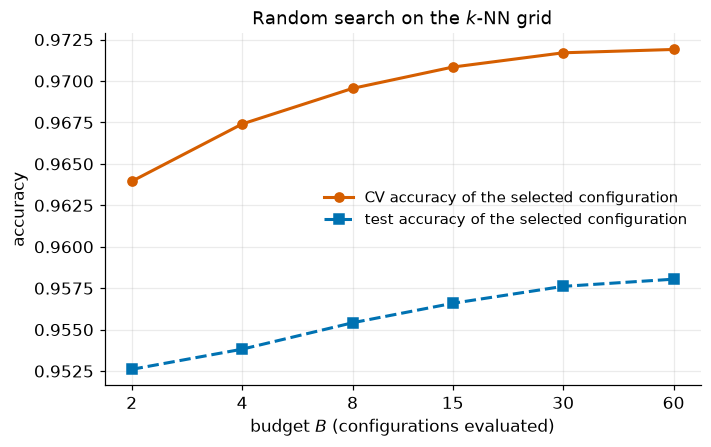

In [26]:
def solution_5_8():
    from sklearn.base import clone
    from sklearn.datasets import load_breast_cancer
    from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
    from sklearn.neighbors import KNeighborsClassifier
    from sklearn.pipeline import Pipeline
    from sklearn.preprocessing import StandardScaler

    X, y = load_breast_cancer(return_X_y=True)
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=0, stratify=y)     # a fresh split
    pipe = Pipeline([("scale", StandardScaler()), ("knn", KNeighborsClassifier())])
    grid = {"knn__n_neighbors": list(range(1, 31, 2)), "knn__weights": ["uniform", "distance"], "knn__p": [1, 2]}
    gs = GridSearchCV(pipe, grid, cv=StratifiedKFold(5, shuffle=True, random_state=SEED)).fit(X_tr, y_tr)
    cv_scores = np.array(gs.cv_results_["mean_test_score"])
    test_scores = np.array([clone(pipe).set_params(**p).fit(X_tr, y_tr).score(X_te, y_te) for p in gs.cv_results_["params"]])
    print(f"{len(cv_scores)} configurations; CV accuracy ranges from {cv_scores.min():.3f} to {cv_scores.max():.3f}, "
          f"test accuracy from {test_scores.min():.3f} to {test_scores.max():.3f}")

    rng = np.random.default_rng(SEED)
    budgets = [2, 4, 8, 15, 30, 60]
    rows = []
    for B in budgets:
        picked_cv, picked_test = [], []
        for _ in range(500):
            idx = rng.choice(len(cv_scores), size=B, replace=False)
            best = idx[np.argmax(cv_scores[idx])]
            picked_cv.append(cv_scores[best]); picked_test.append(test_scores[best])
        rows.append({"budget B": B, "CV accuracy of the selected": np.mean(picked_cv), "test accuracy of the selected": np.mean(picked_test)})
    table = pd.DataFrame(rows)
    table["optimism"] = table["CV accuracy of the selected"] - table["test accuracy of the selected"]
    print(table.round(4).to_string(index=False))

    fig, ax = plt.subplots(figsize=(6.6, 4.2))
    ax.plot(table["budget B"], table["CV accuracy of the selected"], color=VERMILION, marker="o", linewidth=2, label="CV accuracy of the selected configuration")
    ax.plot(table["budget B"], table["test accuracy of the selected"], color=BLUE, marker="s", linestyle="--", linewidth=2, label="test accuracy of the selected configuration")
    ax.set_xscale("log")
    ax.set_xticks(budgets, labels=[str(b) for b in budgets])
    ax.minorticks_off()
    ax.set(xlabel="budget $B$ (configurations evaluated)", ylabel="accuracy", title="Random search on the $k$-NN grid")
    ax.legend(frameon=False, fontsize=9.5)
    fig.tight_layout()
    plt.show()


solution_5_8()

The 60 configurations are all reasonable: their CV accuracies range from 0.948 to 0.972 and their test accuracies from 0.944 to 0.958, and the test set has 143 patients, so one patient is 0.7 points. The table and the figure show what a random search with budget $B$ obtains. Most of the gain comes from the first evaluations: the test accuracy of the selected configuration rises from 0.9526 at $B = 2$ to 0.9554 at $B = 8$ and to 0.9566 at $B = 15$, and then only to 0.9580 at $B = 60$. From $B = 15$ to $B = 60$ the gain is 0.0014, about **one fifth of one patient**, while the cost is four times larger: the search stops paying at a budget of about 8 to 15 configurations, that is, 13% to 25% of the grid. This is the argument of Bergstra and Bengio (2012) in miniature: when many configurations are almost equivalent, a few random draws are almost as good as the full grid.

The difference between the two curves is the optimism of the selection. It is 1.1 points at $B = 2$, 1.4 points from $B = 8$ on, and **0.0139 at $B = 60$**: the CV accuracy of the winner of the whole grid, 0.9719, is 1.4 points higher than the accuracy that the same configuration achieves on new patients. Unlike the coin-flip experiment of Exercise 5.9, the optimism does not keep growing with the number of candidates, because the configurations are not independent: neighboring values of $k$, or the same $k$ with the two distances, give nearly the same predictions and nearly the same scores, so evaluating 60 of them is like evaluating a handful of really different ones. This is why, with real hyperparameter grids, the optimism is moderate; and it is why the final number to report is the one measured on the test set and not the best CV score.

In [27]:
def solution_5_9():
    from sklearn.datasets import load_breast_cancer
    from sklearn.model_selection import KFold, cross_val_score
    from sklearn.neighbors import KNeighborsClassifier
    from sklearn.pipeline import make_pipeline
    from sklearn.preprocessing import StandardScaler

    X, _ = load_breast_cancer(return_X_y=True)
    rng = np.random.default_rng(SEED)

    def best_cv_optimism(n, ms, m_max, n_rep=40):
        """Mean over repetitions of (best CV accuracy among the first m candidates) - 0.5, for each m in ms."""
        out = {m: [] for m in ms}
        for rep in range(n_rep):
            idx = rng.choice(len(X), size=n, replace=False)
            y_coin = rng.integers(0, 2, size=n)                                # labels unrelated to the features
            scores = []
            for _ in range(m_max):
                cols = rng.choice(X.shape[1], size=5, replace=False)
                model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
                scores.append(cross_val_score(model, X[idx][:, cols], y_coin, cv=KFold(5, shuffle=True, random_state=rep)).mean())
            for m in ms:
                out[m].append(max(scores[:m]) - 0.5)
        return {m: np.mean(v) for m, v in out.items()}

    ms = [1, 4, 16, 64]
    res_m = best_cv_optimism(60, ms, 64)
    print("(a) n = 60")
    print(pd.DataFrame({"m": ms, "mean optimism": [res_m[m] for m in ms], "bound sqrt(ln m/(2n))": [np.sqrt(np.log(m) / 120) for m in ms]}).round(4).to_string(index=False))
    ns = [30, 60, 120, 240]
    res_n = {n: best_cv_optimism(n, [16], 16)[16] for n in ns}
    print("(b) m = 16")
    print(pd.DataFrame({"n": ns, "mean optimism": [res_n[n] for n in ns], "bound sqrt(ln m/(2n))": [np.sqrt(np.log(16) / (2 * n)) for n in ns]}).round(4).to_string(index=False))


solution_5_9()

(a) n = 60
 m  mean optimism  bound sqrt(ln m/(2n))
 1         0.0192                 0.0000
 4         0.0621                 0.1075
16         0.1108                 0.1520
64         0.1388                 0.1862


(b) m = 16
  n  mean optimism  bound sqrt(ln m/(2n))
 30         0.1242                 0.2150
 60         0.1079                 0.1520
120         0.0912                 0.1075
240         0.0652                 0.0760


**(a)** For $n = 60$ the mean optimism (best CV accuracy minus the true accuracy 0.5) is 0.019 for $m = 1$, 0.062 for $m = 4$, 0.111 for $m = 16$ and 0.139 for $m = 64$. The value for $m = 1$ should be zero, because a single candidate is not selected: 0.019 is the Monte Carlo error of 40 repetitions (the standard deviation of one CV accuracy on 60 coin flips is about $0.5/\sqrt{60} = 0.065$, so the mean of 40 has an error of about 0.01). **(b)** For $m = 16$ the optimism is 0.124, 0.108, 0.091 and 0.065 for $n = 30, 60, 120, 240$; the value 0.108 at $n = 60$ differs from the 0.111 of part (a) for the same reason, since the two runs use different random draws.

**(c)** The bound $\sqrt{\ln m/(2n)}$ is 0, 0.108, 0.152 and 0.186 for the $m$ of part (a), and 0.215, 0.152, 0.108 and 0.076 for the $n$ of part (b): the measured optimism is **below the bound in every row**, as it must be. The qualitative shape is the predicted one: the optimism increases with the number of candidates, with diminishing increments (it grows by 0.049 from $m = 4$ to $m = 16$ but only by 0.028 from $m = 16$ to $m = 64$, as a function of $\ln m$ should), and it decreases when $n$ grows. The quantitative rate is not reproduced exactly: multiplying $n$ by 8 divides the bound by $\sqrt 8 = 2.8$, but the measured optimism only by 1.9, so the ratio of the measurement to the bound goes from 0.58 at $n = 30$ to 0.86 at $n = 240$. Two cautions are in order. The bound is derived for the error on a single validation set of $n$ examples, while here the estimate is a 5-fold CV accuracy on the same $n$ examples, so the comparison is a heuristic one; and it is a worst-case guarantee for any $m$ candidates, not an asymptotic equality, while our candidates share features and are therefore correlated. The practical message is the one of Section 5.2.3: with few examples, tuning a handful of candidates is enough to produce a CV accuracy that is more than **10 points** above the truth on labels that contain no signal at all.

In [28]:
def solution_5_10():
    from sklearn.datasets import load_breast_cancer
    from sklearn.linear_model import LogisticRegression
    from sklearn.model_selection import StratifiedKFold, cross_val_predict, train_test_split
    from sklearn.pipeline import make_pipeline
    from sklearn.preprocessing import StandardScaler

    X, y = load_breast_cancer(return_X_y=True)
    y = 1 - y                                                 # 1 = malignant
    ts = np.linspace(0.005, 0.995, 199)
    ratios = [1, 5, 10, 50]

    def mean_cost(y_true, p, t, c_fn):
        flagged = p >= t
        return (np.sum(flagged & (y_true == 0)) + c_fn * np.sum(~flagged & (y_true == 1))) / len(y_true)

    records = []
    for split in range(50):
        X1, X2, y1, y2 = train_test_split(X, y, test_size=0.3, random_state=split, stratify=y)
        model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
        oof = cross_val_predict(model, X1, y1, cv=StratifiedKFold(10, shuffle=True, random_state=split), method="predict_proba")[:, 1]
        p_test = model.fit(X1, y1).predict_proba(X2)[:, 1]
        for c_fn in ratios:
            t_data = ts[np.argmin([mean_cost(y1, oof, t, c_fn) for t in ts])]
            t_star = 1 / (1 + c_fn)
            records.append({"ratio": c_fn, "t_data": t_data, "t_star": t_star,
                            "cost 0.5": mean_cost(y2, p_test, 0.5, c_fn),
                            "cost theory": mean_cost(y2, p_test, t_star, c_fn),
                            "cost out-of-fold": mean_cost(y2, p_test, t_data, c_fn)})
    df = pd.DataFrame(records)
    summary = df.groupby("ratio").agg(**{"t* (theory)": ("t_star", "first"), "mean OOF threshold": ("t_data", "mean"), "sd OOF threshold": ("t_data", "std"),
                                          "cost, t = 0.5": ("cost 0.5", "mean"), "sd (0.5)": ("cost 0.5", "std"),
                                          "cost, t*": ("cost theory", "mean"), "sd (t*)": ("cost theory", "std"),
                                          "cost, OOF": ("cost out-of-fold", "mean"), "sd (OOF)": ("cost out-of-fold", "std")})
    print(summary.round(3).to_string())


solution_5_10()

       t* (theory)  mean OOF threshold  sd OOF threshold  cost, t = 0.5  sd (0.5)  cost, t*  sd (t*)  cost, OOF  sd (OOF)
ratio                                                                                                                    
1            0.500               0.454             0.074          0.025     0.011     0.025    0.011      0.028     0.012
5            0.167               0.331             0.110          0.101     0.048     0.092    0.035      0.090     0.037
10           0.091               0.162             0.126          0.196     0.096     0.136    0.055      0.156     0.070
50           0.020               0.053             0.029          0.954     0.478     0.256    0.144      0.331     0.225


The table gives, for each ratio $c_{FN}/c_{FP}$, the theoretical threshold $t^\ast = 1/(1 + c_{FN}/c_{FP})$, the mean and standard deviation of the threshold chosen from the out-of-fold scores, and the mean cost per patient (with its standard deviation over the 50 splits) of the three rules on the test part.

For $c_{FN}/c_{FP} = 1$ the three rules coincide in practice ($t^\ast = 0.5$ is the conventional threshold, and the data-driven rule is 0.003 worse, the price of estimating a threshold that is already known). For a ratio of 5 the theory and the out-of-fold rule are equivalent (0.092 and 0.090) and both are a little better than 0.5 (0.101), a difference smaller than the spread across splits. As the ratio grows the conventional threshold becomes costly and the **theory threshold is the best rule**: at ratio 10 the costs are 0.196 for $t = 0.5$, 0.156 for the out-of-fold optimum and 0.136 for $t^\ast$; at ratio 50 they are 0.954, 0.331 and 0.256, so that keeping $t = 0.5$ costs 3.7 times as much as using $t^\ast$.

The out-of-fold threshold is **highly variable**: its standard deviation is 0.074, 0.110 and 0.126 for the ratios 1, 5 and 10, as large as the threshold itself at ratio 10 (mean 0.162, against $t^\ast = 0.091$). The reason is visible in Figure 5.11(b): the cost curve of the logistic regression is nearly flat over a wide range of thresholds, with steps of one patient, so the minimum of a noisy curve can fall anywhere on the plateau, and the cost on new patients depends on where it fell (the standard deviation of the cost of this rule is 0.070 at ratio 10 and 0.225 at ratio 50, against 0.055 and 0.144 for $t^\ast$). The theory threshold has no such noise, but it is valid only if the scores are calibrated probabilities, which is the case for the logistic regression of this data set (Figure 5.11(a)); for a classifier with poorly calibrated scores, such as a $k$-NN with few neighbors or a decision tree, the threshold would have to be chosen from the data, after calibrating the scores, preferably with a smoother criterion than the minimum of a staircase.

## C.6 Chapter 6

### Manual exercises

**Solution 6.1 — Variances by hand.**

(a) With rows $(1, x_i)$ for $x = -3, -1, 1, 3$: $\mathbf{X}^\top\mathbf{X} = \begin{pmatrix}4 & 0\\ 0 & 20\end{pmatrix}$ (the sum of the $x_i$ is $0$ and the sum of their squares is $9 + 1 + 1 + 9 = 20$). Then $\sigma^2(\mathbf{X}^\top\mathbf{X})^{-1} = 4\,\mathrm{diag}(\tfrac14, \tfrac1{20}) = \mathrm{diag}(1,\ 0.2)$: $\operatorname{Var}(\hat b) = 1$, $\operatorname{Var}(\hat w) = 0.2$, and the two estimators are uncorrelated because the design is centered.

(b) With $\mathbf{x}_0 = (1, 2)^\top$: $h_0 = \mathbf{x}_0^\top(\mathbf{X}^\top\mathbf{X})^{-1}\mathbf{x}_0 = \tfrac14 + \tfrac{4}{20} = 0.45$. The variance of the fitted value is $\sigma^2 h_0 = \mathbf{1.8}$, and the expected squared error of a *new observation* is the noise plus that variance: $\sigma^2(1 + h_0) = 4 \cdot 1.45 = \mathbf{5.8}$ (Theorem 6.1).

(c) $h_{ii} = \tfrac14 + x_i^2/20$, that is $0.7,\ 0.3,\ 0.3,\ 0.7$, and the sum is $2 = p$: the trace of the hat matrix equals the number of parameters. The two extreme points have leverage $0.7$, so they pull the line more than the central ones.

(d) For $x = -3, -3, 3, 3$ we get $\sum_i(x_i - \bar x)^2 = 36$ instead of $20$ and $\operatorname{Var}(\hat w) = \sigma^2/36 = 0.111$ instead of $0.2$, a reduction of 44%. The variance of a slope is $\sigma^2/\sum_i(x_i - \bar x)^2$: *spreading the inputs to the ends of the range* is the best way to measure a slope (at the price of not being able to detect curvature, which needs points in the middle).

**Solution 6.2 — Ridge by hand.**

(a) $\mathbf{X}^\top\mathbf{X} = \begin{pmatrix}2&1\\1&2\end{pmatrix}$, $\mathbf{X}^\top\mathbf{y} = (3, 4)^\top$, and $(\mathbf{X}^\top\mathbf{X})^{-1} = \tfrac13\begin{pmatrix}2&-1\\-1&2\end{pmatrix}$, so $\hat{\mathbf{w}}_0 = \tfrac13(6 - 4,\ -3 + 8) = (\tfrac23, \tfrac53)$. The fitted values are $(\tfrac23, \tfrac53, \tfrac73)$, the residuals $(\tfrac13, \tfrac13, -\tfrac13)$ and $\mathrm{RSS} = \tfrac13$.

(b) $\mathbf{X}^\top\mathbf{X} + \mathbf{I} = \begin{pmatrix}3&1\\1&3\end{pmatrix}$, with inverse $\tfrac18\begin{pmatrix}3&-1\\-1&3\end{pmatrix}$, so $\hat{\mathbf{w}}_1 = \tfrac18(9 - 4,\ -3 + 12) = (\tfrac58, \tfrac98)$. The fitted values are $(\tfrac58, \tfrac98, \tfrac{14}8)$, the residuals $(\tfrac38, \tfrac78, \tfrac28)$ and $\mathrm{RSS} = (9 + 49 + 4)/64 = \tfrac{31}{32} = 0.969$: the fit is worse than that of least squares ($\tfrac13$), and the squared norm of the weights has decreased from $\tfrac{29}{9} = 3.22$ to $\tfrac{53}{32} = 1.66$.

(c) For $\tilde{\mathbf{X}} = (\mathbf{X}; \mathbf{I}_2)$ and $\tilde{\mathbf{y}} = (\mathbf{y}; \mathbf{0})$, $\tilde{\mathbf{X}}^\top\tilde{\mathbf{X}} = \mathbf{X}^\top\mathbf{X} + \mathbf{I}$ and $\tilde{\mathbf{X}}^\top\tilde{\mathbf{y}} = \mathbf{X}^\top\mathbf{y}$, so the normal equations of the augmented problem are those of ridge with $\lambda = 1$.

(d) $\mathbf{v}_1^\top\hat{\mathbf{w}}_0 = (\tfrac23 + \tfrac53)/\sqrt2 = \tfrac{7}{3\sqrt2}$ and $\mathbf{v}_1^\top\hat{\mathbf{w}}_1 = (\tfrac58 + \tfrac98)/\sqrt2 = \tfrac{7}{4\sqrt2}$: the ratio is $\tfrac34 = \tfrac{3}{3 + 1} = \sigma_1^2/(\sigma_1^2 + \lambda)$. Along $\mathbf{v}_2$: $(\tfrac23 - \tfrac53)/\sqrt2 = -\tfrac1{\sqrt2}$ and $(\tfrac58 - \tfrac98)/\sqrt2 = -\tfrac{1}{2\sqrt2}$, ratio $\tfrac12 = \tfrac{1}{1 + 1}$. The direction with the smaller singular value is shrunk more. Finally $\mathrm{df}(1) = \tfrac34 + \tfrac12 = \tfrac54$: ridge with $\lambda = 1$ has an effective $1.25$ parameters out of 2.

**Solution 6.3 — Logistic regression: a Newton step, and divergence.**

(a) At $(b, w) = (0, 0)$, $\mathbf{p} = (\tfrac12, \tfrac12, \tfrac12)$, so $\mathbf{p} - \mathbf{y} = (\tfrac12, -\tfrac12, -\tfrac12)$. With the rows $(1, -1), (1, 0), (1, 1)$ of $\tilde{\mathbf{X}}$, the gradient is $\tilde{\mathbf{X}}^\top(\mathbf{p} - \mathbf{y}) = (\tfrac12 - \tfrac12 - \tfrac12,\ -\tfrac12 + 0 - \tfrac12) = (-\tfrac12, -1)$. The Hessian is $\tfrac14\tilde{\mathbf{X}}^\top\tilde{\mathbf{X}} = \tfrac14\mathrm{diag}(3, 2) = \mathrm{diag}(\tfrac34, \tfrac12)$. The Newton step is $-\mathbf{H}^{-1}\mathbf{g} = (\tfrac43\cdot\tfrac12,\ 2\cdot 1) = (\tfrac23, 2)$: the model starts to say that larger $x$ means $y = 1$, with a steep slope.

(b) For $x = -1, y = 0$ the signed score is $m = (2\cdot 0 - 1)(w \cdot (-1)) = w$, and for $x = 1, y = 1$ it is $m = w$: so $L(w) = 2\log(1 + e^{-w})$. Then $L'(w) = -2\sigma(-w)$ and $L''(w) = 2\sigma(w)\sigma(-w)$, and Newton's method gives
$$
w_{t+1} = w_t - \frac{L'(w_t)}{L''(w_t)} = w_t + \frac{1}{\sigma(w_t)} = w_t + 1 + e^{-w_t}.
$$
From $w_0 = 0$: $w_1 = 2$, $w_2 = 2 + 1 + e^{-2} = 3.135$, $w_3 = 4.179$, $w_4 = 5.194$, $w_5 = 6.200$. The sequence grows by slightly more than $1$ at each step: **linearly, without limit**, while the loss $2\log(1 + e^{-w}) \to 0$ like $e^{-t}$. This is Proposition 6.10 in one dimension: the data are separable (any $w > 0$ classifies both points correctly) and there is no maximum-likelihood estimate.

(c) $J'(w) = -\sigma(-w) + \lambda w$ and $J''(w) = \sigma(w)\sigma(-w) + \lambda > 0$, so $J$ is strictly convex and $J'$ is strictly increasing. Since $J'(0) = -\tfrac12 < 0$ and $J'(1/\lambda) = 1 - \sigma(-1/\lambda) > 0$, $J'$ has exactly one root, in $(0, 1/\lambda)$: the minimizer exists and is unique, and it solves $\sigma(-w) = \lambda w$, that is, $1/(1 + e^{w}) = \lambda w$. For $\lambda = 0.1$ bisection gives $w^\ast \approx \mathbf{1.634}$ (check: $\sigma(-1.634) = 0.1634 = 0.1 \cdot 1.634$). The Newton step for the penalized problem is $w \leftarrow w - J'(w)/J''(w)$ and converges in a few iterations. The penalty has turned a problem without a solution into one with a finite answer, here a model that gives probability $\sigma(1.634) = 0.837$ to the correct class of each example, instead of the probability tending to $1$.

**Solution 6.4 — Ridge shrinks the norm, not each coefficient.**

(a) In the SVD basis $\hat{\mathbf{w}}_\lambda = \sum_j\frac{\sigma_j c_j}{\sigma_j^2 + \lambda}\mathbf{v}_j$, and since the $\mathbf{v}_j$ are orthonormal, $\lVert\hat{\mathbf{w}}_\lambda\rVert^2 = \sum_j\frac{\sigma_j^2c_j^2}{(\sigma_j^2 + \lambda)^2}$. Each term with $c_j \ne 0$ is strictly decreasing in $\lambda$, so the norm is strictly decreasing. For the residual, write $\mathbf{y} = \sum_jc_j\mathbf{u}_j + \mathbf{r}$ with $\mathbf{r}$ orthogonal to the columns of $\mathbf{U}$; then $\mathbf{y} - \mathbf{Z}\hat{\mathbf{w}}_\lambda = \sum_j(1 - f_j)c_j\mathbf{u}_j + \mathbf{r}$ with $1 - f_j = \lambda/(\sigma_j^2 + \lambda)$, so
$$
\mathrm{RSS}(\lambda) = \sum_j\Big(\frac{\lambda}{\sigma_j^2 + \lambda}\Big)^2c_j^2 + \lVert\mathbf{r}\rVert^2,
$$
and every term increases with $\lambda$. Ridge trades a worse fit for a smaller norm, and does so monotonically.

(b) For the data of Exercise 6.2, $\sigma_1^2 = 3$ and $\sigma_2^2 = 1$, and the components of $\hat{\mathbf{w}}_0$ along $\mathbf{v}_1, \mathbf{v}_2$ are $\tfrac{7}{3\sqrt2}$ and $-\tfrac1{\sqrt2}$. Shrinking them by $\tfrac{3}{3 + \lambda}$ and $\tfrac{1}{1 + \lambda}$,
$$
w_1(\lambda) = \frac{1}{\sqrt2}\Big(\frac{7}{\sqrt2(3 + \lambda)} - \frac{1}{\sqrt2(1 + \lambda)}\Big) = \frac{7}{2(3 + \lambda)} - \frac{1}{2(1 + \lambda)}, \qquad
w_2(\lambda) = \frac{7}{2(3 + \lambda)} + \frac{1}{2(1 + \lambda)}.
$$
(Checks: $w_1(0) = \tfrac23$, $w_2(0) = \tfrac53$, and $w_1(1) = \tfrac58$, $w_2(1) = \tfrac98$.) Then $w_1'(\lambda) = -\frac{7}{2(3 + \lambda)^2} + \frac{1}{2(1 + \lambda)^2}$ and $w_1'(0) = -\tfrac7{18} + \tfrac12 = \tfrac19 > 0$: the coefficient **increases** for small $\lambda$. It vanishes when $7(1 + \lambda)^2 = (3 + \lambda)^2$, that is $\sqrt7(1 + \lambda) = 3 + \lambda$, $\lambda^\ast = \frac{3 - \sqrt7}{\sqrt7 - 1} = 0.215$, where $w_1 = 0.677 > w_1(0) = 0.667$; after that $w_1$ decreases to $0$. The other coefficient, $w_2$, decreases throughout.

(c) The norm of the whole vector shrinks monotonically, but a *single* coefficient is a combination of several singular directions that are shrunk at different rates, and it can move in either direction (in Figure 6.3 `s2` even changes sign). The path of a coefficient is therefore not a measure of its importance, and the sign of a coefficient at a given $\lambda$ is not a reliable indicator of the direction of the effect, particularly when features are correlated.

**Solution 6.5 — The softmax model.**

(a) For one example of class $y$, with the one-hot vector $y_k$ ($\sum_ky_k = 1$), $L = -\sum_ky_k\log p_k = -\sum_ky_kz_k + \log\sum_je^{z_j}$. Since $\partial\log\sum_je^{z_j}/\partial z_k = p_k$, we get $\partial L/\partial z_k = p_k - y_k$. The chain rule with $z_k = \mathbf{w}_k^\top\mathbf{x} + b_k$ gives $\nabla_{\mathbf{w}_k}L = \sum_i(p_{ik} - y_{ik})\mathbf{x}_i$ and $\partial L/\partial b_k = \sum_i(p_{ik} - y_{ik})$.

(b) For $K = 2$, $p_1 = \dfrac{e^{z_1}}{e^{z_0} + e^{z_1}} = \dfrac{1}{1 + e^{-(z_1 - z_0)}} = \sigma(z_1 - z_0)$ with $z_1 - z_0 = (\mathbf{w}_1 - \mathbf{w}_0)^\top\mathbf{x} + (b_1 - b_0)$: a logistic regression with $\mathbf{w} = \mathbf{w}_1 - \mathbf{w}_0$ and $b = b_1 - b_0$. The gradients of (a) are $\nabla_{\mathbf{w}_1}L = \sum_i(p_i - y_i)\mathbf{x}_i$, exactly that of Proposition 6.9 (with $p_i = p_{i1}$, $y_i = y_{i1}$), and $\nabla_{\mathbf{w}_0}L = -\nabla_{\mathbf{w}_1}L$ because $p_{i0} - y_{i0} = -(p_{i1} - y_{i1})$. The two gradients add up to zero, which is the infinitesimal form of the invariance of (c).

(c) With $\mathbf{w}_k + \mathbf{c}$ in place of $\mathbf{w}_k$ every score changes to $z_{k} + \mathbf{c}^\top\mathbf{x}$, and $e^{z_k + \mathbf{c}^\top\mathbf{x}}/\sum_je^{z_j + \mathbf{c}^\top\mathbf{x}} = e^{z_k}/\sum_je^{z_j}$: the probabilities, and hence the loss $L$, do not change. Now let $\bar{\mathbf{w}} = \frac1K\sum_k\mathbf{w}_k$ and replace each $\mathbf{w}_k$ by $\mathbf{w}_k - \bar{\mathbf{w}}$. The loss $L$ is unchanged, and since $\sum_k\lVert\mathbf{w}_k - \bar{\mathbf{w}}\rVert^2 = \sum_k\lVert\mathbf{w}_k\rVert^2 - K\lVert\bar{\mathbf{w}}\rVert^2$, the penalty decreases strictly unless $\bar{\mathbf{w}} = \mathbf{0}$. A minimizer for which $\bar{\mathbf{w}} \ne \mathbf{0}$ could be improved, so every minimizer has $\sum_k\mathbf{w}_k = \mathbf{0}$. The intercepts are not penalized and are not constrained: the same shift would apply to them with no change in the penalty.

### Python exercises

In [29]:
def solution_6_6():
    from sklearn.datasets import load_diabetes
    from sklearn.linear_model import LinearRegression, RidgeCV
    from sklearn.model_selection import train_test_split
    from sklearn.pipeline import make_pipeline
    from sklearn.preprocessing import StandardScaler
    from scipy import stats

    X, y = load_diabetes(return_X_y=True)
    n_test = 111
    for n_train in [331, 60]:
        d, ols_mse, ridge_mse, alphas = [], [], [], []
        for r in range(100):
            Xa, Xb, ya, yb = train_test_split(X, y, train_size=n_train, test_size=n_test, random_state=r)
            ols = make_pipeline(StandardScaler(), LinearRegression()).fit(Xa, ya)
            ridge = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 4, 61))).fit(Xa, ya)
            e_ols, e_ridge = np.mean((yb - ols.predict(Xb)) ** 2), np.mean((yb - ridge.predict(Xb)) ** 2)
            ols_mse.append(e_ols); ridge_mse.append(e_ridge); d.append(e_ols - e_ridge); alphas.append(ridge[-1].alpha_)
        d = np.array(d)
        t = d.mean() / np.sqrt((1 / len(d) + n_test / n_train) * d.var(ddof=1))
        t_naive = d.mean() / np.sqrt(d.var(ddof=1) / len(d))
        p_corr = 2 * stats.t.sf(abs(t), df=len(d) - 1)
        print(f"n_train = {n_train}, n_test = {n_test}:  mean test MSE  least squares {np.mean(ols_mse):.1f}, ridge {np.mean(ridge_mse):.1f};  "
              f"mean difference (OLS - ridge) {d.mean():.1f};  ridge better in {int((d > 0).sum())}/100;  median alpha {np.median(alphas):.1f}")
        print(f"      naive t = {t_naive:.2f} (p = {2 * stats.t.sf(abs(t_naive), df=len(d) - 1):.4f});  corrected t = {t:.2f} (p = {p_corr:.3f})")


solution_6_6()

n_train = 331, n_test = 111:  mean test MSE  least squares 3024.0, ridge 3032.1;  mean difference (OLS - ridge) -8.1;  ridge better in 52/100;  median alpha 25.1
      naive t = -2.88 (p = 0.0049);  corrected t = -0.49 (p = 0.626)


n_train = 60, n_test = 111:  mean test MSE  least squares 3672.3, ridge 3411.0;  mean difference (OLS - ridge) 261.3;  ridge better in 84/100;  median alpha 15.8
      naive t = 5.52 (p = 0.0000);  corrected t = 0.40 (p = 0.687)


**(a)** With 331 training patients, least squares has a mean test MSE of 3024.0 and ridge 3032.1: ridge is slightly *worse* by 8.1 on average and better in 52 of the 100 splits. The naive paired $t$-test, which treats the 100 splits as independent, gives $t = -2.88$ ($p = 0.005$) and would declare ridge *significantly worse*, a false alarm: the splits share patients and the differences are not independent (Section 5.5.2). **(b)** The corrected resampled test gives $t = -0.49$ ($p = 0.63$): there is no evidence of any difference. This is the picture of Section 6.3.4: with $n = 331$ and $p = 10$ there is little for ridge to gain.

**(c)** With 60 training patients the picture changes: least squares has a test MSE of 3672.3 and ridge 3411.0, a mean gain of 261.3 (7%), and ridge is better in 84 of the 100 splits (the median penalty chosen is $\alpha = 15.8$). Ridge lowers the variance of the estimator, which matters when $n$ is small, as in Section 6.3.4. The naive test is wildly confident ($t = 5.5$) but the *corrected* test is not: $t = 0.40$, $p = 0.69$. With a data set of only 442 patients the splits overlap heavily and the gain varies a lot from split to split, and the correction (which inflates the variance by $1/J + n_{\text{test}}/n_{\text{train}} = 1.86$) is conservative in this setting. The honest conclusion is that ridge was better in most of the splits, and that this data set is too small to turn the observation into a statistically significant statement; a new sample of patients would be needed for that.

(a) maximum difference from scikit-learn's Ridge(alpha=10):
    SVD               weights 2.8e-13   intercept 0.0e+00
    augmented         weights 2.8e-13   intercept 0.0e+00
    normal equations  weights 3.9e-14   intercept 0.0e+00
(b) df(lambda): 10 at lambda = 0.01, 8.66 at 10, 2.09 at 1000, 0.31 at 10^4
(c) minimizer of GCV: lambda = 25.12;  minimizer of LOO: lambda = 1.58;  largest relative difference between GCV and LOO on the grid: 0.0027


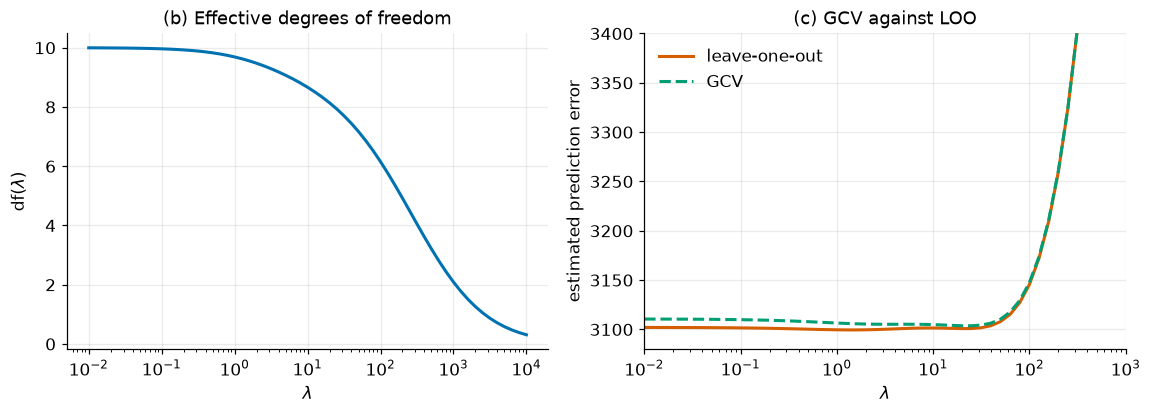

(d) degree 9, lambda = 1e-10, kappa(X) = 3.6e+06: relative difference from the SVD solution: augmented 1.7e-12, normal equations 5.7e-06


In [30]:
def solution_6_7():
    from sklearn.datasets import load_diabetes
    from sklearn.linear_model import Ridge
    from sklearn.model_selection import train_test_split
    from sklearn.preprocessing import StandardScaler

    X, y = load_diabetes(return_X_y=True)
    Xtr, _, ytr, _ = train_test_split(X, y, test_size=0.25, random_state=SEED)
    Z = StandardScaler().fit_transform(Xtr)

    def ridge_svd(Z, y, lam):
        xm, ym = Z.mean(axis=0), y.mean()
        U, s, Vt = np.linalg.svd(Z - xm, full_matrices=False)
        w = Vt.T @ ((s / (s ** 2 + lam)) * (U.T @ (y - ym)))
        return ym - xm @ w, w

    def ridge_aug(Z, y, lam):
        xm, ym = Z.mean(axis=0), y.mean()
        d = Z.shape[1]
        A = np.vstack([Z - xm, np.sqrt(lam) * np.eye(d)])
        w = np.linalg.lstsq(A, np.r_[y - ym, np.zeros(d)], rcond=None)[0]
        return ym - xm @ w, w

    def ridge_normal(Z, y, lam):
        xm, ym = Z.mean(axis=0), y.mean()
        Zc = Z - xm
        w = np.linalg.solve(Zc.T @ Zc + lam * np.eye(Z.shape[1]), Zc.T @ (y - ym))
        return ym - xm @ w, w

    ref = Ridge(alpha=10.0).fit(Z, ytr)
    print("(a) maximum difference from scikit-learn's Ridge(alpha=10):")
    for name, f in [("SVD", ridge_svd), ("augmented", ridge_aug), ("normal equations", ridge_normal)]:
        b, w = f(Z, ytr, 10.0)
        print(f"    {name:<17} weights {np.abs(w - ref.coef_).max():.1e}   intercept {abs(b - ref.intercept_):.1e}")

    # (b), (c): df and GCV from one SVD
    lams = np.logspace(-2, 4, 61)
    n = len(ytr)
    U, s, _ = np.linalg.svd(Z - Z.mean(axis=0), full_matrices=False)
    uy = U.T @ (ytr - ytr.mean())
    rss_resid = np.sum((ytr - ytr.mean()) ** 2) - np.sum(uy ** 2)       # part of y orthogonal to the columns of U
    df = np.array([np.sum(s ** 2 / (s ** 2 + l)) for l in lams])
    rss = np.array([np.sum(((l / (s ** 2 + l)) * uy) ** 2) + rss_resid for l in lams])
    gcv = n * rss / (n - 1 - df) ** 2                                   # the trace of the whole smoother is 1 + df (the intercept)
    # leave-one-out curve of Proposition 6.8, for comparison
    h = lambda l: 1 / n + (U ** 2) @ (s ** 2 / (s ** 2 + l))
    loo = np.array([np.mean(((ytr - ytr.mean() - U @ ((s ** 2 / (s ** 2 + l)) * uy)) / (1 - h(l))) ** 2) for l in lams])
    print(f"(b) df(lambda): 10 at lambda = 0.01, {np.interp(np.log10(10), np.log10(lams), df):.2f} at 10, {np.interp(np.log10(1000), np.log10(lams), df):.2f} at 1000, {df[-1]:.2f} at 10^4")
    print(f"(c) minimizer of GCV: lambda = {lams[gcv.argmin()]:.2f};  minimizer of LOO: lambda = {lams[loo.argmin()]:.2f};  "
          f"largest relative difference between GCV and LOO on the grid: {np.max(np.abs(gcv / loo - 1)):.4f}")

    fig, axes = plt.subplots(1, 2, figsize=(10.6, 3.9))
    axes[0].semilogx(lams, df, color=BLUE, lw=2)
    axes[0].set(xlabel=r"$\lambda$", ylabel=r"$\mathrm{df}(\lambda)$", title="(b) Effective degrees of freedom")
    axes[1].semilogx(lams, loo, color=VERMILION, lw=2, label="leave-one-out")
    axes[1].semilogx(lams, gcv, color=GREEN, lw=2, ls="--", label="GCV")
    axes[1].set(xlabel=r"$\lambda$", ylabel="estimated prediction error", title="(c) GCV against LOO")
    axes[1].set(ylim=(3080, 3400), xlim=(lams[0], 1e3))
    axes[1].legend(frameon=False)
    fig.tight_layout()
    plt.show()

    # (d) the badly conditioned design of Section 6.2.3, tiny penalty, no intercept
    x_grid = np.linspace(0, 1, 50)
    V = np.vander(x_grid, 10, increasing=True)
    w_true = np.ones(10)
    y_exact = V @ w_true
    lam_d = 1e-10
    U9, s9, Vt9 = np.linalg.svd(V, full_matrices=False)
    w_ref = Vt9.T @ ((s9 / (s9 ** 2 + lam_d)) * (U9.T @ y_exact))
    w_a = np.linalg.lstsq(np.vstack([V, np.sqrt(lam_d) * np.eye(10)]), np.r_[y_exact, np.zeros(10)], rcond=None)[0]
    w_n = np.linalg.solve(V.T @ V + lam_d * np.eye(10), V.T @ y_exact)
    rel = lambda w: np.linalg.norm(w - w_ref) / np.linalg.norm(w_ref)
    print(f"(d) degree 9, lambda = {lam_d:g}, kappa(X) = {np.linalg.cond(V):.1e}: relative difference from the SVD solution: "
          f"augmented {rel(w_a):.1e}, normal equations {rel(w_n):.1e}")


solution_6_7()

**(a)** The three implementations agree with scikit-learn's `Ridge(alpha=10)` to $10^{-12}$ or better: on a well-conditioned design (the standardized Diabetes data) the choice of algorithm is a matter of cost, not of accuracy. **(b)** The effective degrees of freedom decrease from 10 (at $\lambda = 0.01$) to 8.66 at $\lambda = 10$, 2.09 at $\lambda = 1000$ and 0.31 at $\lambda = 10^4$.

**(c)** GCV, which replaces each individual leverage $h_{ii}$ by their average $(1 + \mathrm{df})/n$, and the exact leave-one-out error give almost the same curve (the largest relative difference on the grid is 0.27%), but their minimizers differ by a factor of 16 ($\lambda = 25.1$ against $1.58$). The reason is the flatness of the curves: between $\lambda = 10^{-2}$ and $10^2$ the estimated error varies by a few units out of 3100, so a perturbation of a fraction of a percent moves the minimum far along the axis. The practical lesson of Section 6.3.4 applies: the value of $\lambda$ within the flat region hardly matters, and one should not read much into the exact location of the minimum.

**(d)** On the degree-9 monomial design (condition number $3.6 \cdot 10^6$), with $\lambda = 10^{-10}$, least squares on the augmented data agrees with the SVD solution to $10^{-11}$, whereas the normal equations differ by $10^{-5}$: forming $\mathbf{X}^\top\mathbf{X}$ squares the condition number, exactly as in Section 6.2.3, and a penalty as small as $10^{-10}$ does not repair it. When $\lambda$ is large enough compared with the smallest squared singular values, the penalty is itself a cure for ill-conditioning, which is another reason for using ridge in practice.

In [31]:
def solution_6_8():
    from scipy.optimize import minimize, check_grad
    from scipy.special import softmax, logsumexp
    from sklearn.datasets import load_iris
    from sklearn.linear_model import LogisticRegression
    from sklearn.preprocessing import StandardScaler

    def unpack(theta, K, d):
        return theta[:K * d].reshape(K, d), theta[K * d:]

    def loss_and_grad(theta, Z, y, K, lam):
        n, d = Z.shape
        W, b = unpack(theta, K, d)
        S = Z @ W.T + b
        logp = S - logsumexp(S, axis=1, keepdims=True)
        Y = np.eye(K)[y]
        J = -np.mean(np.sum(Y * logp, axis=1)) + 0.5 * lam * np.sum(W ** 2)
        P = np.exp(logp)
        gW = (P - Y).T @ Z / n + lam * W
        gb = (P - Y).mean(axis=0)
        return J, np.r_[gW.ravel(), gb]

    # (a) gradient check on random data
    rng = np.random.default_rng(SEED)
    Zr, yr, K, lam = rng.normal(size=(40, 5)), rng.integers(0, 3, 40), 3, 0.3
    th = rng.normal(size=3 * 5 + 3)
    err = check_grad(lambda t: loss_and_grad(t, Zr, yr, K, lam)[0], lambda t: loss_and_grad(t, Zr, yr, K, lam)[1], th)
    print(f"(a) norm of (analytic gradient - finite differences) = {err:.1e}   (norm of the gradient = {np.linalg.norm(loss_and_grad(th, Zr, yr, K, lam)[1]):.2f})")

    # (b) Iris
    X, y = load_iris(return_X_y=True)
    Z = StandardScaler().fit_transform(X)
    n, d = Z.shape
    K, lam = 3, 0.01
    res = minimize(loss_and_grad, np.zeros(K * d + K), args=(Z, y, K, lam), jac=True, method="L-BFGS-B", options={"maxiter": 5000, "gtol": 1e-10, "ftol": 1e-15})
    W, b = unpack(res.x, K, d)
    sk = LogisticRegression(C=1 / (n * lam), max_iter=10000, tol=1e-12).fit(Z, y)
    print(f"(b) L-BFGS: {res.nit} iterations, J = {res.fun:.6f}, norm of the gradient {np.linalg.norm(res.jac):.1e};  "
          f"max |W - sklearn| = {np.abs(W - sk.coef_).max():.1e},  max |b - sklearn| = {np.abs(b - sk.intercept_).max():.1e}")
    print(f"(c) sum over the classes of the weights, per feature: {np.round(W.sum(axis=0), 8)}")
    print("    the same, for the same model with an arbitrary vector added to all the class weights: probabilities change by "
          f"{np.abs(softmax(Z @ (W + 3.0).T + b, axis=1) - softmax(Z @ W.T + b, axis=1)).max():.1e}")


solution_6_8()

(a) norm of (analytic gradient - finite differences) = 1.1e-07   (norm of the gradient = 1.63)
(b) L-BFGS: 35 iterations, J = 0.243677, norm of the gradient 4.3e-09;  max |W - sklearn| = 4.7e-07,  max |b - sklearn| = 8.8e-07
(c) sum over the classes of the weights, per feature: [-0.  0. -0. -0.]
    the same, for the same model with an arbitrary vector added to all the class weights: probabilities change by 5.6e-16


**(a)** The analytic gradient agrees with finite differences to $1.3 \cdot 10^{-7}$, while the gradient itself has norm 1.63: the implementation is correct. **(b)** L-BFGS converges in 35 iterations to $J = 0.243677$, with a gradient of norm $4 \cdot 10^{-9}$, and the weights agree with those of scikit-learn's `LogisticRegression(C=1/(n*lam))` to $5 \cdot 10^{-7}$ (the intercepts to $9 \cdot 10^{-7}$), which confirms the correspondence $C = 1/(n\lambda)$ of Section 6.5 for the multinomial model. **(c)** The sum over the three classes of the weights of each feature is zero to eight decimals, as shown in Exercise 6.5, and adding the same constant to all the class weights changes the probabilities only at the level of rounding, $6 \cdot 10^{-16}$.

In [32]:
def solution_6_9():
    from sklearn.datasets import load_diabetes
    from sklearn.preprocessing import StandardScaler

    diab = load_diabetes(as_frame=True)
    y = diab.target.to_numpy()
    Z0 = StandardScaler().fit_transform(diab.data)
    names = list(diab.data.columns)
    j = names.index("bmi")
    n = len(y)
    eps = np.random.default_rng(SEED).normal(size=n)
    B_boot, lam_r = 300, 10.0

    def fit_ols(Z, y):
        Zc = Z - Z.mean(axis=0)
        return np.linalg.lstsq(Zc, y - y.mean(), rcond=None)[0]

    def fit_ridge(Z, y, lam):
        Zc = Z - Z.mean(axis=0)
        return np.linalg.solve(Zc.T @ Zc + lam * np.eye(Z.shape[1]), Zc.T @ (y - y.mean()))

    rows = []
    for rho in [0.0, 0.9, 0.99, 0.999]:
        col = rho * Z0[:, j] + np.sqrt(1 - rho ** 2) * eps
        col = (col - col.mean()) / col.std()
        Z = np.column_stack([Z0, col])                                    # the last column is the constructed copy
        Zc = Z - Z.mean(axis=0)
        w = fit_ols(Z, y)
        sigma2 = np.sum((y - y.mean() - Zc @ w) ** 2) / (n - Z.shape[1] - 1)
        se = np.sqrt(sigma2 * np.linalg.inv(Zc.T @ Zc)[j, j])
        vif = np.linalg.inv(np.corrcoef(Z, rowvar=False))[j, j]
        rng = np.random.default_rng(SEED)
        bo, so, br, sr = [], [], [], []
        for _ in range(B_boot):
            idx = rng.integers(0, n, n)
            wo, wr = fit_ols(Z[idx], y[idx]), fit_ridge(Z[idx], y[idx], lam_r)
            bo.append(wo[j]); so.append(wo[j] + wo[-1]); br.append(wr[j]); sr.append(wr[j] + wr[-1])
        rows.append({"rho": rho, "VIF of bmi": vif, "SE formula": se, "sigma*sqrt(VIF/n)": np.sqrt(sigma2 * vif / n),
                     "OLS: SD bmi": np.std(bo, ddof=1), "OLS: SD of sum": np.std(so, ddof=1),
                     "ridge: SD bmi": np.std(br, ddof=1), "ridge: SD of sum": np.std(sr, ddof=1)})
    print(pd.DataFrame(rows).set_index("rho").to_string(float_format=lambda v: f"{v:.2f}"))


solution_6_9()

       VIF of bmi  SE formula  sigma*sqrt(VIF/n)  OLS: SD bmi  OLS: SD of sum  ridge: SD bmi  ridge: SD of sum
rho                                                                                                           
0.000        1.51        3.17               3.17         3.29            4.20           3.17              4.09
0.900        6.35        6.50               6.50         6.18            3.36           4.95              3.29
0.990       56.74       19.42              19.42        18.42            3.30           5.29              3.24
0.999      559.17       60.96              60.96        58.10            3.29           2.63              3.23


**(a)** For standardized columns $[(\mathbf{X}^\top\mathbf{X})^{-1}]_{jj} = \mathrm{VIF}_j/n$, so the standard error is exactly $\hat\sigma\sqrt{\mathrm{VIF}_j/n}$ (the two columns of the table agree). As the constructed copy becomes more similar to `bmi`, the VIF goes from 1.5 ($\rho = 0$) to 6.3, 56.7 and 559.2, and the standard error of the coefficient of `bmi` from 3.17 to 6.50, 19.42 and 60.96: a factor of 19.2, equal to $\sqrt{559.2/1.51}$.

**(b)** The bootstrap standard deviations, 3.29, 6.18, 18.42 and 58.10, agree with the formula to within 10%: the theory holds. **(c)** The standard deviation of the **sum** of the two coefficients stays at about 3.3 for $\rho \ge 0.9$, however collinear the columns are. The data determine very well the *combined* effect of the two nearly identical features and cannot say how it is divided between them: the individual coefficients are unreliable, the prediction is not. (For $\rho = 0$ the sum has a larger deviation, 4.2, because the second column is then pure noise, which adds variance without information.)

**(d)** Ridge ($\lambda = 10$) cuts the standard deviation of each coefficient (4.95 against 6.18 at $\rho = 0.9$, 5.29 against 18.42 at $\rho = 0.99$, 2.63 against 58.10 at $\rho = 0.999$) while the standard deviation of the sum stays at about 3.2: the penalty shares the weight between the two copies, which is the stable thing to do, and makes the individual coefficients readable again (at the price of a bias that the table does not show).

In [33]:
def solution_6_10():
    import warnings
    from sklearn.datasets import load_breast_cancer
    from sklearn.linear_model import LogisticRegression
    from sklearn.metrics import log_loss
    from sklearn.model_selection import StratifiedKFold, cross_val_predict
    from sklearn.pipeline import make_pipeline
    from sklearn.preprocessing import StandardScaler

    X, y = load_breast_cancer(return_X_y=True)
    y = 1 - y
    C_grid = 10.0 ** np.arange(-3, 3.01, 0.5)
    clip = lambda p: np.clip(p, 1e-15, 1 - 1e-15)
    rows = []
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        for n in [30, 60, 120, 240]:
            rng = np.random.default_rng(SEED)
            rec = {"C_cv": [], "C_oracle": [], "ll_cv": [], "ll_oracle": [], "ll_unpen": []}
            kept = 0
            while kept < 30:
                perm = rng.permutation(len(y))
                tr, te = perm[:n], perm[n:]
                if min(y[tr].sum(), n - y[tr].sum()) < 6:
                    continue
                kept += 1
                cv = StratifiedKFold(5, shuffle=True, random_state=int(rng.integers(10 ** 6)))
                cv_ll, te_ll = [], []
                for C in C_grid:
                    pipe = make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=2000))
                    p_cv = cross_val_predict(pipe, X[tr], y[tr], cv=cv, method="predict_proba")[:, 1]
                    cv_ll.append(log_loss(y[tr], clip(p_cv)))
                    te_ll.append(log_loss(y[te], clip(pipe.fit(X[tr], y[tr]).predict_proba(X[te])[:, 1])))
                i_cv, i_or = int(np.argmin(cv_ll)), int(np.argmin(te_ll))
                unpen = make_pipeline(StandardScaler(), LogisticRegression(C=np.inf, max_iter=5000)).fit(X[tr], y[tr])
                rec["C_cv"].append(C_grid[i_cv]); rec["C_oracle"].append(C_grid[i_or])
                rec["ll_cv"].append(te_ll[i_cv]); rec["ll_oracle"].append(te_ll[i_or])
                rec["ll_unpen"].append(log_loss(y[te], clip(unpen.predict_proba(X[te])[:, 1])))
            rows.append({"n": n, "median C (CV)": np.median(rec["C_cv"]), "median C (oracle)": np.median(rec["C_oracle"]),
                         "lambda (CV)": 1 / (n * np.median(rec["C_cv"])), "lambda (oracle)": 1 / (n * np.median(rec["C_oracle"])),
                         "test log-loss, CV choice": np.mean(rec["ll_cv"]), "oracle": np.mean(rec["ll_oracle"]), "unpenalized": np.mean(rec["ll_unpen"])})
    print(pd.DataFrame(rows).set_index("n").to_string(float_format=lambda v: f"{v:.4g}"))


solution_6_10()

     median C (CV)  median C (oracle)  lambda (CV)  lambda (oracle)  test log-loss, CV choice  oracle  unpenalized
n                                                                                                                 
30           20.81                  1     0.001602          0.03333                    0.2137  0.1431       0.3866
60               1                  1      0.01667          0.01667                    0.1525  0.1218       0.3868
120              1                  1     0.008333         0.008333                    0.1073 0.09948       0.4829
240              1                  1     0.004167         0.004167                   0.09403 0.08825       0.8462


The best $C$ is remarkably stable. The oracle value (the one that minimizes the test log-loss) is $C = 1$ for every $n$, and so is the median value chosen by cross-validation for $n \ge 60$; only for $n = 30$ is the CV choice erratic (median 20.8): with 30 patients the cross-validated log-loss is a noisy criterion, the winner's-curse effect of Chapter 5. Since $\lambda = 1/(Cn)$, a constant $C$ means that **the best penalty decreases like $1/n$**: $0.0167$, $0.0083$ and $0.0042$ for $n = 60, 120, 240$. In the formulation of Section 6.5, with the loss averaged over the examples, the right strength of the penalty falls as the training set grows, while in the formulation of scikit-learn ($C$ multiplies the *sum* of the losses) it stays the same. This is the quantitative form of the principle that more data can support a more flexible model.

The test log-loss of the model selected by cross-validation decreases from 0.214 to 0.094, and the gap to the oracle shrinks from 0.07 to 0.006 as $n$ grows. The unpenalized model is much worse and does not improve with $n$ (0.387, 0.387, 0.483 and 0.846): with 30 standardized features the training sets are separable, and the solver stops at the iteration limit with large weights and overconfident probabilities (Section 6.4.4); its figures reflect the optimizer's stopping rule, not a property of the model.

## C.7 Chapter 7

### Manual exercises

**Solution 7.1 — Gradient descent by hand.**

(a) $\nabla f = (2w_1, 8w_2)$ and $\mathbf{H} = \mathrm{diag}(2, 8)$, so $\mu = 2$, $L = 8$, $\kappa = 4$, and the minimizer is $\mathbf{w}^\ast = \mathbf{0}$.

(b) With $\eta = 1/L = \tfrac18$ the factors are $1 - \tfrac18\cdot 2 = \tfrac34$ and $1 - \tfrac18\cdot 8 = 0$, so $\mathbf{w}_k = (4\cdot(\tfrac34)^k,\ 0)$ for $k \ge 1$: the iterates are $(3, 0)$, $(2.25, 0)$, $(1.6875, 0)$. The steepest direction is solved in one step (its factor is zero) and the flat one decays like $\tfrac34$ per step, the rate $1 - 1/\kappa$ of Theorem 7.3.

(c) The best step is $\eta^\ast = 2/(L + \mu) = 0.2$, with factors $1 - 0.4 = 0.6$ and $1 - 1.6 = -0.6$: the rate is $\rho = 0.6 = (\kappa - 1)/(\kappa + 1) = \tfrac35$, and both coordinates are multiplied by $\pm 0.6$. The iterates are $(2.4, -0.6)$, $(1.44, 0.36)$, $(0.864, -0.216)$. The step $\eta^\ast$ balances the two directions: the flat one converges from one side and the steep one overshoots to the other, by the same factor.

(d) The iteration converges for $0 < \eta < 2/L = \tfrac14$. For $\eta = \tfrac14$ the factors are $\tfrac12$ and $-1$: $\mathbf{w}_k = (4\cdot 0.5^k,\ (-1)^k)$, which gives $(2, -1)$, $(1, 1)$, $(0.5, -1)$: the first coordinate converges, the second oscillates forever between $\pm 1$, so the iteration does not converge (it is the boundary case of Theorem 7.3, item 1).

**Solution 7.2 — The smoothness constant of a logistic regression.**

(a) With $s = \sigma(m)$, $\ell'(m) = -\sigma(-m)$ and $\ell''(m) = \sigma(m)\sigma(-m) = s(1 - s)$. Since $s \in (0, 1)$, $s(1 - s) \le \tfrac14$ (the maximum, at $s = \tfrac12$, i.e. $m = 0$), and it is positive. The Hessian of the objective is $\frac1n\tilde{\mathbf{X}}^\top\mathrm{diag}(\ell''(m_i))\tilde{\mathbf{X}} + \lambda\,\mathrm{diag}(\text{penalized coordinates}) \preceq \frac1{4n}\tilde{\mathbf{X}}^\top\tilde{\mathbf{X}} + \lambda\mathbf{I}$ (the signs $2y_i - 1 = \pm 1$ disappear in the squares), whose largest eigenvalue is $\lVert\tilde{\mathbf{X}}\rVert_2^2/(4n) + \lambda$.

(b) For the rows $(1, -1), (1, 0), (1, 1)$ we get $\tilde{\mathbf{X}}^\top\tilde{\mathbf{X}} = \mathrm{diag}(3, 2)$, so $\lVert\tilde{\mathbf{X}}\rVert_2^2 = 3$ and $L = 3/(4\cdot 3) = \tfrac14$. At the origin all the scores vanish, $\ell'' = \tfrac14$ for every example, and the Hessian is exactly $\frac1{12}\,\mathrm{diag}(3, 2) = \mathrm{diag}(\tfrac14, \tfrac16)$: its largest eigenvalue is $\tfrac14 = L$. The bound is tight at the origin and is loose elsewhere (Section 7.3.4: fourteen times too large at the minimizer of the Breast Cancer problem).

(c) At the origin $\mathbf{p} - \mathbf{y} = (\tfrac12, -\tfrac12, -\tfrac12)$ and $\nabla f = \frac13\tilde{\mathbf{X}}^\top(\mathbf{p} - \mathbf{y}) = \frac13(-\tfrac12,\ -1) = (-\tfrac16, -\tfrac13)$. With $\eta = 1/L = 4$, $\mathbf{w}_1 = (0, 0) + 4(\tfrac16, \tfrac13) = (\tfrac23, \tfrac43)$. The loss at the origin is $\log 2 = 0.6931$. At $\mathbf{w}_1$ the scores are $-\tfrac23, \tfrac23, 2$ and the mean loss is $\frac13[\log(1 + e^{-2/3}) + \log(1 + e^{-2/3}) + \log(1 + e^{-2})] = \frac13(0.4144 + 0.4144 + 0.1269) = 0.3186$. The descent lemma with $\eta = 1/L$ guarantees $f(\mathbf{w}_1) \le f(\mathbf{w}_0) - \frac1{2L}\lVert\nabla f(\mathbf{w}_0)\rVert^2 = 0.6931 - 2\cdot(\tfrac1{36} + \tfrac19) = 0.6931 - 0.2778 = 0.4153$. The actual value $0.3186$ satisfies the inequality, with a decrease of $0.3745$ against the guaranteed $0.2778$.

**Solution 7.3 — The heavy ball on a quadratic.**

(a) $\kappa = 100$. The best step is $2/(L + \mu) = 2/101$ with $\rho = 99/101 = 0.9802$, and $\rho^k = 10^{-6}$ gives $k = \ln 10^6/\ln(101/99) = 690.8$, so about $691$ iterations (equal to $\frac\kappa2\ln 10^6 = 50\cdot 13.82$, the bound of Theorem 7.3, item 4).

(b) $\sqrt L + \sqrt\mu = 11$, so $\eta = 4/121 = 0.0331$, $\beta = (9/11)^2 = 0.6694$ and $\rho = \sqrt\beta = 9/11 = 0.8182$. Then $k = \ln 10^6/\ln(11/9) = 68.8$: about $69$ iterations, ten times fewer, the factor $\sqrt\kappa = 10$ of the theory.

(c) For $\lambda = \mu = 1$: $1 + \beta - \eta\mu = 1 + 0.6694 - 0.0331 = 1.6364 = 2\cdot\tfrac9{11}$, so $z^2 - \tfrac{18}{11}z + (\tfrac9{11})^2 = (z - \tfrac9{11})^2$: a double root $\tfrac9{11} = \sqrt\beta$. For $\lambda = L = 100$: $1 + \beta - 100\eta = 1.6694 - 3.3058 = -1.6364$, so $z^2 + \tfrac{18}{11}z + (\tfrac9{11})^2 = (z + \tfrac9{11})^2$: a double root $-\tfrac9{11}$, of modulus $\sqrt\beta$. For the eigenvalues between the two the roots are complex conjugates of modulus exactly $\sqrt\beta$ (the product of the roots is $\beta$), so every direction contracts at the same rate $\sqrt\beta$ and the double roots at the two ends produce the factor $(k + 1)$ of Theorem 7.8.

**Solution 7.4 — SGD for a mean.**

(a) The update is $w_{k+1} = w_k - \eta_k(w_k - x_k) = (1 - \eta_k)w_k + \eta_kx_k$. With $\eta_k = 1/(k + 1)$: $\eta_0 = 1$ gives $w_1 = x_0$, and then $(k + 1)w_{k+1} = kw_k + x_k$, so $kw_k = x_0 + \dots + x_{k-1}$: $w_k$ is the sample mean of the first $k$ observations. Its variance is $\sigma^2/k$, and since $f(w) - f^\ast = \tfrac12(w - m)^2$, $\mathbb{E}f(w_k) - f^\ast = \sigma^2/(2k)$. This is the $O(1/k)$ rate of Theorem 7.12, and it is attained exactly: no step schedule can do better than the statistical error of the sample mean. The schedule $\eta_k = 1/(k + 1)$ has $\beta = 1/\mu$ and $\gamma = 1$, the limiting case of the hypothesis $\beta > 1/\mu$ of the theorem, for which its constant $\beta^2L\sigma^2/(2(\beta\mu - 1))$ is infinite; with $\beta = \gamma = 2$ ($\eta_k = 2/(k + 2)$) the theorem gives $\nu = \max\{2\sigma^2, 2(f(w_0) - f^\ast)\}$, of the same order $\sigma^2/k$ but with a larger constant.

(b) Write $w_{k+1} - m = (1 - \eta)(w_k - m) + \eta(x_k - m)$. The two terms are independent, so $V_{k+1} = (1 - \eta)^2V_k + \eta^2\sigma^2$, which converges for $\lvert 1 - \eta\rvert < 1$ to $V_\infty = \eta^2\sigma^2/(1 - (1 - \eta)^2) = \eta\sigma^2/(2 - \eta)$. Then $\mathbb{E}f - f^\ast = \tfrac12V_\infty = \eta\sigma^2/(2(2 - \eta))$, against the floor $L\eta\sigma^2/(2\mu) = \eta\sigma^2/2$ of Theorem 7.11: the floor overestimates the true one by the factor $2 - \eta \in [1, 2)$.

(c) For $\eta = 0.1$, $\sigma^2 = 1$: exact $0.1/(2\cdot 1.9) = 0.02632$, floor $0.05$, ratio $1.9$. The theorem is within a factor of two of the truth in this case, and the exact floor is proportional to $\eta$, as the theorem says.

**Solution 7.5 — Early stopping and ridge in two directions.**

(a) $\varphi_1(k) = 1 - (1 - 1)^k = 1$ for every $k \ge 1$ and $\varphi_2(k) = 1 - 0.99^k$.

(b) The ridge factor with $\lambda = 1/(\eta k) = 1/k$ is $h_j/(h_j + 1/k)$:

| $k$ | $\varphi_2(k) = 1 - 0.99^k$ | ridge $0.01/(0.01 + 1/k)$ | ratio |
|---|---|---|---|
| 1 | 0.0100 | 0.0099 | 1.010 |
| 10 | 0.0956 | 0.0909 | 1.052 |
| 100 | 0.6340 | 0.5000 | 1.268 |
| 1000 | 0.99996 | 0.9091 | 1.100 |

(c) We need $1 - 0.99^k \ge \tfrac12$, that is $k \ge \ln 2/(-\ln 0.99) = 68.97$, so $k = 69$. The ridge factor is $\tfrac12$ exactly when $\lambda = h_2 = 0.01$, which corresponds to $k = 1/(\eta\lambda) = 100$ in the correspondence $\lambda = 1/(\eta k)$: gradient descent recovers the second direction half way a little *earlier* than the correspondence predicts, as the ratio $1.27 > 1$ at $k = 100$ shows.

(d) All the ratios of (b) lie between $1$ and $2$. For the first direction the ridge factor is $k/(k + 1)$ and the ratio is $(k + 1)/k$: $2$ at $k = 1$ (the upper bound of Proposition 7.13 is attained), $1.1$ at $k = 10$, and tends to $1$. For the second direction the ratio never exceeds $1.27$ in the table. Both factors increase from $0$ to $1$ together, which is the content of the proposition: stopping at $k$ steps and ridge with $\lambda = 1/(\eta k)$ filter the same directions to within a factor of two.

### Python exercises

(a) relative error of the gradient: 7.3e-09
 lambda     L       mu  kappa  iterations  kappa ln(1e6)
      0 3.919 0.009379  417.8        5677           5773
   0.01 3.929  0.01938  202.7        2676           2801
    0.1 4.019   0.1094  36.74         426          507.6
      1 4.919    1.009  4.873          44          67.32
(d) slope of log(iterations) against log(kappa): 1.09


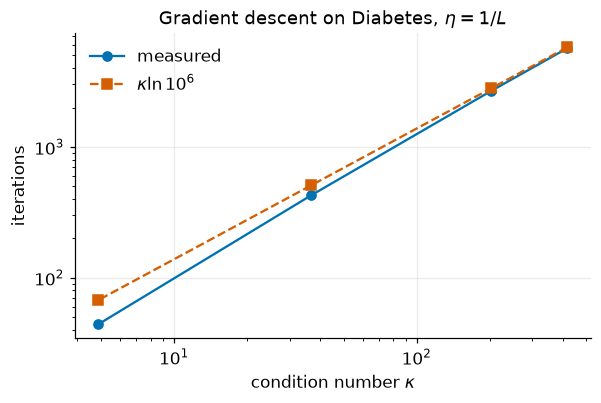

In [34]:
def solution_7_6():
    from sklearn.datasets import load_diabetes
    from sklearn.model_selection import train_test_split
    from sklearn.preprocessing import StandardScaler

    diab = load_diabetes()
    Xtr, _, ytr, _ = train_test_split(diab.data, diab.target, test_size=0.25, random_state=SEED)
    Z = StandardScaler().fit_transform(Xtr)
    n = len(ytr)
    yc = ytr - ytr.mean()

    def objective(w, lam):
        r = Z @ w - yc
        return 0.5 * np.mean(r**2) + 0.5 * lam * w @ w, Z.T @ r / n + lam * w

    # (a) gradient check by central differences
    rng = np.random.default_rng(SEED)
    w_try = rng.normal(size=Z.shape[1])
    g_fd = np.array([(objective(w_try + 1e-6 * e, 0.1)[0] - objective(w_try - 1e-6 * e, 0.1)[0]) / 2e-6 for e in np.eye(Z.shape[1])])
    g_an = objective(w_try, 0.1)[1]
    print(f"(a) relative error of the gradient: {np.linalg.norm(g_an - g_fd) / np.linalg.norm(g_fd):.1e}")

    rows = []
    for lam in [0.0, 0.01, 0.1, 1.0]:
        H = Z.T @ Z / n + lam * np.eye(Z.shape[1])
        ev = np.linalg.eigvalsh(H)
        L, mu = ev[-1], ev[0]
        w_star = np.linalg.solve(H, Z.T @ yc / n)
        w = np.zeros(Z.shape[1])
        k = 0
        while np.linalg.norm(w - w_star) > 1e-6 * np.linalg.norm(w_star) and k < 200_000:
            w = w - objective(w, lam)[1] / L
            k += 1
        rows.append({"lambda": lam, "L": L, "mu": mu, "kappa": L / mu, "iterations": k, "kappa ln(1e6)": L / mu * np.log(1e6)})
    df = pd.DataFrame(rows)
    print(df.to_string(index=False, float_format=lambda v: f"{v:.4g}"))
    slope, intercept = np.polyfit(np.log(df["kappa"]), np.log(df["iterations"]), 1)
    print(f"(d) slope of log(iterations) against log(kappa): {slope:.2f}")
    fig, ax = plt.subplots(figsize=(5.6, 3.8))
    ax.loglog(df["kappa"], df["iterations"], "o-", color=BLUE, label="measured")
    ax.loglog(df["kappa"], df["kappa ln(1e6)"], "s--", color=VERMILION, label=r"$\kappa\ln 10^6$")
    ax.set(xlabel=r"condition number $\kappa$", ylabel="iterations", title="Gradient descent on Diabetes, $\\eta = 1/L$")
    ax.legend(frameon=False)
    fig.tight_layout()
    plt.show()


solution_7_6()

The iteration counts follow the condition number almost proportionally: $5{,}677$, $2{,}676$, $426$ and $44$ iterations for $\kappa = 417.8$, $202.7$, $36.7$ and $4.9$, against $\kappa\ln 10^6 = 5{,}773$, $2{,}801$, $508$ and $67$. The bound of Theorem 7.3 is nearly attained for $\lambda = 0$ and $0.01$ ($98\%$ and $96\%$) and loose by about a third for $\lambda = 1$: the bound is the worst case, in which the starting error lies entirely along the flattest direction, and the measured count is smaller when the weight of $\mathbf{w}^\ast$ on that direction is only a part of $\lVert\mathbf{w}^\ast\rVert$. Because the ratio of measured count to bound is not constant, the slope of the log-log fit is $1.09$ and not exactly $1$. The gradient check gives a relative error of $7 \cdot 10^{-9}$. A ridge penalty of $\lambda = 1$ makes the problem $85$ times better conditioned than least squares and the descent $130$ times faster, the practical face of the remark of Section 7.2.2 that regularization helps the optimization as well as the statistics.



(a) f* = 0.15264447; L_glob = 0.7575; local L = 0.0625, mu = 0.0136; L_glob/L_loc = 12.1


(b)-(c) gradient evaluations to a gap below 1e-8:
   GD 1/L_glob: 217;  GD best constant (25.76): 15;  backtracking: 11;  L-BFGS: 10 (9 iterations);  Newton: 6 steps


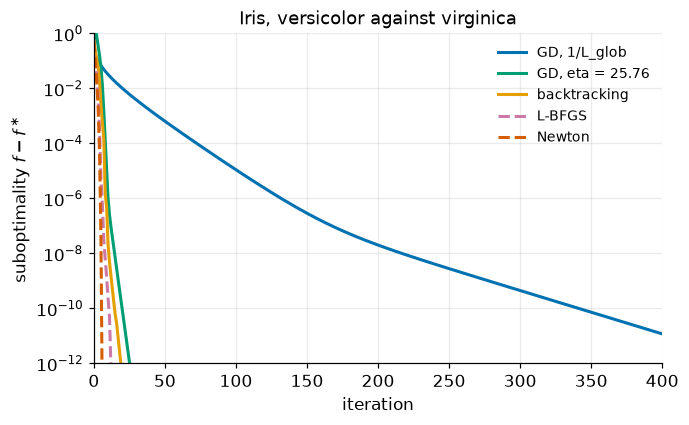

In [35]:
def solution_7_7():
    from scipy.optimize import minimize
    from scipy.special import expit
    from sklearn.datasets import load_iris
    from sklearn.model_selection import train_test_split
    from sklearn.preprocessing import StandardScaler

    iris = load_iris()
    mask = iris.target > 0                                     # versicolor (0) against virginica (1)
    X, y = iris.data[mask], (iris.target[mask] == 2).astype(float)
    Xtr, _, ytr, _ = train_test_split(X, y, test_size=0.25, random_state=SEED, stratify=y)
    Z = StandardScaler().fit_transform(Xtr)
    A = np.c_[np.ones(len(ytr)), Z]
    n, p = A.shape
    lam = 0.01
    pen = np.r_[0.0, np.ones(p - 1)]

    def obj(w):
        s = A @ w
        return np.mean(np.logaddexp(0, s) - ytr * s) + 0.5 * lam * np.sum(pen * w**2), A.T @ (expit(s) - ytr) / n + lam * pen * w

    def hess(w):
        q = expit(A @ w)
        return (A.T * (q * (1 - q))) @ A / n + lam * np.diag(pen)

    w = np.zeros(p)
    for _ in range(30):
        w = w - np.linalg.solve(hess(w), obj(w)[1])
    w_star, f_star = w, obj(w)[0]
    L_glob = np.linalg.eigvalsh(A.T @ A / n)[-1] / 4 + lam
    ev = np.linalg.eigvalsh(hess(w_star))
    L_loc, mu_loc = ev[-1], ev[0]
    print(f"(a) f* = {f_star:.8f}; L_glob = {L_glob:.4f}; local L = {L_loc:.4f}, mu = {mu_loc:.4f}; L_glob/L_loc = {L_glob / L_loc:.1f}")

    def gd(eta, iters=4000):
        w, gaps = np.zeros(p), []
        for _ in range(iters):
            f, g = obj(w)
            gaps.append(f - f_star)
            w = w - eta * g
        return np.array(gaps)

    def first_below(gaps, tol=1e-8):
        above = np.flatnonzero(gaps >= tol)
        k = int(above[-1]) + 1 if len(above) else 0
        return k if k < len(gaps) else None

    curves = {"GD, 1/L_glob": gd(1 / L_glob)}
    best_eta, best_k = None, None
    for eta in np.linspace(1 / L_glob, 4 / L_loc, 60):
        k = first_below(gd(eta))
        if k is not None and (best_k is None or k < best_k):
            best_eta, best_k = eta, k
    curves[f"GD, eta = {best_eta:.2f}"] = gd(best_eta)
    # backtracking (Armijo, halving; the step is multiplied by 2 at the start of each iteration)
    w, eta, gaps_bt, n_grad = np.zeros(p), 1.0, [], 0
    for _ in range(4000):
        f, g = obj(w)
        gaps_bt.append(f - f_star)
        if gaps_bt[-1] < 1e-14:
            break
        eta *= 2
        while obj(w - eta * g)[0] > f - 0.5 * eta * g @ g:
            eta /= 2
        w = w - eta * g
    curves["backtracking"] = np.array(gaps_bt)
    # L-BFGS
    hist, count = [], [0]
    def fun(v):
        count[0] += 1
        return obj(v)
    minimize(fun, np.zeros(p), jac=True, method="L-BFGS-B", callback=lambda v: hist.append((obj(v)[0] - f_star, count[0])),
             options={"maxiter": 500, "gtol": 1e-12, "ftol": 1e-16})
    hist = np.array(hist)
    k_lb = int(np.flatnonzero(hist[:, 0] < 1e-8)[0])
    curves["L-BFGS"] = hist[:, 0]
    # Newton
    w, gaps_nt = np.zeros(p), []
    for _ in range(10):
        f, g = obj(w)
        gaps_nt.append(f - f_star)
        w = w - np.linalg.solve(hess(w), g)
    curves["Newton"] = np.array(gaps_nt)

    print(f"(b)-(c) gradient evaluations to a gap below 1e-8:")
    print(f"   GD 1/L_glob: {first_below(curves['GD, 1/L_glob'])};  GD best constant ({best_eta:.2f}): {best_k};  backtracking: {first_below(curves['backtracking'])};  "
          f"L-BFGS: {int(hist[k_lb, 1])} ({k_lb + 1} iterations);  Newton: {int(np.flatnonzero(np.array(gaps_nt) < 1e-8)[0])} steps")
    fig, ax = plt.subplots(figsize=(6.4, 4.0))
    for (name, c), color, ls in zip(curves.items(), [BLUE, GREEN, ORANGE, PURPLE, VERMILION], ["-", "-", "-", "--", "--"]):
        ax.plot(np.maximum(c, 1e-16), color=color, ls=ls, lw=2, label=name)
    ax.set(yscale="log", xlim=(0, 400), ylim=(1e-12, 1), xlabel="iteration", ylabel=r"suboptimality $f - f^\ast$",
           title="Iris, versicolor against virginica")
    ax.legend(frameon=False, fontsize=9)
    fig.tight_layout()
    plt.show()


solution_7_7()

On this problem, versicolor against virginica, the two classes overlap (an unpenalized near-hard-margin classifier misclassifies two of the $75$ training flowers and the unpenalized logistic fit has a finite norm), so the penalty $\lambda = 0.01$ is not needed for existence, only for conditioning. The minimum is $f^\ast = 0.15264447$; the global bound is $L_{\text{glob}} = 0.757$, the curvature at the minimizer is $L_{\text{loc}} = 0.0625$ (with $\mu_{\text{loc}} = 0.0136$), a ratio of $12.1$. The numbers of gradient evaluations to reach a suboptimality of $10^{-8}$ are: gradient descent with $\eta = 1/L_{\text{glob}}$, $217$; with the best constant step found in the search, $\eta = 25.8$ (the stability limit is $2/L_{\text{loc}} = 32$), $15$; backtracking, $11$; L-BFGS, $10$ evaluations ($9$ iterations); Newton, $6$ steps. The gain of the best constant step, $217/15 = 14.5$, is of the order of the ratio $L_{\text{glob}}/L_{\text{loc}} = 12.1$, as in the Breast Cancer experiment of Section 7.3.4 (where the best constant step gained $1631/65 = 25$ against a ratio of $14.4$): the loss of a method that obeys the global bound is the ratio between the worst and the local curvature. The curves of the three first-order methods are straight lines on the logarithmic scale (linear convergence), those of L-BFGS and Newton bend downward (superlinear and quadratic).



kappa = 36.74, sqrt(kappa) = 6.06; heavy-ball eta = 0.733 (2/L = 0.498), beta = 0.5138
  GD, eta = 2/(L+mu)           328
  heavy ball (Theorem 7.8)     68
  Nesterov, strongly convex    107
  heavy ball, beta = 0.99      3723
  heavy ball, beta = 0         not reached
(a) iterations(GD) / iterations(heavy ball) = 4.8, iterations(GD) / iterations(Nesterov) = 3.1; sqrt(kappa) = 6.1
(b) beta = 0.99: the distance after 100, 1000, 3000 iterations is 5.7e-01, 7.7e-03, 1.9e-07; it increases at 48% of the first 600 iterations (oscillation)
    beta = 0 keeps the heavy-ball step 0.733 > 2/L = 0.498: plain gradient descent diverges (distance above 1e12 at iteration 43)


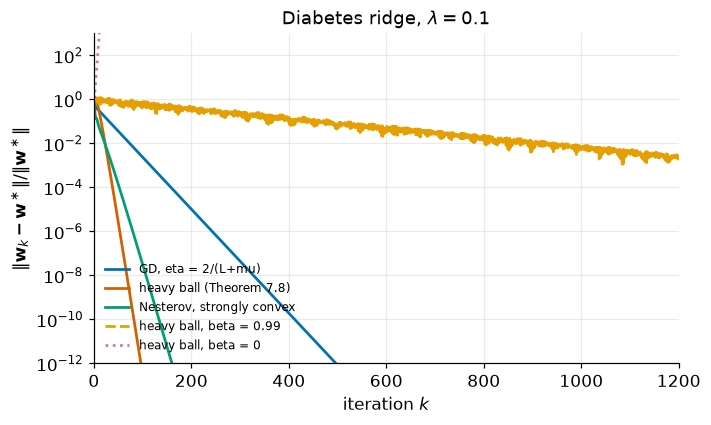

In [36]:
def solution_7_8():
    from sklearn.datasets import load_diabetes
    from sklearn.model_selection import train_test_split
    from sklearn.preprocessing import StandardScaler

    diab = load_diabetes()
    Xtr, _, ytr, _ = train_test_split(diab.data, diab.target, test_size=0.25, random_state=SEED)
    Z = StandardScaler().fit_transform(Xtr)
    n, lam = len(ytr), 0.1
    yc = ytr - ytr.mean()
    H = Z.T @ Z / n + lam * np.eye(Z.shape[1])
    b = Z.T @ yc / n
    ev = np.linalg.eigvalsh(H)
    L, mu = ev[-1], ev[0]
    kappa = L / mu
    w_star = np.linalg.solve(H, b)
    sk = np.sqrt(kappa)

    def run(eta, beta, kind, iters=6000):
        w, w_prev, dist = np.zeros(10), np.zeros(10), np.empty(iters)
        for k in range(iters):
            dist[k] = np.linalg.norm(w - w_star) / np.linalg.norm(w_star)
            if not np.isfinite(dist[k]) or dist[k] > 1e12:
                dist[k:] = np.inf
                break
            if kind == "hb":
                w_new = w - eta * (H @ w - b) + beta * (w - w_prev)
            else:
                y = w + beta * (w - w_prev)
                w_new = y - eta * (H @ y - b)
            w_prev, w = w, w_new
        return dist

    def count(d, tol=1e-8):
        above = np.flatnonzero(d >= tol)
        k = int(above[-1]) + 1 if len(above) else 0
        return k if k < len(d) else None

    eta_hb = 4 / (np.sqrt(L) + np.sqrt(mu)) ** 2
    beta_hb = ((sk - 1) / (sk + 1)) ** 2
    runs = {
        "GD, eta = 2/(L+mu)": run(2 / (L + mu), 0.0, "hb"),
        "heavy ball (Theorem 7.8)": run(eta_hb, beta_hb, "hb"),
        "Nesterov, strongly convex": run(1 / L, (sk - 1) / (sk + 1), "nag"),
        "heavy ball, beta = 0.99": run(eta_hb, 0.99, "hb"),
        "heavy ball, beta = 0": run(eta_hb, 0.0, "hb"),
    }
    print(f"kappa = {kappa:.2f}, sqrt(kappa) = {sk:.2f}; heavy-ball eta = {eta_hb:.3f} (2/L = {2 / L:.3f}), beta = {beta_hb:.4f}")
    cnt = {k: count(v) for k, v in runs.items()}
    for k, v in cnt.items():
        print(f"  {k:<28} {v if v else 'not reached'}")
    print(f"(a) iterations(GD) / iterations(heavy ball) = {cnt['GD, eta = 2/(L+mu)'] / cnt['heavy ball (Theorem 7.8)']:.1f}, "
          f"iterations(GD) / iterations(Nesterov) = {cnt['GD, eta = 2/(L+mu)'] / cnt['Nesterov, strongly convex']:.1f}; sqrt(kappa) = {sk:.1f}")
    d99 = runs["heavy ball, beta = 0.99"]
    print(f"(b) beta = 0.99: the distance after 100, 1000, 3000 iterations is {d99[100]:.1e}, {d99[1000]:.1e}, {d99[3000]:.1e}; "
          f"it increases at {100 * np.mean(np.diff(d99[:600]) > 0):.0f}% of the first 600 iterations (oscillation)")
    d0 = runs["heavy ball, beta = 0"]
    print(f"    beta = 0 keeps the heavy-ball step {eta_hb:.3f} > 2/L = {2 / L:.3f}: plain gradient descent diverges (distance above 1e12 at iteration {int(np.flatnonzero(~np.isfinite(d0))[0])})")
    fig, ax = plt.subplots(figsize=(6.6, 4.0))
    for (name, d), color, ls in zip(runs.items(), [BLUE, VERMILION, GREEN, ORANGE, PURPLE], ["-", "-", "-", "--", ":"]):
        ax.plot(np.maximum(d, 1e-14), color=color, ls=ls, lw=1.8, label=name)
    ax.set(yscale="log", xlim=(0, 1200), ylim=(1e-12, 1e3), xlabel="iteration $k$", ylabel=r"$\|\mathbf{w}_k - \mathbf{w}^\ast\| / \|\mathbf{w}^\ast\|$",
           title="Diabetes ridge, $\\lambda = 0.1$")
    ax.legend(frameon=False, fontsize=8, loc="lower left")
    fig.tight_layout()
    plt.show()


solution_7_8()

With $\lambda = 0.1$ ($\kappa = 36.74$, $\sqrt\kappa = 6.06$) the counts to reach a relative distance of $10^{-8}$ are $328$ iterations for gradient descent with $\eta = 2/(L + \mu)$ (the bound $\frac\kappa2\ln 10^8 = 338$), $68$ for the heavy ball with the parameters of Theorem 7.8 ($\eta = 0.733$, $\beta = 0.514$), and $107$ for Nesterov's strongly convex version. (a) The ratios are $4.8$ and $3.1$, against $\sqrt\kappa = 6.1$: the heavy ball is not quite $\sqrt\kappa$ times faster at this moderate $\kappa$ because the error bound of Theorem 7.8 carries the factor $(k + 1)$ of the double roots (with only $\rho^k$ the ratio would be $6.1$), and Nesterov's version uses the smaller step $1/L$ and is slower still, as in Section 7.5. (b) The momentum parameter must be matched to the step. With $\beta = 0.99$ the rate falls to $\sqrt{0.99} = 0.995$, and the run needs $3{,}723$ iterations, eleven times more than plain gradient descent: the iterate overshoots and spirals toward $\mathbf{w}^\ast$ (the distance increases at $48\%$ of the first 600 iterations; it is $0.57$ after $100$ iterations, $7.7 \cdot 10^{-3}$ after $1{,}000$ and $1.9 \cdot 10^{-7}$ after $3{,}000$). With $\beta = 0$ and the heavy-ball step $\eta = 0.733$, which exceeds $2/L = 0.498$, the iteration is plain gradient descent *above its stability limit*: it diverges (the distance exceeds $10^{12}$ at iteration $43$). The step of Theorem 7.8 is stable only *together* with its momentum, which damps the oscillation of the steep directions: momentum is part of the stability of the method, not an optional accelerator.



suboptimality after 10 epochs (rows: batch size, columns: eta * L)
      0.01     0.03     0.10     0.30     1.00     3.00     10.00    30.00    100.00   300.00
1   1.09e-01 4.59e-02 1.14e-02 4.51e-02 3.00e-01 2.11e+00 1.52e+01 5.79e+01 2.62e+02 1.24e+03
4   2.71e-01 1.33e-01 5.40e-02 1.69e-02 5.10e-02 2.14e-01 1.66e+00 1.00e+01 4.87e+01 1.58e+02
16  6.76e-01 3.26e-01 1.49e-01 6.85e-02 2.17e-02 4.57e-02 6.64e-02 1.49e+00 1.35e+01 3.94e+01
64  1.43e+00 7.95e-01 3.60e-01 1.78e-01 8.24e-02 3.68e-02 2.96e-02 1.46e-01 5.67e-01 5.60e+00
256 1.98e+00 1.54e+00 8.42e-01 4.07e-01 1.85e-01 8.84e-02 3.24e-02 1.13e-02 9.10e-02 1.09e+00
best eta * L: {1: 0.1, 4: 0.3, 16: 1.0, 64: 10.0, 256: 30.0}
(b) slope of log(best eta L) against log(B): 1.08
(c) best suboptimality after 10 epochs: B=1: 1.14e-02  B=4: 1.69e-02  B=16: 2.17e-02  B=64: 2.96e-02  B=256: 1.13e-02   | updates per epoch: 1347, 337, 85, 22, 6


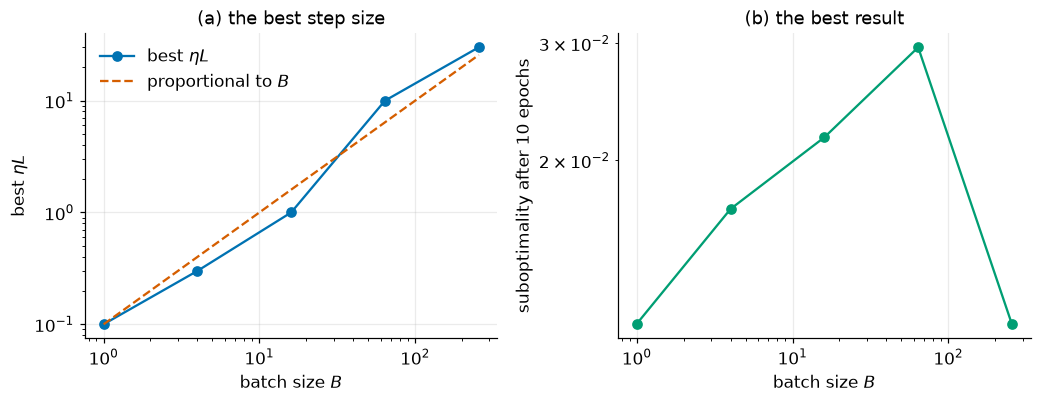

In [37]:
def solution_7_9():
    from scipy.optimize import minimize
    from scipy.special import logsumexp
    from sklearn.datasets import load_digits
    from sklearn.model_selection import train_test_split
    from sklearn.preprocessing import StandardScaler

    dg = load_digits()
    Xtr, Xte, ytr, yte = train_test_split(dg.data, dg.target, test_size=0.25, random_state=SEED, stratify=dg.target)
    sc = StandardScaler().fit(Xtr)
    Z = sc.transform(Xtr)
    n, d = Z.shape
    K = 10
    Y = np.eye(K)[ytr]
    lam = 1 / (3.16 * n)

    def obj(w, idx=None):
        W, b = w[:K * d].reshape(K, d), w[K * d:]
        A, Yb = (Z, Y) if idx is None else (Z[idx], Y[idx])
        S = A @ W.T + b
        logp = S - logsumexp(S, axis=1, keepdims=True)
        P = np.exp(logp)
        f = -np.mean(np.sum(Yb * logp, axis=1)) + 0.5 * lam * np.sum(W**2)
        return f, np.r_[((P - Yb).T @ A / len(A) + lam * W).ravel(), (P - Yb).mean(axis=0)]

    w0 = np.zeros(K * d + K)
    res = minimize(obj, w0, jac=True, method="L-BFGS-B", options={"maxiter": 5000, "gtol": 1e-12, "ftol": 1e-16})
    f_star = res.fun
    L = np.linalg.eigvalsh(Z.T @ Z / n)[-1] / 2 + lam

    def sgd(batch, eta, epochs=10):
        rng = np.random.default_rng(SEED)
        w = w0.copy()
        for _ in range(epochs):
            perm = rng.permutation(n)
            for start in range(0, n, batch):
                w = w - eta * obj(w, idx=perm[start:start + batch])[1]
        f = obj(w)[0]
        return f - f_star if np.isfinite(f) else np.inf

    batches = [1, 4, 16, 64, 256]
    etaLs = [0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30, 100, 300]
    grid = pd.DataFrame(index=batches, columns=etaLs, dtype=float)
    with np.errstate(all="ignore"):
        for B in batches:
            for e in etaLs:
                grid.loc[B, e] = sgd(B, e / L)
    print("suboptimality after 10 epochs (rows: batch size, columns: eta * L)")
    print(grid.to_string(float_format=lambda v: f"{v:.2e}"))
    best = grid.idxmin(axis=1).astype(float)
    best_gap = grid.min(axis=1)
    print("best eta * L:", dict(zip(batches, [float(v) for v in best])))
    slope = np.polyfit(np.log(batches), np.log(best.values), 1)[0]
    print(f"(b) slope of log(best eta L) against log(B): {slope:.2f}")
    print("(c) best suboptimality after 10 epochs:", "  ".join(f"B={B}: {g:.2e}" for B, g in best_gap.items()),
          f"  | updates per epoch: " + ", ".join(f"{int(np.ceil(n / B))}" for B in batches))
    fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.8))
    axes[0].loglog(batches, best.values, "o-", color=BLUE, label="best $\\eta L$")
    axes[0].loglog(batches, best.values[0] * np.array(batches), "--", color=VERMILION, label="proportional to $B$")
    axes[0].set(xlabel="batch size $B$", ylabel=r"best $\eta L$", title="(a) the best step size")
    axes[0].legend(frameon=False)
    axes[1].loglog(batches, best_gap.values, "o-", color=GREEN)
    axes[1].set(xlabel="batch size $B$", ylabel="suboptimality after 10 epochs", title="(b) the best result")
    fig.tight_layout()
    plt.show()


solution_7_9()

The best step sizes, in units of $1/L$, are $0.1$, $0.3$, $1$, $10$ and $30$ for $B = 1, 4, 16, 64, 256$, and the slope of their log-log fit is $1.08$: the best step is roughly proportional to the batch size, the linear scaling rule of Section 7.6. The grid has a spacing of a factor $3$ to $3.2$, so each best value is uncertain by that factor, and only the trend is established ($B$ multiplied by $256$, best step by $300$); in particular the jump between $B = 16$ and $B = 64$ ($1 \to 10$) is a grid effect, as the nearly equal entries at $\eta L = 3$ and $10$ for $B = 64$ show ($3.7 \cdot 10^{-2}$ and $3.0 \cdot 10^{-2}$). (c) The best suboptimalities after ten epochs, $1.1 \cdot 10^{-2}$, $1.7 \cdot 10^{-2}$, $2.2 \cdot 10^{-2}$, $3.0 \cdot 10^{-2}$ and $1.1 \cdot 10^{-2}$, all lie within a factor of three of one another, which a single seed and a coarse grid cannot resolve, while the number of updates per epoch varies from $1{,}347$ ($B = 1$) to $6$ ($B = 256$): the larger step compensates for the fewer updates, up to $B = 256$ on this problem. All the runs cost the same number of gradient evaluations (ten epochs), so on a vector machine the large-batch runs are the cheaper ones in time, because a batch gradient is computed with a matrix product; this is why large batches are used in practice, within the limits of the linear scaling rule (Goyal et al., 2017, in the further reading). Beyond $\eta L \approx 30$ the large batches get worse again, as the last columns of the table show.



In [38]:
def solution_7_10():
    from scipy.special import expit
    from sklearn.datasets import load_breast_cancer
    from sklearn.model_selection import train_test_split
    from sklearn.preprocessing import StandardScaler
    from sklearn.svm import LinearSVC

    bc = load_breast_cancer(as_frame=True)
    X, y = bc.data.to_numpy(), (1 - bc.target).to_numpy().astype(float)
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=SEED, stratify=y)
    sc = StandardScaler().fit(Xtr)
    A, Ate = np.c_[np.ones(len(ytr)), sc.transform(Xtr)], np.c_[np.ones(len(yte)), sc.transform(Xte)]
    s = 2 * ytr - 1
    svm = LinearSVC(C=1e6, loss="hinge", fit_intercept=False, dual=True, max_iter=5_000_000, tol=1e-10).fit(A, ytr)
    w_hat = svm.coef_.ravel()
    m = s * (A @ w_hat)
    acc = lambda w: np.mean(((Ate @ w) > 0) == (yte == 1))
    print(f"(a) separable: {m.min() > 0}; smallest functional margin {m.min():.6f}; ||w_hat|| = {np.linalg.norm(w_hat):.3f}; "
          f"active constraints: {int(np.sum(m < 1 + 1e-6))}; hard-margin test accuracy {acc(w_hat):.4f}")
    n = len(ytr)
    L = np.linalg.eigvalsh(A.T @ A / n)[-1] / 4
    w = np.zeros(A.shape[1])
    rows = []
    for k in range(1, 1_000_001):
        w = w - (A.T @ (expit(A @ w) - ytr) / n) / L
        if k in (10, 100, 1000, 10_000, 100_000, 1_000_000):
            cos = w @ w_hat / (np.linalg.norm(w) * np.linalg.norm(w_hat))
            rows.append({"k": k, "norm": np.linalg.norm(w), "angle (deg)": np.degrees(np.arccos(min(1.0, cos))),
                         "margin ratio": (s * (A @ w)).min() / np.linalg.norm(w) * np.linalg.norm(w_hat),
                         "train loss": np.mean(np.logaddexp(0, A @ w) - ytr * (A @ w)), "test accuracy": acc(w)})
    print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.4g}"))


solution_7_10()

(a) separable: True; smallest functional margin 1.000000; ||w_hat|| = 28.409; active constraints: 24; hard-margin test accuracy 0.9301


      k  norm  angle (deg)  margin ratio  train loss  test accuracy
     10 1.071        71.12        -64.52      0.1549          0.972
    100 2.287         65.3        -53.19     0.07894          0.986
   1000 4.453        52.92        -32.75     0.04992          0.965
  10000 10.73        37.61        -4.781     0.02902          0.965
 100000 29.15        21.87       -0.4147     0.01281         0.9371
1000000 75.63         9.27        0.6301    0.002598         0.9301


The Breast Cancer training set is separable: the hard-margin classifier has $\lVert\hat{\mathbf{w}}\rVert = 28.4$, $24$ active constraints, and a test accuracy of $0.930$ ($133$ of $143$ patients). Gradient descent on the unpenalized logistic loss approaches this direction extremely slowly: the angle is $71^\circ$ after $10$ steps, $38^\circ$ after $10^4$ and $9.3^\circ$ after $10^6$; the geometric margin is *negative* (the training set is not yet separated) until a number of steps between $10^5$ and $10^6$, and equals $63\%$ of the maximum at $10^6$. The norm grows from $29$ to $76$ in the last decade ($+46$, approaching the $+65$ predicted by $\lVert\hat{\mathbf{w}}\rVert\ln 10$), and the training loss is still $2.6 \cdot 10^{-3}$. This is the $O(1/\ln k)$ of Theorem 7.14, much slower than on Iris (Section 7.7.3), where the margin was at $96\%$ of the maximum after $10^3$ steps and at $99\%$ after $10^4$: with $31$ parameters and $426$ points the data separate with a thin margin and the limit is reached only after astronomical times.
(c) The test accuracy of the iterates is $0.972$, $0.986$, $0.965$, $0.965$, $0.937$ and $0.930$ at $k = 10, \dots, 10^6$: it falls as the iterate approaches the hard-margin classifier and ends at its value ($0.930$). The early-stopped iterates are *better* than the limit, by $5$ to $8$ patients out of $143$, the same lesson as Section 7.7.2: stopping early regularizes (Proposition 7.13), and the implicit bias of the limit, the maximum-margin classifier fitted without penalty in $31$ dimensions with $24$ active points, is not the best bias for these data (the unpenalized fit also had a test log-loss of $2.17$ against $0.078$ at $C = 1$ in Section 6.4.4). Two cautions: the test set is small, and the differences among the first four accuracies ($0.965$ to $0.986$, up to three patients) are within the noise of the evaluation; the difference to the limit is larger, but it comes from one split, and the number of steps would have to be chosen on validation data (Chapter 5), not on the test set.

## C.8 Chapter 8

### Manual exercises

**Solution 8.1 — A hard-margin SVM by hand.**

(a) The closest points of the two classes are $\mathbf{x}_2 = (1, 1)$ (negative) and $\mathbf{x}_3 = (2, 0)$ (positive), at distance $\sqrt2$, and the direction of $\mathbf{w}$ is $\mathbf{x}_3 - \mathbf{x}_2 = (1, -1)$: write $\mathbf{w} = (a, -a)$. The constraints of the two points hold with equality: for $\mathbf{x}_2$, $-(a - a + b) = 1$ gives $b = -1$, and for $\mathbf{x}_3$, $2a + b = 1$ gives $a = 1$. So $\mathbf{w} = (1, -1)$, $b = -1$, $\lVert\mathbf{w}\rVert = \sqrt2$, margin $1/\lVert\mathbf{w}\rVert = 1/\sqrt2 \approx 0.707$ (the strip has width $\sqrt2$). The scores of the five points are $-1, -1, 1, 1, 4$ for $\mathbf{x}_1, \dots, \mathbf{x}_5$, so all the constraints $y_i(\mathbf{w}^\top\mathbf{x}_i + b)\ge 1$ hold.

(b) With only $\mathbf{x}_2$ and $\mathbf{x}_3$ as support vectors, $\mathbf{w} = \alpha_3\mathbf{x}_3 - \alpha_2\mathbf{x}_2 = (2\alpha_3 - \alpha_2,\ -\alpha_2) = (1, -1)$, so $\alpha_2 = 1$ and $\alpha_3 = 1$; the other multipliers are zero. Then $\sum_i\alpha_iy_i = -1 + 1 = 0$ and $\lVert\mathbf{w}\rVert^2 = 2 = \alpha_2 + \alpha_3$. The multipliers are non-negative, the primal constraints hold, and complementary slackness holds (the two positive multipliers belong to points whose score has absolute value exactly $1$, and all the others are zero): by Theorem 8.2 this is the optimal solution.

(c) The points on the margin hyperplanes ($y_if(\mathbf{x}_i) = 1$) are $\mathbf{x}_1$, $\mathbf{x}_2$, $\mathbf{x}_3$ and $\mathbf{x}_4$; $\mathbf{x}_5$ has score $4$. But only $\mathbf{x}_2$ and $\mathbf{x}_3$ are support vectors ($\alpha_i > 0$). **The support vectors are a subset of the points on the margin**: Theorem 8.2 says that $\alpha_i > 0$ implies $y_if(\mathbf{x}_i) = 1$, not the converse. Here $\mathbf{x}_1$ and $\mathbf{x}_4$ lie exactly on the margin hyperplanes without influencing the solution (this is the *degenerate* case in which a constraint is active with a zero multiplier). The solution is unique, and removing $\mathbf{x}_1$, $\mathbf{x}_4$ or $\mathbf{x}_5$ would not change it.

**Solution 8.2 — Small $C$: the nearest-centroid classifier.**

(a) Take $\alpha_i = C$ for all $i$, $\mathbf{w} = C\sum_iy_i\mathbf{x}_i$ and $b = 0$, and check the sufficient KKT conditions of Theorem 8.4. The box constraint $0\le\alpha_i\le C$ holds; $\sum_i\alpha_iy_i = C\sum_iy_i = 0$ because the classes are balanced; and since all $\alpha_i = C$ the only condition is $m_i\le 1$. Now $\lVert\mathbf{w}\rVert\le C\sum_j\lVert\mathbf{x}_j\rVert\le CnR$, so $m_i = y_i\mathbf{w}^\top\mathbf{x}_i\le\lVert\mathbf{w}\rVert R\le CnR^2\le\tfrac12 < 1$. The conditions are sufficient, hence this $\boldsymbol\alpha$ solves the dual, and $\mathbf{w} = C\big(\sum_{y_i = 1}\mathbf{x}_i - \sum_{y_i = -1}\mathbf{x}_i\big) = C\frac n2(\bar{\mathbf{x}}_+ - \bar{\mathbf{x}}_-)$. This is the direction of the nearest-centroid classifier: **in the limit of strong regularization the SVM looks only at the class means**, not at the margin.

(b) With $n = 4$ and $R^2 = 5$ (the point $(1, 2)$), the condition is $C\le 1/40$. The class means are $\bar{\mathbf{x}}_+ = (\tfrac12, \tfrac32)$ and $\bar{\mathbf{x}}_- = (\tfrac12, 0)$, so $\mathbf{w} = C\cdot 2\cdot(0, \tfrac32) = (0, 3C)$; for $C = 1/40$, $\mathbf{w} = (0, 0.075)$. The margins $y_i\mathbf{w}^\top\mathbf{x}_i$ are $0, 0, 0.075, 0.15$, all below $1$.

(c) No. With all $\alpha_i = C$ the KKT conditions only require $y_i(\mathbf{w}^\top\mathbf{x}_i + b)\le 1$, which for these data and $C = 1/40$ gives $-1\le b\le 0.85$ (the strictest constraints are those of the first negative point, $-b\le 1$, and of the last positive point, $0.15 + b\le 1$). Any such $b$ is optimal: the primal objective $\tfrac12\lVert\mathbf{w}\rVert^2 + C\sum_i(1 - y_i\mathbf{w}^\top\mathbf{x}_i - y_ib)$ does not depend on $b$ because $\sum_iy_i = 0$. The intercept is determined only when there is a free support vector ($0 < \alpha_i < C$); this is the degenerate case mentioned in Proposition 8.8.

**Solution 8.3 — What the losses estimate.**

(a) For $f\in[-1, 1]$ both terms of $g(f) = \eta(1 - f)^2 + (1 - \eta)(1 + f)^2$ are positive, and $g'(f) = -2\eta(1 - f) + 2(1 - \eta)(1 + f) = 2(f - (2\eta - 1))$, which vanishes at $f = 2\eta - 1\in[-1, 1]$, where $g$ is convex. For $f > 1$ we have $g = (1 - \eta)(1 + f)^2$, increasing, and for $f < -1$, $g = \eta(1 - f)^2$, decreasing; so $f^\ast = 2\eta - 1$. The minimum value is $\eta(2 - 2\eta)^2 + (1 - \eta)(2\eta)^2 = 4\eta(1 - \eta)[(1 - \eta) + \eta] = 4\eta(1 - \eta)$.

(b) $g(f) = \eta\log(1 + e^{-f}) + (1 - \eta)\log(1 + e^f)$ has $g'(f) = -\eta\sigma(-f) + (1 - \eta)\sigma(f) = \sigma(f) - \eta$ (using $\sigma(-f) = 1 - \sigma(f)$), which vanishes at $\sigma(f) = \eta$, that is $f^\ast = \ln\frac{\eta}{1 - \eta}$; $g$ is convex ($g'' = \sigma(f)\sigma(-f) > 0$). Since $\log(1 + e^{-f^\ast}) = -\ln\sigma(f^\ast) = -\ln\eta$ and $\log(1 + e^{f^\ast}) = -\ln(1 - \eta)$, the minimum is $-\eta\ln\eta - (1 - \eta)\ln(1 - \eta)$, the entropy of a Bernoulli($\eta$) variable.

(c) For $\eta = 0.8$: the hinge loss gives $f^\ast = +1$ with minimum $2(1 - \eta) = 0.4$; the squared hinge loss $f^\ast = 0.6$ with minimum $4\cdot 0.8\cdot 0.2 = 0.64$; the logistic loss $f^\ast = \ln 4 = 1.386$ with minimum $-0.8\ln 0.8 - 0.2\ln 0.2 = 0.500$. The hinge loss only says that $\eta > \tfrac12$, whatever the value of $\eta$ (the same $f^\ast = 1$ for $\eta = 0.51$ and $\eta = 0.99$); the squared hinge loss recovers $\eta = (1 + f^\ast)/2$ linearly (and saturates at $\pm1$ for $\eta\in\{0, 1\}$); the logistic loss recovers $\eta = \sigma(f^\ast)$. A classifier that has to output probabilities should be trained with the last two.

**Solution 8.4 — From soft to hard.**

(a) Let $F_{\text{hard}} = \{\boldsymbol\alpha\ge\mathbf{0} : \sum_i\alpha_iy_i = 0\}$ and $F_C = \{\boldsymbol\alpha\in F_{\text{hard}} : \alpha_i\le C\}\subseteq F_{\text{hard}}$. The dual function $D(\boldsymbol\alpha) = \sum_i\alpha_i - \tfrac12\sum_{i,j}\alpha_i\alpha_jy_iy_j\mathbf{x}_i^\top\mathbf{x}_j$ is the same for both problems. If $C\ge C_0 = \max_i\hat\alpha_i$ then $\hat{\boldsymbol\alpha}\in F_C$, and since $\hat{\boldsymbol\alpha}$ maximizes $D$ over the larger set $F_{\text{hard}}$, it maximizes it over $F_C$: it is a solution of the soft-margin dual. The corresponding $\mathbf{w} = \sum_i\hat\alpha_iy_i\mathbf{x}_i$ is the hard-margin one. The primal solution of the soft-margin problem is unique in $\mathbf{w}$ (its objective, written with the hinge loss, is strictly convex in $\mathbf{w}$), so it equals $\hat{\mathbf{w}}$; and since the hard-margin constraints hold, all the slacks are zero.

(b) For Worked example 8.1, $\hat{\boldsymbol\alpha} = (\tfrac14, \tfrac14, \tfrac12, 0, 0)$, so $C_0 = \tfrac12$. For $C = 0.4 < C_0$ guess that $\alpha_3 = C$ (bounded), that $\mathbf{x}_1$, $\mathbf{x}_2$ are free and $\alpha_4 = \alpha_5 = 0$. Then $\mathbf{w} = (\alpha_3 - 2\alpha_2,\ 2\alpha_3) = (0.4 - 2\alpha_2,\ 0.8)$ and $\sum_i\alpha_iy_i = 0$ gives $\alpha_1 + \alpha_2 = 0.4$. The free support vectors have score exactly $-1$: $\mathbf{x}_1$ gives $-b = 1$, so $b = -1$; $\mathbf{x}_2$ gives $-(2w_1 + b) = 1$, so $w_1 = 0$ and $\alpha_2 = 0.2$, $\alpha_1 = 0.2$. The solution is $\mathbf{w} = (0, 0.8)$, $b = -1$, $\boldsymbol\alpha = (0.2, 0.2, 0.4, 0, 0)$. The KKT conditions hold: $\mathbf{x}_3$ has score $1.6 - 1 = 0.6\le 1$ with $\alpha_3 = C$; $\mathbf{x}_4$ and $\mathbf{x}_5$ have scores $1.4$ and $2.2$, above $1$ with $\alpha = 0$; $\mathbf{x}_1, \mathbf{x}_2$ have margin exactly $1$ with $0 < \alpha < C$. The margin $1/\lVert\mathbf{w}\rVert = 1.25$ is wider than the hard margin ($1$), and $\mathbf{x}_3$ is inside the strip.

**Solution 8.5 — A kernel by hand.**

(a) A function $x\mapsto wx + b$ is monotone, so if it is positive at $x = -3$ and at $x = 3$, it is positive at the midpoint $x = 0$ (its value there is the average of the two): the point $x = 0$, which is negative, is misclassified. No linear classifier in $x$ separates the classes.

(b) In the plane of $\boldsymbol\phi(x) = (x, x^2)$ the negative points are $(-1, 1), (0, 0), (1, 1)$ and the positive points are $(-3, 9), (3, 9)$. The problem is symmetric under $x\mapsto -x$: if $(w_1, w_2, b)$ is feasible so is $(-w_1, w_2, b)$, and by convexity of the norm their average $(0, w_2, b)$ is feasible and no longer: the optimum has $w_1 = 0$. In the second coordinate $z = x^2$ the constraints are $-(w_2z + b)\ge 1$ for $z\in\{0, 1\}$ and $9w_2 + b\ge 1$, and the tight ones are those of $z = 1$ and $z = 9$: $-(w_2 + b) = 1$ and $9w_2 + b = 1$, so $w_2 = \tfrac14$, $b = -\tfrac54$. The margin is $1/\lVert\mathbf{w}\rVert = 4$ (the strip goes from $z = 1$ to $z = 9$), and the support vectors are the four points $x = \pm1$ and $x = \pm3$; $x = 0$ has score $-\tfrac54$, beyond the margin. By symmetry take $\alpha = a$ at $x = \pm1$ and $\alpha = c$ at $x = \pm3$: the first coordinate of $\mathbf{w}$ vanishes automatically, the second is $-2a + 18c = \tfrac14$, and $\sum_i\alpha_iy_i = -2a + 2c = 0$ gives $a = c$, hence $16a = \tfrac14$ and $a = \tfrac1{64}$. Check: $\sum_i\alpha_i = \tfrac4{64} = \tfrac1{16} = \lVert\mathbf{w}\rVert^2$.

(c) $\hat f(x) = \sum_i\alpha_iy_ik(x_i, x) + b = \tfrac1{64}\big[-k(-1, x) - k(1, x) + k(-3, x) + k(3, x)\big] - \tfrac54$ with $k(x_i, x) = x_ix + x_i^2x^2$. The bracket is $-(-x + x^2) - (x + x^2) + (-3x + 9x^2) + (3x + 9x^2) = 16x^2$, so $\hat f(x) = \tfrac{x^2}4 - \tfrac54$, the same function as $\mathbf{w}^\top\boldsymbol\phi(x) + b$. Then $\hat f(0) = -1.25$, $\hat f(2) = -0.25$, $\hat f(\sqrt5) = 0$ and $\hat f(3) = 1$: the classifier is positive for $\lvert x\rvert > \sqrt5\approx 2.24$ and negative inside.

(d) $\mathbf{w}$ and $b$ are unique, but the multipliers are not. With $\alpha_{\pm1}$ and $\alpha_{\pm3}$ for the four support vectors the three conditions of the dual give $\alpha_{-1} + \alpha_1 = \alpha_{-3} + \alpha_3 = \tfrac1{32}$ and $\alpha_{-1} - \alpha_1 = 3(\alpha_{-3} - \alpha_3)$, a one-parameter family (the free parameter is $\alpha_3 - \alpha_{-3}$); the symmetric solution above is one member, and the solver of scikit-learn returns another one (with unequal multipliers) for the same classifier. This happens when there are more support vectors than constraints that determine them.

### Python exercises

In [39]:
def solution_8_6():
    from sklearn.datasets import load_iris
    from sklearn.model_selection import LeaveOneOut, StratifiedKFold, cross_val_predict
    from sklearn.pipeline import make_pipeline
    from sklearn.preprocessing import StandardScaler
    from sklearn.svm import SVC

    iris = load_iris()
    mask = iris.target > 0                                              # versicolor and virginica
    X, y = iris.data[mask], 2.0 * (iris.target[mask] - 1) - 1
    n = len(y)
    skf = StratifiedKFold(10, shuffle=True, random_state=SEED)
    rows = []
    for C in [0.01, 0.03, 0.1, 0.3, 1, 3, 10, 100]:
        make = lambda: make_pipeline(StandardScaler(), SVC(kernel="linear", C=C, tol=1e-6))
        model = make().fit(X, y)
        n_sv = len(model[-1].support_)
        loo = np.mean(cross_val_predict(make(), X, y, cv=LeaveOneOut()) != y)
        cv = np.mean(cross_val_predict(make(), X, y, cv=skf) != y)
        rows.append({"C": C, "support vectors": n_sv, "SV fraction": n_sv / n, "training error": np.mean(model.predict(X) != y), "10-fold error": cv, "LOO error": loo})
    df = pd.DataFrame(rows)
    print(df.to_string(index=False, float_format=lambda v: f"{v:.3f}"))
    print("Proposition 8.8 (LOO error <= SV fraction) holds for every C:", bool((df["LOO error"] <= df["SV fraction"] + 1e-12).all()))
    i = int(df["10-fold error"].idxmin())
    se = np.sqrt(df.loc[i, "10-fold error"] * (1 - df.loc[i, "10-fold error"]) / n)
    j = int(np.flatnonzero(df["10-fold error"] <= df.loc[i, "10-fold error"] + se)[0])
    print(f"minimum of the 10-fold error at C = {df.loc[i, 'C']:g} ({df.loc[i, '10-fold error']:.3f}); standard error {se:.3f}; one-standard-error rule: C = {df.loc[j, 'C']:g}")


solution_8_6()

      C  support vectors  SV fraction  training error  10-fold error  LOO error
  0.010               72        0.720           0.060          0.070      0.070
  0.030               52        0.520           0.040          0.050      0.050
  0.100               35        0.350           0.020          0.050      0.050
  0.300               24        0.240           0.040          0.060      0.050
  1.000               16        0.160           0.040          0.050      0.050
  3.000               13        0.130           0.040          0.050      0.060
 10.000               11        0.110           0.030          0.040      0.050
100.000                9        0.090           0.030          0.050      0.030
Proposition 8.8 (LOO error <= SV fraction) holds for every C: True
minimum of the 10-fold error at C = 10 (0.040); standard error 0.020; one-standard-error rule: C = 0.03


With the four standardized features the two species overlap only slightly: the training error is between $2\%$ and $6\%$ for every $C$, and the number of support vectors falls from $72$ of $100$ at $C = 0.01$ to $9$ at $C = 100$. The leave-one-out error is below the fraction of support vectors for every $C$ (Proposition 8.8): the bound is loose for strong regularization ($0.07$ against $0.72$ at $C = 0.01$) and less so for weak regularization ($0.03$ against $0.09$ at $C = 100$). The $10$-fold error has its minimum at $C = 10$ ($0.04$, with a standard error of $0.02$) and stays within one standard error of it for every value of the grid except the smallest ($C = 0.01$, error $0.07$); the one-standard-error rule therefore picks the most regularized of the others, $C = 0.03$ ($10$-fold error $0.05$, $52$ support vectors). With $100$ flowers a difference of one flower is $1\%$: the data do not distinguish between these values of $C$, and the choice should be made on other grounds (simplicity, the margin, stability).

In [40]:
def solution_8_7():
    from sklearn.datasets import load_breast_cancer
    from sklearn.model_selection import train_test_split
    from sklearn.preprocessing import StandardScaler
    from sklearn.svm import SVC

    bc = load_breast_cancer(as_frame=True)
    X, y01 = bc.data.to_numpy(), (1 - bc.target).to_numpy()
    Xtr, _, ytr, _ = train_test_split(X, y01, test_size=0.25, random_state=SEED, stratify=y01)
    Z = StandardScaler().fit_transform(Xtr)
    s = 2.0 * ytr - 1
    K = Z @ Z.T

    def smo(K, y, C, tol=1e-9, second_order=False, max_iter=500_000):
        n = len(y)
        alpha, G = np.zeros(n), -np.ones(n)
        for it in range(1, max_iter + 1):
            e = -y * G
            up = ((y == 1) & (alpha < C)) | ((y == -1) & (alpha > 0))
            low = ((y == 1) & (alpha > 0)) | ((y == -1) & (alpha < C))
            i = np.flatnonzero(up)[np.argmax(e[up])]
            if second_order:
                cand = np.flatnonzero(low & (e < e[i]))
                if len(cand) == 0:
                    break
                a_it = np.maximum(K[i, i] + np.diag(K)[cand] - 2 * K[i, cand], 1e-12)
                j = cand[np.argmin(-(e[i] - e[cand]) ** 2 / a_it)]
                gap = e[i] - e[np.flatnonzero(low)[np.argmin(e[low])]]            # the stopping rule stays the maximal violation
            else:
                j = np.flatnonzero(low)[np.argmin(e[low])]
                gap = e[i] - e[j]
            if gap <= tol:
                break
            a = max(K[i, i] + K[j, j] - 2 * K[i, j], 1e-12)
            t_i = (C - alpha[i]) if y[i] == 1 else alpha[i]
            t_j = alpha[j] if y[j] == 1 else (C - alpha[j])
            t = min((e[i] - e[j]) / a, t_i, t_j)
            d_i, d_j = y[i] * t, -y[j] * t
            alpha[i] += d_i
            alpha[j] += d_j
            G += (y * y[i]) * K[:, i] * d_i + (y * y[j]) * K[:, j] * d_j
        return alpha, it

    rows = []
    for C in [0.1, 1, 10]:
        a1, it1 = smo(K, s, C)
        a2, it2 = smo(K, s, C, second_order=True)
        ref = SVC(kernel="linear", C=C, tol=1e-9).fit(Z, s)
        w1, w2 = (a1 * s) @ Z, (a2 * s) @ Z
        rows.append({"C": C, "maximal violation": it1, "second order": it2, "SVC (libsvm) n_iter_": int(np.ravel(ref.n_iter_)[0]),
                     "rel. diff. of w (1st order)": np.linalg.norm(w1 - ref.coef_.ravel()) / np.linalg.norm(ref.coef_),
                     "rel. diff. of w (2nd order)": np.linalg.norm(w2 - ref.coef_.ravel()) / np.linalg.norm(ref.coef_)})
    print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.2e}" if v < 1e-2 else f"{v:.4g}"))


solution_8_7()

  C  maximal violation  second order  SVC (libsvm) n_iter_  rel. diff. of w (1st order)  rel. diff. of w (2nd order)
0.1               3281          2087                  2117                     1.78e-07                     1.77e-07
  1              20899          9890                  9620                     1.04e-06                     1.04e-06
 10              65743         19077                 20533                     4.79e-06                     4.79e-06


Both versions converge to the same classifier (relative difference of $\mathbf{w}$ below $5\cdot 10^{-6}$ in all cases, limited by the tolerance of the reference solver). The second-order choice of the pair reduces the number of iterations substantially: $2{,}072$ against $3{,}216$ at $C = 0.1$, $9{,}890$ against $20{,}899$ at $C = 1$ and $19{,}077$ against $65{,}743$ at $C = 10$, a reduction by a factor of $1.6$ to $3.4$ that grows with $C$. The counts are close to those of libsvm ($2{,}117$, $9{,}524$, $20{,}452$), which uses the same criterion with a slightly different stopping rule. Each iteration is a little more expensive (it evaluates the criterion for all the candidates $t$, an $O(n)$ computation that is of the same order as the update of the gradient), so the reduction in iterations is a reduction of the time as well.

f* = 0.044675; suboptimality of the last iterate after the given number of epochs
                  1        2        5        10       20       50       100      200      400
batch size B                                                                                 
1            1.28e+00 2.67e-01 1.15e-01 2.71e-02 1.28e-02 6.49e-03 4.12e-03 1.54e-03 1.31e-03
8            1.44e+00 2.43e-01 1.69e-01 4.67e-02 1.91e-02 1.50e-02 4.04e-03 4.03e-03 9.03e-04
64           5.62e+00 8.35e-01 1.15e-01 3.53e-02 1.13e-02 5.29e-03 4.05e-03 2.88e-03 7.16e-04
426          2.86e+00 2.30e+01 6.31e+00 5.05e-01 1.08e-01 2.00e-02 2.28e-03 2.40e-03 1.13e-03
B = 1: slope of the last-iterate gap against the epochs (epochs >= 10): -0.84
B = 8: slope of the last-iterate gap against the epochs (epochs >= 10): -0.98
B = 64: slope of the last-iterate gap against the epochs (epochs >= 10): -0.91
B = 426: slope of the last-iterate gap against the epochs (epochs >= 10): -1.70


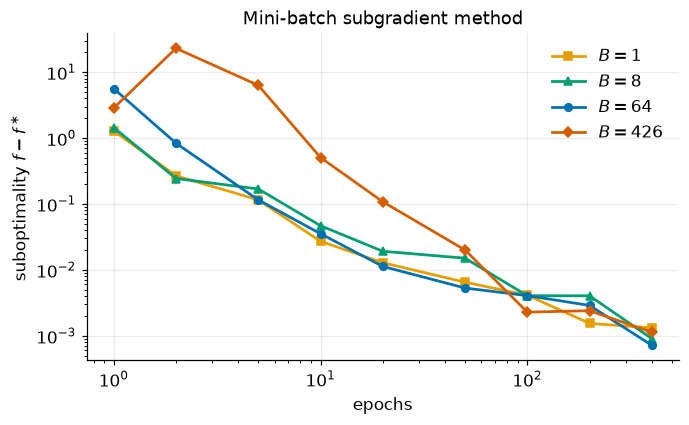

In [41]:
def solution_8_8():
    from sklearn.datasets import load_breast_cancer
    from sklearn.model_selection import train_test_split
    from sklearn.preprocessing import StandardScaler

    bc = load_breast_cancer(as_frame=True)
    X, y01 = bc.data.to_numpy(), (1 - bc.target).to_numpy()
    Xtr, _, ytr, _ = train_test_split(X, y01, test_size=0.25, random_state=SEED, stratify=y01)
    Z = StandardScaler().fit_transform(Xtr)
    s = 2.0 * ytr - 1
    n = len(s)
    A = np.c_[np.ones(n), Z]                                            # the intercept is inside w (and penalized)
    C = 1.0
    lam = 1 / (n * C)
    f = lambda w: 0.5 * lam * w @ w + np.mean(np.maximum(0, 1 - s * (A @ w)))

    # exact minimum by dual coordinate descent
    rng = np.random.default_rng(SEED)
    alpha, w = np.zeros(n), np.zeros(A.shape[1])
    q = np.einsum("ij,ij->i", A, A)
    for sweep in range(1, 5001):
        for i in rng.permutation(n):
            g = s[i] * (w @ A[i]) - 1
            new = min(max(alpha[i] - g / q[i], 0.0), C)
            w += (new - alpha[i]) * s[i] * A[i]
            alpha[i] = new
        if sweep % 10 == 0 and (0.5 * w @ w + C * np.maximum(0, 1 - s * (A @ w)).sum() - alpha.sum() + 0.5 * w @ w) / (n * C) < 1e-9:
            break
    f_star = f(w)

    total = 200_000                                                     # examples processed, the same for every batch size
    epochs_marks = [1, 2, 5, 10, 20, 50, 100, 200, 400]
    results = {}
    for B in [1, 8, 64, 426]:
        rng = np.random.default_rng(SEED)
        radius = np.sqrt(2 / lam)
        v = np.zeros(A.shape[1])
        steps = total // B
        marks = {int(round(e * n / B)): e for e in epochs_marks if round(e * n / B) >= 1 and round(e * n / B) <= steps}
        gaps = {}
        for k in range(1, steps + 1):
            idx = rng.choice(n, size=B, replace=False) if B < n else np.arange(n)
            viol = s[idx] * (A[idx] @ v) < 1
            g = lam * v - (s[idx][viol, None] * A[idx][viol]).sum(axis=0) / B
            v = v - g / (lam * k)
            nv = np.linalg.norm(v)
            if nv > radius:
                v *= radius / nv
            if k in marks:
                gaps[marks[k]] = f(v) - f_star
        results[B] = gaps
    table = pd.DataFrame(results).T
    table.index.name = "batch size B"
    print(f"f* = {f_star:.6f}; suboptimality of the last iterate after the given number of epochs")
    print(table.to_string(float_format=lambda v: f"{v:.2e}"))
    fig, ax = plt.subplots(figsize=(6.4, 4.0))
    for B, color, marker in zip(results, [ORANGE, GREEN, BLUE, VERMILION], ["s", "^", "o", "D"]):
        e = np.array(list(results[B])); g = np.array(list(results[B].values()))
        ax.loglog(e, g, color=color, marker=marker, lw=1.8, ms=5, label=f"$B = {B}$")
        if len(e) >= 4:
            sel = e >= 10
            print(f"B = {B}: slope of the last-iterate gap against the epochs (epochs >= 10): {np.polyfit(np.log(e[sel]), np.log(g[sel]), 1)[0]:.2f}")
    ax.set(xlabel="epochs", ylabel=r"suboptimality $f - f^\ast$", title="Mini-batch subgradient method")
    ax.legend(frameon=False)
    fig.tight_layout()
    plt.show()


solution_8_8()

At an equal number of epochs, the batch sizes $B = 1, 8, 64$ are not distinguishable within the noise of a single run: after $200$ epochs the suboptimality of the last iterate is between $1.5\cdot 10^{-3}$ and $4.0\cdot 10^{-3}$ for the three and between $7\cdot 10^{-4}$ and $1.3\cdot 10^{-3}$ after $400$ epochs. The slopes of the last-iterate gap against the epochs are $-0.84$, $-0.98$ and $-0.91$, close to the $-1$ of the $O(1/k)$ rate of Theorem 8.6. The contrast with Section 7.7.1 is instructive: there each batch size had its own tuned step size, and the best step grew with $B$, which made the larger batches more efficient per epoch. Here the step $1/(\lambda k)$ is *fixed by the strong convexity*, with no learning rate to tune, so a larger batch only reduces the variance of the gradient, which is not what limits the speed of this method on a problem of $426$ examples. The full batch ($B = 426$, which is the deterministic subgradient method) starts much worse (suboptimality $23$ after two epochs, because the first steps are huge: $1/(\lambda k)$ is $426$ at $k = 1$) but catches up: $2.3\cdot 10^{-3}$ after $100$ epochs. Its apparent slope of $-1.7$ is that recovery from a bad start, not an asymptotic rate.

  n  draws  SV fraction  SV fraction (sd)  LOO error  LOO error (sd)  test error  test error (sd)
 50     30       0.2540            0.0362     0.0453          0.0258      0.0459           0.0188
100     30       0.2043            0.0242     0.0367          0.0170      0.0289           0.0097
200     30       0.1537            0.0178     0.0282          0.0098      0.0254           0.0101
426      1       0.1197            0.0000     0.0258          0.0000      0.0210           0.0000 
(elapsed 19 s)


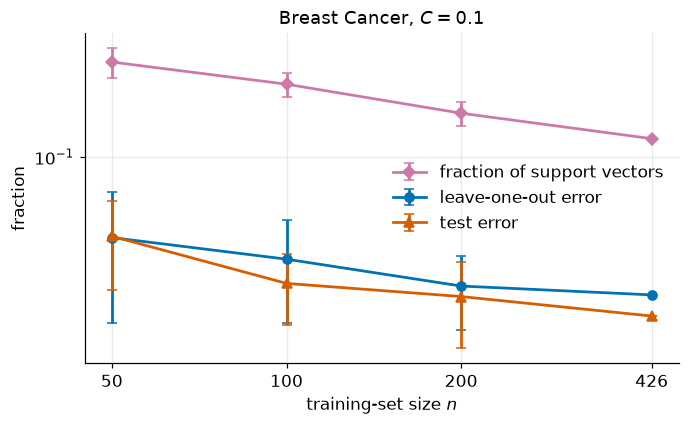

In [42]:
def solution_8_9():
    import time

    from sklearn.datasets import load_breast_cancer
    from sklearn.model_selection import LeaveOneOut, cross_val_predict, train_test_split
    from sklearn.pipeline import make_pipeline
    from sklearn.preprocessing import StandardScaler
    from sklearn.svm import SVC

    bc = load_breast_cancer(as_frame=True)
    X, y01 = bc.data.to_numpy(), (1 - bc.target).to_numpy()
    Xtr, Xte, ytr, yte = train_test_split(X, y01, test_size=0.25, random_state=SEED, stratify=y01)
    make = lambda: make_pipeline(StandardScaler(), SVC(kernel="linear", C=0.1, tol=1e-6))
    rows = []
    t0 = time.perf_counter()
    for n in [50, 100, 200, 426]:
        draws = 1 if n == len(ytr) else 30                              # n = 426 is the whole training set: a single draw
        out = []
        for d in range(draws):
            if n == len(ytr):
                Xs, ys = Xtr, ytr
            else:
                Xs, _, ys, _ = train_test_split(Xtr, ytr, train_size=n, stratify=ytr, random_state=SEED + d)
            model = make().fit(Xs, ys)
            loo = np.mean(cross_val_predict(make(), Xs, ys, cv=LeaveOneOut()) != ys)
            out.append((len(model[-1].support_) / n, loo, np.mean(model.predict(Xte) != yte)))
        out = np.array(out)
        rows.append({"n": n, "draws": draws, "SV fraction": out[:, 0].mean(), "SV fraction (sd)": out[:, 0].std(), "LOO error": out[:, 1].mean(),
                     "LOO error (sd)": out[:, 1].std(), "test error": out[:, 2].mean(), "test error (sd)": out[:, 2].std()})
    df = pd.DataFrame(rows)
    print(df.to_string(index=False, float_format=lambda v: f"{v:.4f}"), f"\n(elapsed {time.perf_counter() - t0:.0f} s)")
    fig, ax = plt.subplots(figsize=(6.4, 4.0))
    for col, color, marker, lab in [("SV fraction", PURPLE, "D", "fraction of support vectors"), ("LOO error", BLUE, "o", "leave-one-out error"), ("test error", VERMILION, "^", "test error")]:
        ax.errorbar(df["n"], df[col], yerr=df[col + " (sd)"], color=color, marker=marker, lw=1.8, capsize=3, label=lab)
    ax.set(xscale="log", yscale="log", xlabel="training-set size $n$", ylabel="fraction", title="Breast Cancer, $C = 0.1$")
    ax.set_xticks(df["n"]); ax.set_xticklabels(df["n"]); ax.minorticks_off()
    ax.legend(frameon=False)
    fig.tight_layout()
    plt.show()


solution_8_9()

The fraction of support vectors decreases with $n$: $25\%$, $20\%$, $15\%$ and $12\%$ for $n = 50, 100, 200, 426$ (a decrease by a factor of $2.1$ for a factor $8.5$ in $n$, roughly like $n^{-0.35}$). The leave-one-out error and the test error decrease too, from $4.5\%$ and $4.6\%$ at $n = 50$ to $2.6\%$ and $2.1\%$ at $n = 426$, and their standard deviations over the draws shrink from about $2\%$ to $1\%$. The leave-one-out error is, on average, a good (slightly pessimistic for $n\ge 100$) estimate of the test error, and both are far below the fraction of support vectors: the bound of Proposition 8.8 is correct in every case but is $4.6$ to $5.6$ times larger than the quantity it bounds. That a smaller training set has proportionally more support vectors is plausible, since the margin of a sparse sample is crossed by a larger fraction of its points, but we have not tested this explanation. The test error of the $n = 426$ row is that of the single model of Section 8.6 ($2.1\%$ at $C = 0.1$), and the corresponding standard deviations are zero because there is only one draw.

In [43]:
def solution_8_10():
    from scipy.stats import t as t_dist
    from sklearn.datasets import load_diabetes
    from sklearn.linear_model import Ridge
    from sklearn.model_selection import GridSearchCV, KFold, train_test_split
    from sklearn.pipeline import make_pipeline
    from sklearn.preprocessing import StandardScaler
    from sklearn.svm import SVR

    d = load_diabetes()
    J, n_test = 20, 111
    n_train = len(d.target) - n_test
    rows = []
    for j in range(J):
        Xtr, Xte, ytr, yte = train_test_split(d.data, d.target, test_size=n_test, random_state=1000 + j)
        kf = KFold(5, shuffle=True, random_state=SEED)
        svr = GridSearchCV(make_pipeline(StandardScaler(), SVR(kernel="linear", epsilon=50, tol=1e-4)), {"svr__C": np.logspace(-1, 2, 7)},
                           cv=kf, scoring="neg_root_mean_squared_error").fit(Xtr, ytr)
        ridge = GridSearchCV(make_pipeline(StandardScaler(), Ridge()), {"ridge__alpha": np.logspace(-2, 3, 11)}, cv=kf, scoring="neg_root_mean_squared_error").fit(Xtr, ytr)
        r = lambda m: np.sqrt(np.mean((m.predict(Xte) - yte) ** 2))
        rows.append({"SVR": r(svr), "ridge": r(ridge)})
    df = pd.DataFrame(rows)
    diff = (df["SVR"] - df["ridge"]).to_numpy()
    t_stat = diff.mean() / np.sqrt((1 / J + n_test / n_train) * diff.var(ddof=1))
    p = 2 * t_dist.sf(abs(t_stat), J - 1)
    print(f"test RMSE over {J} splits: SVR {df['SVR'].mean():.2f} (sd {df['SVR'].std():.2f}), ridge {df['ridge'].mean():.2f} (sd {df['ridge'].std():.2f})")
    print(f"paired difference SVR - ridge: mean {diff.mean():.3f}, sd {diff.std(ddof=1):.3f}; SVR better in {int((diff < 0).sum())} of {J} splits")
    print(f"corrected resampled t = {t_stat:.2f} with {J - 1} degrees of freedom, p = {p:.3f}; (naive t = {diff.mean() / np.sqrt(diff.var(ddof=1) / J):.2f})")


solution_8_10()

test RMSE over 20 splits: SVR 55.23 (sd 3.21), ridge 55.07 (sd 3.42)
paired difference SVR - ridge: mean 0.154, sd 0.637; SVR better in 8 of 20 splits
corrected resampled t = 0.39 with 19 degrees of freedom, p = 0.702; (naive t = 1.08)


Over $20$ random splits the test RMSE is $55.23$ ($\pm 3.21$ across splits) for SVR with $\varepsilon = 50$ and $55.07$ ($\pm 3.42$) for ridge. The paired difference has mean $0.15$ and standard deviation $0.64$, and SVR is better in $8$ of the $20$ splits. The naive paired $t$ statistic is $1.08$, and the corrected resampled statistic of Section 5.5.2, which accounts for the overlap between the training sets, is $0.39$ with $19$ degrees of freedom ($p = 0.70$): **the data do not allow us to conclude anything**, and the difference of $0.15$ is a small fraction of the variation across splits ($3.2$). As in Section 8.8.2, the $\varepsilon$-insensitive loss changes the *sparsity* of the solution but not its accuracy on this problem, and a comparison on a single split (the $53.0$ of the chapter against $53.3$ for ridge) would have been misleading in either direction.

## C.9 Chapter 9

### Manual exercises

**Solution 9.1 — Kernel or not?**

(a) $(xz)^2 = x^2\cdot z^2$ is the inner product of the one-dimensional features $\phi(x) = x^2$: a kernel. (b) $-(x - z)^2$ is not a kernel: for the points $0$ and $1$ the Gram matrix is $\begin{pmatrix}0&-1\\-1&0\end{pmatrix}$, with the eigenvalues $\pm1$; the negative one violates Theorem 9.1. (c) $\cos(x - z) = \cos x\cos z + \sin x\sin z$ is the inner product of $\boldsymbol\phi(x) = (\cos x, \sin x)$: a kernel. (d) $\max(x, z)$ is not a kernel: for the points $1$ and $2$ the Gram matrix is $\begin{pmatrix}1&2\\2&2\end{pmatrix}$, with determinant $2 - 4 = -2 < 0$, so one eigenvalue is negative. (e) $\min(x, z)$ is a kernel: $\min(x, z) = \int_0^\infty\mathbb{I}[t\le x]\mathbb{I}[t\le z]\,dt$ is the inner product in $L^2(0, \infty)$ of $\phi(x) = \mathbb{I}[\cdot\le x]$; equivalently $\sum_{i,j}c_ic_j\min(x_i, x_j) = \int_0^\infty\big(\sum_ic_i\mathbb{I}[t\le x_i]\big)^2dt\ge 0$.

**Solution 9.2 — The feature space of the polynomial kernel.**

(a) Expanding, $(\mathbf{x}^\top\mathbf{z} + c)^2 = \sum_ix_i^2z_i^2 + 2\sum_{i<j}x_ix_jz_iz_j + 2c\sum_ix_iz_i + c^2$, which is $\boldsymbol\phi(\mathbf{x})^\top\boldsymbol\phi(\mathbf{z})$ for $\boldsymbol\phi(\mathbf{x}) = \big(x_i^2\ (d),\ \sqrt2\,x_ix_j\ (i < j;\ \tfrac{d(d - 1)}2),\ \sqrt{2c}\,x_i\ (d),\ c\big)$, with $d + \frac{d(d - 1)}2 + d + 1 = \frac{(d + 1)(d + 2)}2$ coordinates. (b) A monomial of degree at most $p$ in $d$ variables is a vector of exponents $(e_1, \dots, e_d)$ with $\sum_le_l\le p$; adding the slack $e_0 = p - \sum_le_l\ge 0$ puts these in one-to-one correspondence with the non-negative integer solutions of $e_0 + e_1 + \dots + e_d = p$, of which there are $\binom{p + d}{d} = \binom{d + p}{p}$ (stars and bars). For $d = 30$: $\binom{32}{2} = 496$, $\binom{33}{3} = 5{,}456$ and $\binom{35}{5} = 324{,}632$ for $p = 2, 3, 5$. (c) $\lVert\boldsymbol\phi(\mathbf{x}) - \boldsymbol\phi(\mathbf{z})\rVert^2 = k(\mathbf{x}, \mathbf{x}) + k(\mathbf{z}, \mathbf{z}) - 2k(\mathbf{x}, \mathbf{z})$. With $c = 1$, $\mathbf{x} = (1, 0)$ and $\mathbf{z} = (1, 1)$: $k(\mathbf{x}, \mathbf{x}) = (1 + 1)^2 = 4$, $k(\mathbf{z}, \mathbf{z}) = (2 + 1)^2 = 9$ and $k(\mathbf{x}, \mathbf{z}) = (1 + 1)^2 = 4$, so the squared distance is $4 + 9 - 8 = 5$ and the cosine of the angle is $k(\mathbf{x}, \mathbf{z})/\sqrt{k(\mathbf{x}, \mathbf{x})k(\mathbf{z}, \mathbf{z})} = 4/6 = \tfrac23$.

**Solution 9.3 — Kernel ridge regression by hand, and the leave-one-out shortcut.**

(a) $\mathbf{K} + \mathbf{I} = \begin{pmatrix}2&1&1\\1&3&2\\1&2&4\end{pmatrix}$ and $\hat{\boldsymbol\alpha} = (\mathbf{K} + \mathbf{I})^{-1}\mathbf{y} = \frac1{13}(8\cdot 3 - 2\cdot 3 - 5,\ -2\cdot 3 + 7\cdot 3 - 3\cdot 5,\ -3 - 9 + 25) = \frac1{13}(13, 0, 13) = (1, 0, 1)$. Check: $(\mathbf{K} + \mathbf{I})(1, 0, 1)^\top = (3, 3, 5)^\top = \mathbf{y}$. So $\hat f(x) = \min(1, x) + \min(3, x)$, with fitted values $\mathbf{K}\hat{\boldsymbol\alpha} = (2, 3, 4)$ and residuals $(1, 0, 1) = \lambda\hat{\boldsymbol\alpha}$. (b) $\lVert\hat f\rVert^2_{\mathcal{H}} = \hat{\boldsymbol\alpha}^\top\mathbf{K}\hat{\boldsymbol\alpha} = K_{11} + 2K_{13} + K_{33} = 1 + 2 + 3 = 6$. (c) $\mathbf{H}_\lambda = \mathbf{K}(\mathbf{K} + \mathbf{I})^{-1} = \mathbf{I} - (\mathbf{K} + \mathbf{I})^{-1}$, so $(\mathbf{H}_\lambda)_{ii} = 1 - \frac{8}{13}, 1 - \frac7{13}, 1 - \frac5{13} = \frac5{13}, \frac6{13}, \frac8{13}$ and the leave-one-out errors $e_i/(1 - H_{ii})$ are $\frac{1}{8/13} = \frac{13}8 = 1.625$, $\frac0{7/13} = 0$ and $\frac1{5/13} = \frac{13}5 = 2.6$ (the leave-one-out mean squared error is $3.13$). *Check for the first point:* without $x = 1$ the data are $x = 2, 3$ with $y = 3, 5$, the Gram matrix is $\begin{pmatrix}2&2\\2&3\end{pmatrix}$, $\mathbf{K}' + \mathbf{I} = \begin{pmatrix}3&2\\2&4\end{pmatrix}$ with the inverse $\frac18\begin{pmatrix}4&-2\\-2&3\end{pmatrix}$, so $\boldsymbol\alpha' = \frac18(12 - 10,\ -6 + 15) = (\tfrac14, \tfrac98)$ and the prediction at $x = 1$ is $\tfrac14\min(2, 1) + \tfrac98\min(3, 1) = \tfrac{11}8 = 1.375$: the error is $3 - 1.375 = 1.625 = \tfrac{13}8$, as given by the formula.

**Solution 9.4 — The two ends of the bandwidth.**

(a) By Gershgorin's theorem every eigenvalue of $\mathbf{K}$ lies in a disc centered at a diagonal entry $K_{ii} = 1$ with radius $\sum_{j\ne i}K_{ij}\le(n - 1)e^{-\gamma d_{\min}^2}$, so $\lambda_{\min}\ge 1 - (n - 1)e^{-\gamma d_{\min}^2}$, which is positive as soon as $e^{-\gamma d_{\min}^2} < 1/(n - 1)$, that is $\gamma > \ln(n - 1)/d_{\min}^2$. (b) For $\gamma\to\infty$ every off-diagonal entry tends to $0$ and $\mathbf{K}\to\mathbf{I}$, so $\hat{\boldsymbol\alpha}\to(\mathbf{I} + \lambda\mathbf{I})^{-1}\mathbf{y} = \mathbf{y}/(1 + \lambda)$ and the fitted values $\mathbf{K}\hat{\boldsymbol\alpha}\to\mathbf{y}/(1 + \lambda)$. At a point $\mathbf{x}$ outside the sample $k(\mathbf{x}_i, \mathbf{x}) = e^{-\gamma\lVert\mathbf{x}_i - \mathbf{x}\rVert^2}\to 0$ for every $i$, so $\hat f(\mathbf{x}) = \sum_i\hat\alpha_ik(\mathbf{x}_i, \mathbf{x})\to 0$: after adding back the mean, the prediction is the mean of the training responses. The model has memorized the training set (it even reproduces it up to the factor $1/(1 + \lambda)$) and knows nothing about any other point. (c) The SVM behaves in the same way: for $\gamma\ge 1$ on Breast Cancer the Gram matrix has its eigenvalues between $0.64$ and $1.76$ (Section 9.3.3), every patient is its own support vector ($426$ of $426$), and for a new patient all the kernel values are near $0$, so that the score is the intercept $\hat b$, whose sign is that of the majority class: every test patient is classified benign.

**Solution 9.5 — Random Fourier features.**

(a) $T = 2\cos^2(wx + b) = 1 + \cos(2wx + 2b)$. For any fixed $w$, $2wx + 2b$ modulo $2\pi$ is uniform on $[0, 2\pi]$ when $b$ is, so $\cos(2wx + 2b)$ has the mean $0$ and the variance $\mathbb{E}\cos^2\theta = \tfrac12$ for $\theta$ uniform. Hence $\mathbb{E}\,T = 1 = k(x, x)$ and $\operatorname{Var}\,T = \tfrac12$. (b) The average of $D$ independent copies has the variance $\frac1{2D}$; a standard deviation of $0.01$ needs $\frac1{2D} = 10^{-4}$, that is $D = 5{,}000$. (c) Chebyshev: $\mathbb{P}(\lvert\bar T - 1\rvert\ge 0.1)\le\frac{1/(2D)}{0.01} = \frac{50}{D}\le 0.05$ for $D\ge 1{,}000$. Hoeffding (Theorem 9.7 (ii), for a single pair): $2e^{-D\cdot 0.01/8}\le 0.05$ for $D\ge 800\ln 40 = 2{,}951$. Hoeffding needs three times more features here, because it uses only the range of $T$ ($[-2, 2]$) and not its variance ($\tfrac12$); in exchange it extends, with a union bound, to all the pairs of a sample with an exponentially small failure probability, which Chebyshev's polynomial tail does not.

### Python exercises

In [44]:
def solution_9_6():
    from sklearn.datasets import load_breast_cancer
    from sklearn.metrics.pairwise import laplacian_kernel, linear_kernel, polynomial_kernel, rbf_kernel, sigmoid_kernel
    from sklearn.model_selection import train_test_split
    from sklearn.preprocessing import StandardScaler

    bc = load_breast_cancer()
    Xtr, _, _, _ = train_test_split(bc.data, bc.target, test_size=0.25, random_state=SEED, stratify=bc.target)
    Z = StandardScaler().fit_transform(Xtr)[:200]
    raw = Xtr[:200] / Xtr.max(axis=0)                                    # non-negative features in [0, 1]

    def rel_min_eig(K):
        ev = np.linalg.eigvalsh((K + K.T) / 2)
        return ev.min() / ev.max(), int(np.sum(ev < -1e-10 * ev.max()))

    cos = (Z @ Z.T) / np.outer(np.linalg.norm(Z, axis=1), np.linalg.norm(Z, axis=1))
    hist = np.array([[np.minimum(a, b).sum() for b in raw] for a in raw])
    cands = {"linear": linear_kernel(Z), "polynomial (x.z + 1)^2": polynomial_kernel(Z, degree=2, gamma=1, coef0=1),
             "Gaussian (gamma = 0.01)": rbf_kernel(Z, gamma=0.01), "Laplacian (gamma = 0.01)": laplacian_kernel(Z, gamma=0.01),
             "cosine similarity": cos, "histogram intersection (raw / max)": hist,
             "tanh(0.01 x.z - 1)": sigmoid_kernel(Z, gamma=0.01, coef0=-1), "tanh(0.01 x.z)": sigmoid_kernel(Z, gamma=0.01, coef0=0),
             "tanh(0.01 x.z + 1)": sigmoid_kernel(Z, gamma=0.01, coef0=1)}
    rows = []
    for name, K in cands.items():
        r, neg = rel_min_eig(K)
        rows.append({"function": name, "smallest / largest eigenvalue": r, "negative eigenvalues": neg, "kernel?": "yes" if neg == 0 else "NO"})
    print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.2e}"))


solution_9_6()

                          function  smallest / largest eigenvalue  negative eigenvalues kernel?
                            linear                      -2.80e-16                     0     yes
            polynomial (x.z + 1)^2                       5.88e-07                     0     yes
           Gaussian (gamma = 0.01)                       8.79e-07                     0     yes
          Laplacian (gamma = 0.01)                       1.25e-04                     0     yes
                 cosine similarity                      -2.33e-16                     0     yes
histogram intersection (raw / max)                       4.71e-05                     0     yes
                tanh(0.01 x.z - 1)                      -1.08e+01                    13      NO
                    tanh(0.01 x.z)                      -3.24e-02                   161      NO
                tanh(0.01 x.z + 1)                      -7.72e-03                   110      NO


The linear, polynomial, Gaussian and Laplacian kernels, the cosine similarity and the histogram intersection are positive semidefinite: the smallest eigenvalue relative to the largest is at the level of rounding errors ($\lvert\cdot\rvert\le 2\cdot 10^{-16}$) or positive, with no negative eigenvalue beyond the tolerance. The three sigmoid functions are not kernels: $\tanh(0.01\,\mathbf{x}^\top\mathbf{z} - 1)$ has $13$ negative eigenvalues among $200$ (the smallest is $-10.8$ times the largest, an enormous violation), $\tanh(0.01\,\mathbf{x}^\top\mathbf{z})$ has $161$ and $\tanh(0.01\,\mathbf{x}^\top\mathbf{z} + 1)$ has $110$ (with relative smallest eigenvalues of only $-3\cdot 10^{-2}$ and $-8\cdot 10^{-3}$). The size of the violation is not the point: a single negative eigenvalue is enough to refute a kernel, and the sigmoid becomes "nearly" positive semidefinite only when its scale makes it nearly linear.

In [45]:
def solution_9_7():
    from sklearn.datasets import load_diabetes
    from sklearn.kernel_ridge import KernelRidge
    from sklearn.metrics.pairwise import laplacian_kernel, rbf_kernel
    from sklearn.model_selection import train_test_split
    from sklearn.preprocessing import StandardScaler

    d = load_diabetes()
    Xtr, Xte, ytr, yte = train_test_split(d.data, d.target, test_size=0.25, random_state=SEED)
    sc = StandardScaler().fit(Xtr)
    Z, Zt = sc.transform(Xtr), sc.transform(Xte)
    ym = ytr.mean()
    yc = ytr - ym

    def loo_grid(K, yc, lams):
        mu, U = np.linalg.eigh(K)
        uy = U.T @ yc
        out = []
        for lam in lams:
            sh = mu / (mu + lam)
            resid = yc - U @ (sh * uy)
            h = (U**2) @ sh
            out.append(np.sqrt(np.mean((resid / (1 - h)) ** 2)))
        return np.array(out)

    lams = 10.0 ** np.arange(-3, 4, 0.5)
    rows = []
    for kname, kern, gammas in [("Gaussian", rbf_kernel, [0.001, 0.003, 0.01, 0.03, 0.1]), ("Laplacian", laplacian_kernel, [0.0003, 0.001, 0.003, 0.01, 0.03])]:
        for g in gammas:
            K = kern(Z, gamma=g)
            loo = loo_grid(K, yc, lams)
            j = int(np.argmin(loo))
            mu = np.linalg.eigvalsh(K)
            alpha = np.linalg.solve(K + lams[j] * np.eye(len(yc)), yc)
            pred = kern(Zt, Z, gamma=g) @ alpha + ym
            skl = KernelRidge(alpha=lams[j], kernel="precomputed").fit(K, yc).predict(kern(Zt, Z, gamma=g)) + ym
            rows.append({"kernel": kname, "gamma": g, "lambda": lams[j], "LOO RMSE": loo[j], "df": np.sum(mu / (mu + lams[j])),
                         "test RMSE": np.sqrt(np.mean((pred - yte) ** 2)), "max |ours - sklearn|": np.abs(pred - skl).max()})
    df = pd.DataFrame(rows)
    print(df.to_string(index=False, float_format=lambda v: f"{v:.4g}"))
    for kname in ["Gaussian", "Laplacian"]:
        b = df[df["kernel"] == kname].sort_values("LOO RMSE").iloc[0]
        print(f"best {kname}: gamma = {b['gamma']:g}, lambda = {b['lambda']:.3g}, LOO RMSE {b['LOO RMSE']:.2f}, df {b['df']:.1f}, test RMSE {b['test RMSE']:.2f}")


solution_9_7()

   kernel  gamma  lambda  LOO RMSE    df  test RMSE  max |ours - sklearn|
 Gaussian  0.001    0.01     55.56 14.47      52.37             1.837e-10
 Gaussian  0.003     0.1     55.52 13.28      52.31             7.958e-12
 Gaussian   0.01  0.3162     55.51 18.72      51.66             3.979e-12
 Gaussian   0.03       1     55.82 25.86      51.13              7.39e-13
 Gaussian    0.1   3.162     57.81 35.05      51.58             1.137e-13
Laplacian 0.0003    0.01     55.88 33.19      51.45             1.492e-10
Laplacian  0.001 0.03162     55.88  34.3      51.44             4.366e-11
Laplacian  0.003     0.1      55.9  33.7      51.39              8.64e-12
Laplacian   0.01  0.3162     55.94 35.89      51.26             2.785e-12
Laplacian   0.03       1     56.14 36.86      51.08               5.4e-13
best Gaussian: gamma = 0.01, lambda = 0.316, LOO RMSE 55.51, df 18.7, test RMSE 51.66
best Laplacian: gamma = 0.001, lambda = 0.0316, LOO RMSE 55.88, df 34.3, test RMSE 51.44


Our kernel ridge regression agrees with `KernelRidge` of scikit-learn to $10^{-10}$ in all cases. The best Gaussian model by the leave-one-out error has $\gamma = 0.01$, $\lambda = 0.32$, a leave-one-out RMSE of $55.51$, $18.7$ degrees of freedom and a test RMSE of $51.66$; the best Laplacian model has $\gamma = 0.001$, $\lambda = 0.032$, a leave-one-out RMSE of $55.88$ (slightly worse), $34.3$ degrees of freedom and a test RMSE of $51.44$ (slightly better). The two differences, $0.4$ in one direction and $0.2$ in the other, are far below what $331$ or $111$ patients resolve: the two kernels are indistinguishable on this problem. They do differ in flexibility: the Laplacian kernel produces rougher functions, and needs about $34$ effective parameters to reach the same leave-one-out error that the Gaussian reaches with $19$, and ridge regression with $10$ (Section 9.5.2).

133 training wines, 45 test wines; standard deviations of the features: from 0.118 (nonflavanoid_phenols) to 304 (proline)


              features    C  gamma  5-fold accuracy  test accuracy  support vectors  cells with accuracy >= 0.9
                   raw 1000  1e-05           0.8803         0.9556               49                           0
          standardized    1   0.01           0.9926              1               73                          15
divided by the maximum    1     10           0.9852         0.9778               97                          19


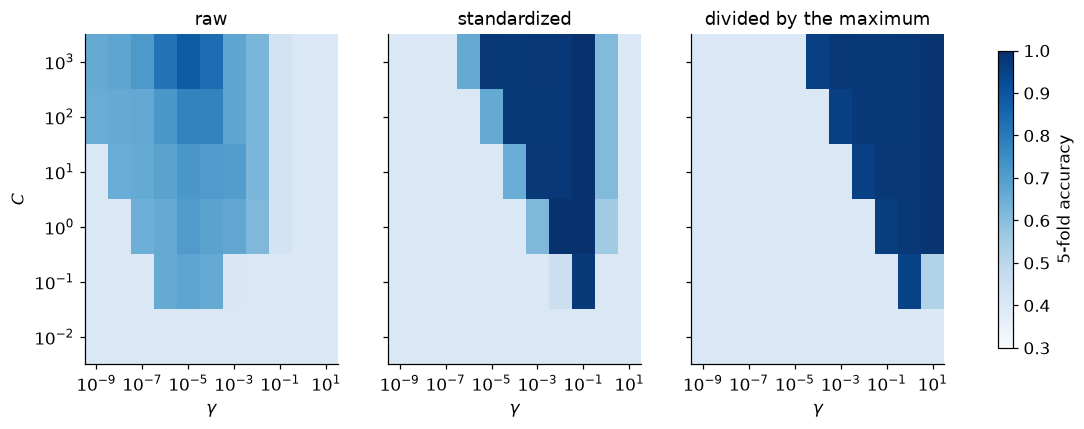

In [46]:
def solution_9_8():
    from sklearn.datasets import load_wine
    from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
    from sklearn.preprocessing import StandardScaler
    from sklearn.svm import SVC

    wine = load_wine()
    Xtr, Xte, ytr, yte = train_test_split(wine.data, wine.target, test_size=0.25, random_state=SEED, stratify=wine.target)
    sd = pd.Series(Xtr.std(axis=0), index=wine.feature_names)
    print(f"{len(ytr)} training wines, {len(yte)} test wines; standard deviations of the features: from {sd.min():.3g} ({sd.idxmin()}) to {sd.max():.3g} ({sd.idxmax()})")
    std = StandardScaler().fit(Xtr)
    versions = {"raw": (Xtr, Xte), "standardized": (std.transform(Xtr), std.transform(Xte)), "divided by the maximum": (Xtr / Xtr.max(axis=0), Xte / Xtr.max(axis=0))}
    C_grid, g_grid = 10.0 ** np.arange(-2, 4), 10.0 ** np.arange(-9, 1.01, 1)
    skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
    maps, rows = {}, []
    for name, (A, At) in versions.items():
        gs = GridSearchCV(SVC(kernel="rbf", tol=1e-4), {"C": C_grid, "gamma": g_grid}, cv=skf, scoring="accuracy").fit(A, ytr)
        maps[name] = gs.cv_results_["mean_test_score"].reshape(len(C_grid), len(g_grid))
        rows.append({"features": name, "C": gs.best_params_["C"], "gamma": gs.best_params_["gamma"], "5-fold accuracy": gs.best_score_, "test accuracy": gs.score(At, yte),
                     "support vectors": len(gs.best_estimator_.support_), "cells with accuracy >= 0.9": int((maps[name] >= 0.9).sum())})
    print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.4g}"))
    fig, axes = plt.subplots(1, 3, figsize=(12.6, 3.9), sharey=True)
    for ax, (name, m) in zip(axes, maps.items()):
        im = ax.imshow(m, origin="lower", cmap="Blues", vmin=0.3, vmax=1.0, aspect="auto")
        ax.set_xticks(range(0, len(g_grid), 2)); ax.set_xticklabels([f"$10^{{{int(np.log10(g_grid[i]))}}}$" for i in range(0, len(g_grid), 2)])
        ax.set_yticks(range(len(C_grid))); ax.set_yticklabels([f"$10^{{{int(np.log10(c))}}}$" for c in C_grid])
        ax.set(xlabel=r"$\gamma$", title=name); ax.grid(False)
    axes[0].set_ylabel("$C$")
    fig.colorbar(im, ax=axes, label="5-fold accuracy", shrink=0.9)
    plt.show()


solution_9_8()

The standard deviations of the $13$ features range from $0.12$ (`nonflavanoid_phenols`) to $304$ (`proline`), and the next one, magnesium, is around $14$: in raw units the squared distance between two wines is dominated by the proline and, much less, by the magnesium, and the Gaussian kernel is essentially a kernel on these two features. The consequence is visible in the first map of the figure: the best $5$-fold accuracy on the raw features is only $0.880$ (for $C = 1000$ and $\gamma = 10^{-5}$), and *no* cell of the grid reaches $0.9$ (the test accuracy of that pair, $0.956$, is better than its cross-validation accuracy, which with $45$ test wines is a matter of luck). With the standardized features the best $5$-fold accuracy is $0.993$ ($C = 1$, $\gamma = 0.01$), $15$ cells of the grid reach $0.9$, and the test accuracy is $1.000$ ($73$ support vectors); with the features divided by their maximum it is $0.985$ ($C = 1$, $\gamma = 10$, a larger $\gamma$ because the features are in $[0, 1]$), $19$ cells reach $0.9$, and the test accuracy is $0.978$. The two sensible scalings shift the good region along the $\gamma$ axis by three orders of magnitude, which is why $\gamma$ cannot be chosen without looking at the scale, and the raw features make the problem hard for a reason that has nothing to do with the data: the kernel is sensitive to units.

In [47]:
def solution_9_9():
    from sklearn.datasets import load_digits
    from sklearn.kernel_approximation import Nystroem, RBFSampler
    from sklearn.metrics.pairwise import rbf_kernel
    from sklearn.model_selection import train_test_split
    from sklearn.svm import SVC, LinearSVC

    dg = load_digits()
    Xtr, Xte, ytr, yte = train_test_split(dg.data, dg.target, test_size=0.25, random_state=SEED, stratify=dg.target)
    A, At = Xtr / 16, Xte / 16
    sub = np.arange(300)
    sizes = [25, 50, 100, 200, 400, 800]
    rows = []
    for g in [0.03, 0.1, 0.316]:
        exact = SVC(kernel="rbf", gamma=g, C=10, tol=1e-4).fit(A, ytr).score(At, yte)
        K_sub = rbf_kernel(A[sub], gamma=g)
        for m in sizes:
            for method in ["Nystroem", "random Fourier features"]:
                feat = (Nystroem(gamma=g, n_components=m, random_state=SEED) if method == "Nystroem" else RBFSampler(gamma=g, n_components=m, random_state=SEED)).fit(A)
                F = feat.transform(A[sub])
                lin = LinearSVC(C=10, max_iter=20_000).fit(feat.transform(A), ytr)
                rows.append({"gamma": g, "method": method, "components": m, "mean |error| of K": np.abs(F @ F.T - K_sub).mean(),
                             "test accuracy": lin.score(feat.transform(At), yte), "exact SVM": exact})
    df = pd.DataFrame(rows)
    print(df.pivot_table(index=["gamma", "components"], columns="method", values=["mean |error| of K", "test accuracy"]).to_string(float_format=lambda v: f"{v:.4f}"))
    for g in [0.03, 0.1, 0.316]:
        for method in ["Nystroem", "random Fourier features"]:
            d = df[(df["gamma"] == g) & (df["method"] == method)]
            ok = d[d["test accuracy"] >= d["exact SVM"] - 0.005]
            print(f"gamma = {g}: {method}: smallest number of components within 0.5% of the exact accuracy {d['exact SVM'].iloc[0]:.4f}: "
                  f"{int(ok['components'].min()) if len(ok) else 'none up to 800'}")


solution_9_9()

                 mean |error| of K                         test accuracy                        
method                    Nystroem random Fourier features      Nystroem random Fourier features
gamma components                                                                                
0.030 25                    0.0098                  0.1208        0.9489                  0.9111
      50                    0.0041                  0.0676        0.9733                  0.9489
      100                   0.0013                  0.0492        0.9822                  0.9689
      200                   0.0004                  0.0463        0.9867                  0.9822
      400                   0.0001                  0.0253        0.9844                  0.9867
      800                   0.0000                  0.0164        0.9844                  0.9822
0.100 25                    0.0263                  0.1491        0.9533                  0.8844
      50                    0.

For $\gamma = 0.03$ and $0.1$ the Nyström features reach the accuracy of the exact SVM ($0.991$) within $0.5\%$ with $200$ and $400$ landmarks, and the Fourier features with $400$ and $200$ components: the two are comparable at these bandwidths, and the single-seed comparison is too noisy to say more (the accuracy is not monotone in the number of components, because each size draws different random features). For $\gamma = 0.316$ the difference is large: the Nyström features need $100$ components and the Fourier features $800$. A larger $\gamma$ means a more slowly decaying spectrum of the Gram matrix (Figure 9.1(b)), and a Gram matrix that is close to the identity, which random Fourier features reproduce only with a large number of components, with an error that decreases like $D^{-1/2}$ whatever the spectrum; with very few components the Nyström features are already far ahead ($m = 25$ gives $0.920$ against $0.660$ for the Fourier features at $\gamma = 0.316$). The mean absolute error of the Gram matrix is a poor guide to the accuracy: for $\gamma = 0.03$ the Nyström error is more than an order of magnitude smaller than the Fourier one at the same number of components ($0.0013$ against $0.049$ at $100$), while the accuracies differ by $0.04$ at most, and by less than $0.005$ from $200$ components on.

In [48]:
def solution_9_10():
    from scipy.stats import binomtest
    from sklearn.datasets import load_digits
    from sklearn.metrics.pairwise import chi2_kernel, linear_kernel, rbf_kernel
    from sklearn.model_selection import StratifiedKFold, train_test_split
    from sklearn.svm import SVC

    dg = load_digits()
    Xtr, Xte, ytr, yte = train_test_split(dg.data, dg.target, test_size=0.25, random_state=SEED, stratify=dg.target)
    A, At = Xtr / 16, Xte / 16
    skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
    builders = {"Gaussian": lambda X, Y, g: rbf_kernel(X, Y, gamma=g),
                "chi-square": lambda X, Y, g: chi2_kernel(X, Y, gamma=g),
                "Gaussian + linear": lambda X, Y, g: rbf_kernel(X, Y, gamma=g) + linear_kernel(X, Y)}
    gammas = {"Gaussian": [0.03, 0.1, 0.316, 1.0], "chi-square": [0.03, 0.1, 0.3, 1.0], "Gaussian + linear": [0.03, 0.1, 0.316, 1.0]}
    rows, preds = [], {}
    for name, build in builders.items():
        best = None
        for g in gammas[name]:
            K = build(A, A, g)
            for C in [1, 10, 100]:
                accs = []
                for tr, va in skf.split(A, ytr):
                    m = SVC(kernel="precomputed", C=C, tol=1e-4).fit(K[np.ix_(tr, tr)], ytr[tr])
                    accs.append(m.score(K[np.ix_(va, tr)], ytr[va]))
                if best is None or np.mean(accs) > best[0]:
                    best = (np.mean(accs), g, C)
        acc_cv, g, C = best
        K = build(A, A, g)
        final = SVC(kernel="precomputed", C=C, tol=1e-6).fit(K, ytr)
        preds[name] = final.predict(build(At, A, g))
        rows.append({"kernel": name, "gamma": g, "C": C, "5-fold accuracy": acc_cv, "test accuracy": np.mean(preds[name] == yte), "test errors": int(np.sum(preds[name] != yte)),
                     "smallest eigenvalue of the Gram matrix": np.linalg.eigvalsh(K).min()})
    print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.4g}"))
    for other in ["chi-square", "Gaussian + linear"]:
        a, b = preds[other] == yte, preds["Gaussian"] == yte
        only_a, only_b = int(np.sum(a & ~b)), int(np.sum(~a & b))
        p = binomtest(min(only_a, only_b), only_a + only_b, 0.5).pvalue if only_a + only_b else 1.0
        print(f"McNemar, {other} against Gaussian: {only_a} against {only_b} discordant images, p = {p:.3f}")


solution_9_10()

           kernel  gamma  C  5-fold accuracy  test accuracy  test errors  smallest eigenvalue of the Gram matrix
         Gaussian  0.316 10           0.9911         0.9889            5                                 0.01233
       chi-square    0.3  1           0.9889         0.9867            6                                 0.04421
Gaussian + linear  0.316  1           0.9837         0.9889            5                                  0.0125
McNemar, chi-square against Gaussian: 0 against 1 discordant images, p = 1.000
McNemar, Gaussian + linear against Gaussian: 2 against 2 discordant images, p = 1.000


The three kernels have positive definite Gram matrices (the smallest eigenvalues are $0.012$, $0.044$ and $0.013$) and give practically the same results: test accuracies of $0.989$ ($5$ errors in $450$ images) for the Gaussian kernel and for the Gaussian plus linear kernel, and $0.987$ ($6$ errors) for the $\chi^2$ kernel, with $5$-fold accuracies of $0.991$, $0.984$ and $0.989$. McNemar's test finds no difference: $0$ against $1$ discordant images for the $\chi^2$ kernel and $2$ against $2$ for the sum ($p = 1$ in both cases). There is no advantage in the kernel designed for non-negative histograms on this data set: the $\chi^2$ kernel is a natural choice for histograms of counts, and the pixel intensities of an $8\times 8$ image are not that; the lesson is that *a kernel is a statement about similarity*, and that the choice among reasonable kernels matters much less than the scale of the features (Section 9.6.4) or the choice of $(C, \gamma)$.

## C.10 Chapter 10

### Manual exercises

**Solution 10.1 — Four estimators by hand.**

(a) The lasso with $\lambda=1$ soft-thresholds each coordinate (Proposition 10.6): $S_1(4)=3$, $S_1(-2.5)=-1.5$, $S_1(1.2)=0.2$, and the last two are set to zero, so $\hat{\mathbf{w}}=(3, -1.5, 0.2, 0, 0)$. (b) Ridge divides by $1+\lambda_2=2$: $(2, -1.25, 0.6, -0.3, 0.1)$. (c) Best subset of size 2 keeps the two largest coordinates in absolute value and does not shrink them: $(4, -2.5, 0, 0, 0)$. (d) By Exercise 10.4 the elastic net is $S_{\lambda_1}(\hat w_j^{\rm ols})/(1+\lambda_2)$, that is the weights of (a) halved: $(1.5, -0.75, 0.1, 0, 0)$. (e) The lasso keeps the coordinate $j$ if and only if $\lvert\hat w^{\rm ols}_j\rvert>\lambda$, so it keeps exactly two when $1.2\le\lambda<2.5$ (at $\lambda=1.2$ the third coordinate is exactly zero). The two weights are then $4-\lambda$ and $-(2.5-\lambda)$: each is smaller in absolute value than the corresponding weight of (c) by exactly $\lambda$, between $1.2$ and $2.5$, which for the second coordinate is between $48\%$ and $100\%$ of its size. This is the shrinkage bias of Section 10.5.6, and it is why one refits on the selected support.

**Solution 10.2 — A two-feature lasso path.**

(a) $\lambda_{\max}=\max_j\lvert c_j\rvert=0.8$, and feature 1 is the first to enter (Theorem 10.7 at $\mathbf{w}=\mathbf{0}$). (b) With only feature 1 active, $\hat w_1=c_1-\lambda=0.8-\lambda$. Feature 2 enters when the absolute value of its correlation with the residual reaches $\lambda$: $c_2-\rho\hat w_1=0.6-0.5(0.8-\lambda)=0.2+0.5\lambda=\lambda$, so $\lambda=0.4$. Below $0.4$ both are active with positive signs, and $\begin{pmatrix}1&\rho\\\rho&1\end{pmatrix}\hat{\mathbf{w}}=\mathbf{c}-\lambda\mathbf{1}$ gives
$$
\hat w_1=\frac{(0.8-\lambda)-0.5(0.6-\lambda)}{0.75}=\tfrac23-\tfrac23\lambda,\qquad\hat w_2=\frac{(0.6-\lambda)-0.5(0.8-\lambda)}{0.75}=\tfrac4{15}-\tfrac23\lambda,
$$
which are continuous at $\lambda=0.4$ ($\hat w_1=0.4$, $\hat w_2=0$) and equal $(\frac23,\frac4{15})$ at $\lambda=0$, the least-squares solution of $\begin{pmatrix}1&0.5\\0.5&1\end{pmatrix}\mathbf{w}=(0.8,0.6)^\top$. (c) With $c_2=0.3$ the correlation of feature 2 with the residual is $0.3-0.5(0.8-\lambda)=-0.1+0.5\lambda$, which is *negative* below $\lambda=0.2$ and reaches $-\lambda$ at $\lambda=0.1/1.5=\frac1{15}\approx0.067$ (the positive branch, $-0.1+0.5\lambda=\lambda$, would need $\lambda<0$). So feature 2 enters late, with a **negative** sign, although its marginal correlation with $\mathbf{y}$ is positive. For $\lambda<\frac1{15}$, $\hat w_1=(0.65-1.5\lambda)/0.75$ and $\hat w_2=(-0.1+1.5\lambda)/0.75$; at $\lambda=0$ they are $(0.867,-0.133)$, the least-squares solution. The mechanism is the one of `s3` in Figure 10.5: once the correlated feature 1 has explained what it can, what is left of feature 2 is related to the residual with the opposite sign, and the sign of a weight in a joint model need not be the sign of the marginal correlation.

**Solution 10.3 — Repeated columns.**

(a) If $\mathbf{z}_j=\mathbf{z}_k$ then $\mathbf{Z}\mathbf{w}=\sum_{l\ne j,k}w_l\mathbf{z}_l+(w_j+w_k)\mathbf{z}_j$, so the data term depends on $w_j,w_k$ only through $s=w_j+w_k$. (b) Let $\hat{\mathbf{w}}$ be a lasso solution with $\hat w_j\hat w_k\ge0$ and $s=\hat w_j+\hat w_k$. Replace $(\hat w_j,\hat w_k)$ by any $(w_j',w_k')$ with the same sign as $s$ and $w_j'+w_k'=s$. The data term is unchanged by (a), and $\lvert w_j'\rvert+\lvert w_k'\rvert=\lvert s\rvert=\lvert\hat w_j\rvert+\lvert\hat w_k\rvert$ because the two have the same sign, so the objective is unchanged: the new vector is also a solution, and the set of solutions contains a whole segment (for $s\ne0$). The lasso does not say how to split the weight, and a solver returns one point of the segment, which is what we saw for `bmi` and its copy in Section 10.8. (c) With $\lambda_2>0$ the objective is strictly convex, so the solution is unique, and for a fixed sum $s$ the data term and the $\ell_1$ term are constant on the segment of (b) while $\frac{\lambda_2}2(w_j^2+w_k^2)\ge\frac{\lambda_2}{4}s^2$ with equality only at $w_j=w_k=s/2$ (by $w_j^2+w_k^2=\frac{s^2}2+\frac{(w_j-w_k)^2}2$). Opposite signs cannot be optimal either, because replacing the pair by the equal split of the same sum lowers the $\ell_1$ term or leaves it unchanged, and lowers the $\ell_2$ term strictly. Hence $\hat w_j=\hat w_k$. This is Theorem 10.14 with $\rho_{jk}=1$: the right-hand side of (10.9) is zero.

**Solution 10.4 — The elastic net for an orthonormal design.**

(a) If $\frac1n\mathbf{Z}^\top\mathbf{Z}=\mathbf{I}$ then $\frac1{2n}\lVert\mathbf{y}-\mathbf{Z}\mathbf{w}\rVert^2=\frac1{2n}\lVert\mathbf{y}-\mathbf{Z}\hat{\mathbf{w}}^{\rm ols}\rVert^2+\frac12\lVert\mathbf{w}-\hat{\mathbf{w}}^{\rm ols}\rVert^2$, so the objective separates by coordinates, and with $a=\hat w_j^{\rm ols}$ each coordinate minimizes $\frac12(w-a)^2+\lambda_1\lvert w\rvert+\frac{\lambda_2}2w^2=\frac{1+\lambda_2}2\big(w-\frac a{1+\lambda_2}\big)^2+\lambda_1\lvert w\rvert+\text{const}$. Dividing by $1+\lambda_2$, this is the soft-threshold problem of Proposition 10.6 for $b=a/(1+\lambda_2)$ and threshold $\lambda_1/(1+\lambda_2)$, whose solution is $S_{\lambda_1/(1+\lambda_2)}\big(\frac a{1+\lambda_2}\big)=\frac{S_{\lambda_1}(a)}{1+\lambda_2}$. (b) The factor $1/(1+\lambda_2)$ shrinks the soft-thresholded value once more. Multiplying the elastic net by $1+\lambda_2$ undoes it and gives $S_{\lambda_1}(a)$: *for an orthonormal design the rescaled elastic net is exactly the lasso*, and the ridge term has done nothing but shrink (this is the rescaling that Zou and Hastie propose to compensate the double shrinkage). (c) There is no contradiction: Theorem 10.14 is about pairs of features with $\rho_{ij}$ near one, and an orthonormal design has $\rho_{ij}=0$ for every pair. The grouping effect is a property of the *interaction* between the ridge term and correlated columns, and it is invisible when the columns are orthogonal.

**Solution 10.5 — The lasso path is piecewise linear.**

(a) On an interval where the active set $A$ and the signs $\mathbf{s}_A$ are fixed, (10.5) on $A$ reads $\frac1n\mathbf{Z}_A^\top(\mathbf{y}-\mathbf{Z}_A\hat{\mathbf{w}}_A)=\lambda\mathbf{s}_A$, that is $\big(\frac1n\mathbf{Z}_A^\top\mathbf{Z}_A\big)\hat{\mathbf{w}}_A=\frac1n\mathbf{Z}_A^\top\mathbf{y}-\lambda\mathbf{s}_A$, whence $\hat{\mathbf{w}}_A(\lambda)=\boldsymbol\theta-\lambda\mathbf{u}$ (the matrix is invertible when the columns of $A$ are linearly independent), and $\hat{\mathbf{w}}_{A^c}=\mathbf{0}$: the path is linear in $\lambda$ on the interval. (b) The residual is $\mathbf{r}(\lambda)=\mathbf{y}-\mathbf{Z}_A\boldsymbol\theta+\lambda\mathbf{Z}_A\mathbf{u}$, so for $j\notin A$ the correlation $c_j(\lambda)=\frac1n\mathbf{z}_j^\top\mathbf{r}(\lambda)=a_j+\lambda b_j$ is affine in $\lambda$. The inactive feature $j$ enters when $c_j(\lambda)=\lambda$ (sign $+$), at $\lambda=a_j/(1-b_j)$, or when $c_j(\lambda)=-\lambda$ (sign $-$), at $\lambda=-a_j/(1+b_j)$; an active feature $k$ leaves when $\theta_k-\lambda u_k=0$, at $\lambda=\theta_k/u_k$. The next knot is the largest of these values that is smaller than the current $\lambda$ (the others are ignored). (c) In Exercise 10.2 with $A=\{1\}$, $s=+1$: $\theta=c_1=0.8$, $u=1$, and for $j=2$: $a_2=c_2-\rho\theta=0.2$, $b_2=\rho u=0.5$, so the knot is $0.2/(1-0.5)=0.4$. With $c_2=0.3$: $a_2=-0.1$; the $+$ branch gives a negative $\lambda$ and is discarded, and the $-$ branch gives $0.1/1.5=\frac1{15}$, with sign $-$. After feature 2 has entered, $\boldsymbol\theta$ is the least-squares solution and the possible exits are at $\theta_k/u_k$, which fall outside $(0,\text{knot})$: the path ends at least squares, as found. (d) A feature can leave the model after it has entered, when $\theta_k-\lambda u_k$ crosses zero, and enter again later: each such departure and return adds two knots. On Diabetes `s2` entered at $4.12$, left at $3.64$ and re-entered at $0.31$, and `s3` left at $0.13$ and re-entered at $0.08$, which makes $10+4=14$ events and the $15$ knots of Section 10.5.5 (counting $\lambda=0$ as the last one).

### Python exercises

In [49]:
import time
import warnings

from sklearn.exceptions import ConvergenceWarning

133 training and 45 test wines, 12 features; standard deviation of alcohol in the training set: 0.827
lasso, CV minimum    lambda = 0.0458: malic_acid, ash, alcalinity_of_ash, total_phenols, flavanoids, color_intensity, proline
lasso, one-SE rule   lambda = 0.1723: color_intensity, proline
lasso, AIC           lambda = 0.0309: malic_acid, ash, alcalinity_of_ash, total_phenols, flavanoids, proanthocyanins, color_intensity, proline
lasso, BIC           lambda = 0.0746: alcalinity_of_ash, total_phenols, color_intensity, proline
                model  lambda  features  test RMSE
    lasso, CV minimum 0.04576         7     0.4369
   lasso, one-SE rule  0.1723         2     0.4855
           lasso, AIC 0.03089         8     0.4344
           lasso, BIC 0.07455         4      0.449
        least squares       0        12     0.4431
ridge (alpha = 25.60)    25.6        12     0.4355
KKT at the CV minimum (lambda = 0.0458): max |g_j - lambda sign(w_j)| over active = 2.3e-13; max |g_j| over inac

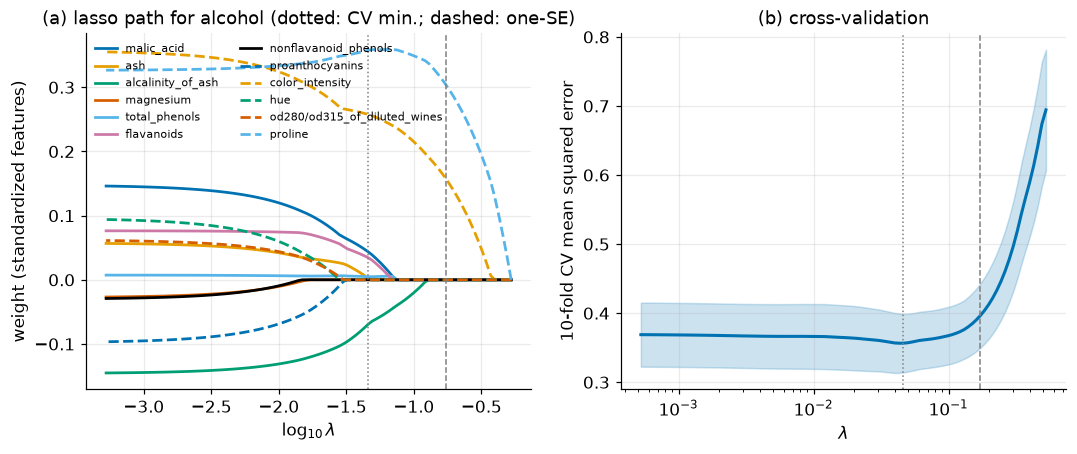

In [50]:
def solution_10_6():
    from sklearn.datasets import load_wine
    from sklearn.linear_model import Lasso, LassoCV, LassoLarsIC, LinearRegression, RidgeCV, lasso_path
    from sklearn.model_selection import KFold, train_test_split
    from sklearn.preprocessing import StandardScaler

    wine = load_wine()
    j_alc = list(wine.feature_names).index("alcohol")
    names = [f for f in wine.feature_names if f != "alcohol"]
    X, y = np.delete(wine.data, j_alc, axis=1), wine.data[:, j_alc]
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=SEED)
    sc = StandardScaler().fit(Xtr)
    Z, Zt = sc.transform(Xtr), sc.transform(Xte)
    n = len(ytr)
    print(f"{n} training and {len(yte)} test wines, {len(names)} features; standard deviation of alcohol in the training set: {ytr.std():.3f}")

    kf = KFold(10, shuffle=True, random_state=SEED)
    lc = LassoCV(alphas=100, cv=kf).fit(Z, ytr)
    mean, se = lc.mse_path_.mean(axis=1), lc.mse_path_.std(axis=1, ddof=1) / np.sqrt(10)
    i_min = int(np.argmin(mean))
    i_1se = int(np.where(mean <= mean[i_min] + se[i_min])[0].min())          # alphas_ is decreasing: the first index is the largest lambda
    lam = {"lasso, CV minimum": lc.alphas_[i_min], "lasso, one-SE rule": lc.alphas_[i_1se]}
    models = {name: Lasso(alpha=a, tol=1e-12, max_iter=200000).fit(Z, ytr) for name, a in lam.items()}
    for crit in ["aic", "bic"]:
        ic = LassoLarsIC(criterion=crit).fit(Z, ytr)
        lam[f"lasso, {crit.upper()}"] = ic.alpha_
        models[f"lasso, {crit.upper()}"] = Lasso(alpha=ic.alpha_, tol=1e-12, max_iter=200000).fit(Z, ytr)
    rows = []
    for name, m in models.items():
        sel = [names[j] for j in np.flatnonzero(m.coef_)]
        rows.append({"model": name, "lambda": lam[name], "features": len(sel), "test RMSE": np.sqrt(np.mean((m.predict(Zt) - yte) ** 2))})
        print(f"{name:<20} lambda = {lam[name]:.4f}: {', '.join(sel)}")
    ols = LinearRegression().fit(Z, ytr)
    rg = RidgeCV(alphas=np.logspace(-3, 3, 50)).fit(Z, ytr)
    rows += [{"model": "least squares", "lambda": 0.0, "features": len(names), "test RMSE": np.sqrt(np.mean((ols.predict(Zt) - yte) ** 2))},
             {"model": f"ridge (alpha = {rg.alpha_:.2f})", "lambda": rg.alpha_, "features": len(names), "test RMSE": np.sqrt(np.mean((rg.predict(Zt) - yte) ** 2))}]
    print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.4g}"))

    m = models["lasso, CV minimum"]
    r = ytr - m.predict(Z)
    g = Z.T @ r / n
    act = m.coef_ != 0
    print(f"KKT at the CV minimum (lambda = {lam['lasso, CV minimum']:.4f}): max |g_j - lambda sign(w_j)| over active = {np.abs(g[act] - lam['lasso, CV minimum'] * np.sign(m.coef_[act])).max():.1e}; "
          f"max |g_j| over inactive = {np.abs(g[~act]).max() if (~act).any() else 0:.4f} <= lambda")

    alphas, coefs, _ = lasso_path(Z, ytr - ytr.mean(), alphas=lc.alphas_)
    fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
    ax = axes[0]
    palette = [BLUE, ORANGE, GREEN, VERMILION, SKY, PURPLE, "black"]
    for j in range(len(names)):
        ax.plot(np.log10(alphas), coefs[j], color=palette[j % 7], ls=["-", "--", ":"][j // 7 % 3], lw=1.8, label=names[j])
    for a, ls in [(lam["lasso, CV minimum"], ":"), (lam["lasso, one-SE rule"], "--")]:
        ax.axvline(np.log10(a), color="gray", ls=ls, lw=1)
    ax.set(xlabel=r"$\log_{10}\lambda$", ylabel="weight (standardized features)", title="(a) lasso path for alcohol (dotted: CV min.; dashed: one-SE)")
    ax.legend(frameon=False, fontsize=7, ncol=2, loc="upper left")
    ax = axes[1]
    ax.semilogx(lc.alphas_, mean, color=BLUE, lw=2)
    ax.fill_between(lc.alphas_, mean - se, mean + se, color=BLUE, alpha=0.2)
    ax.axvline(lam["lasso, CV minimum"], color="gray", ls=":", lw=1)
    ax.axvline(lam["lasso, one-SE rule"], color="gray", ls="--", lw=1)
    ax.set(xlabel=r"$\lambda$", ylabel="10-fold CV mean squared error", title="(b) cross-validation")
    plt.show()


solution_10_6()

The criteria choose $\lambda=0.046$ (CV minimum, 7 of the 12 features), $0.172$ (one-SE rule, only `color_intensity` and `proline`), $0.031$ (AIC, 8 features) and $0.075$ (BIC, 4 features: `alcalinity_of_ash`, `total_phenols`, `color_intensity`, `proline`): the BIC and the one-SE rule give the small models, as in Section 10.7. On the 45 test wines the test RMSE is $0.434$ (AIC), $0.436$ (ridge), $0.437$ (CV minimum), $0.443$ (least squares) and $0.449$ (BIC), all within $0.015$ of each other, and $0.486$ for the two-feature model of the one-SE rule, about $11\%$ higher: here the parsimonious model has a visible cost, which 45 test wines cannot confirm. At the CV minimum the optimality conditions hold to $2\cdot10^{-13}$ on the active set, and the largest correlation with the residual among the five features that are zero is $0.037$, below $\lambda=0.046$.

In [51]:
def solution_10_7():
    from sklearn.datasets import load_diabetes, load_wine
    from sklearn.linear_model import ElasticNet
    from sklearn.model_selection import train_test_split
    from sklearn.preprocessing import PolynomialFeatures, StandardScaler

    def soft(a, t):
        return np.sign(a) * np.maximum(np.abs(a) - t, 0.0)

    def objective(Z, y, w, lam1, lam2):
        r = y - Z @ w
        return r @ r / (2 * len(y)) + lam1 * np.abs(w).sum() + 0.5 * lam2 * w @ w

    def cd_enet(Z, y, lam1, lam2, sweeps):
        n, p = Z.shape
        w, r = np.zeros(p), y.copy()
        col = (Z ** 2).sum(axis=0) / n
        objs = []
        for _ in range(sweeps):
            for j in range(p):
                rho = Z[:, j] @ r / n + col[j] * w[j]
                new = soft(rho, lam1) / (col[j] + lam2)
                r -= (new - w[j]) * Z[:, j]
                w[j] = new
            objs.append(objective(Z, y, w, lam1, lam2))
        return w, np.array(objs)

    # (a) Wine, alcohol against the other 12 features
    wine = load_wine()
    j_alc = list(wine.feature_names).index("alcohol")
    X, y = np.delete(wine.data, j_alc, axis=1), wine.data[:, j_alc]
    Xtr, _, ytr, _ = train_test_split(X, y, test_size=0.25, random_state=SEED)
    Z = StandardScaler().fit_transform(Xtr)
    yc = ytr - ytr.mean()
    rows = []
    for lam1, lam2 in [(0.05, 0.0), (0.05, 0.1), (0.1, 0.3)]:
        w, _ = cd_enet(Z, yc, lam1, lam2, 300)
        sk = ElasticNet(alpha=lam1 + lam2, l1_ratio=lam1 / (lam1 + lam2), fit_intercept=False, tol=1e-14, max_iter=500000).fit(Z, yc)
        rows.append({"lambda1": lam1, "lambda2": lam2, "non-zeros": int((w != 0).sum()), "max |ours - ElasticNet|": np.abs(w - sk.coef_).max()})
    print("(a) Wine:")
    print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.3g}"))

    # (b) sweeps to reach a gap of 1e-10 on the 65 quadratic features of Diabetes
    d = load_diabetes()
    Xd, _, yd, _ = train_test_split(d.data, d.target, test_size=0.25, random_state=SEED)
    P = StandardScaler().fit_transform(PolynomialFeatures(2, include_bias=False).fit_transform(Xd))
    yc = yd - yd.mean()
    n = len(yc)
    ev = np.linalg.eigvalsh(P.T @ P / n)
    print(f"(b) {P.shape[1]} quadratic features, 331 patients: smallest and largest eigenvalue of the Hessian of the data term: {ev.min():.2e}, {ev.max():.2f}")
    rows = []
    for lam2 in [0.0, 0.1, 1.0]:
        _, objs = cd_enet(P, yc, 1.0, lam2, 20000)
        gap = objs - objs[-1]
        k = int(np.argmax(gap[:-1] < 1e-10)) + 1
        rows.append({"lambda2": lam2, "smallest eigenvalue of the Hessian": ev.min() + lam2, "sweeps to a gap of 1e-10": k})
    print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.3g}"))


solution_10_7()

(a) Wine:
 lambda1  lambda2  non-zeros  max |ours - ElasticNet|
    0.05        0          6                    1e-14
    0.05      0.1          7                 4.13e-15
     0.1      0.3          4                 2.84e-16
(b) 65 quadratic features, 331 patients: smallest and largest eigenvalue of the Hessian of the data term: -4.16e-16, 10.79


 lambda2  smallest eigenvalue of the Hessian  sweeps to a gap of 1e-10
       0                           -4.16e-16                        79
     0.1                                 0.1                        64
       1                                   1                        22


(a) Our coordinate descent agrees with `ElasticNet` to $10^{-14}$ in the three settings, with 6, 7 and 4 non-zero weights. (b) The 65 standardized quadratic features have a Hessian of the data term with the smallest eigenvalue at rounding level ($3\cdot10^{-17}$): the feature `sex` takes two values, so `sex^2` is an affine function of `sex` and, after standardizing, the two columns are equal up to sign. The lasso is therefore not strongly convex and coordinate descent needs $79$ sweeps to bring the objective gap below $10^{-10}$; with $\lambda_2=0.1$ it needs $64$ and with $\lambda_2=1$ only $22$. The ridge term adds $\lambda_2$ to every eigenvalue of the Hessian, so that the problem is $\lambda_2$-strongly convex, and by Theorem 7.5 the convergence is linear with a rate that improves with $\lambda_2$. The gain is the one of the augmented-data form of Proposition 10.13: the extra rows make the design full rank and better conditioned.

 noise columns m    p  baseline  least squares  ridge  lasso  elastic net  noise kept (lasso)  noise kept (elastic net)
               0   12     0.810          0.556  0.544  0.544        0.543               0.000                     0.000
              10   22     0.810          0.584  0.568  0.551        0.550               3.250                     3.800
             100  112     0.810          1.522  0.666  0.556        0.561               5.800                     7.600
            1000 1012     0.810            NaN  0.776  0.574        0.586              10.000                    14.950
[16 s]


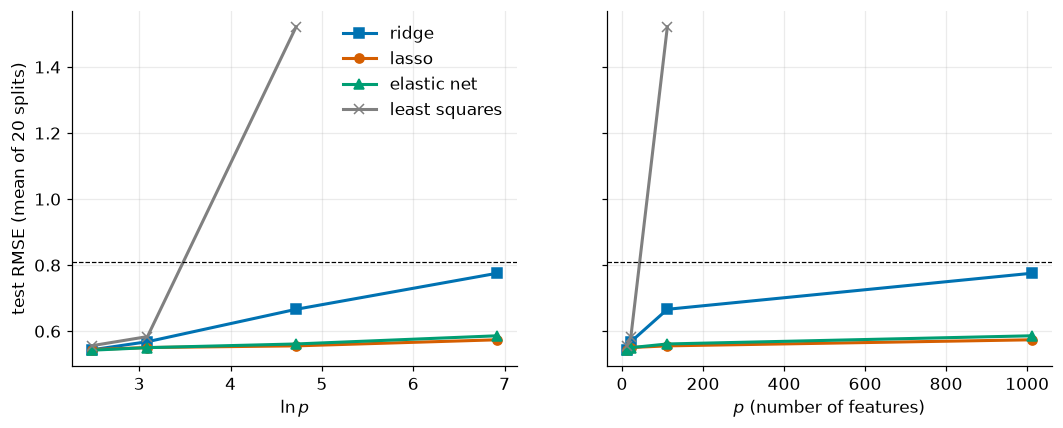

In [52]:
def solution_10_8():
    from sklearn.datasets import load_wine
    from sklearn.linear_model import ElasticNetCV, LassoCV, LinearRegression, RidgeCV
    from sklearn.model_selection import train_test_split
    from sklearn.preprocessing import StandardScaler

    wine = load_wine()
    j_alc = list(wine.feature_names).index("alcohol")
    X, y = np.delete(wine.data, j_alc, axis=1), wine.data[:, j_alc]
    p0 = X.shape[1]
    rows = []
    t0 = time.time()
    for m in [0, 10, 100, 1000]:
        res = {k: [] for k in ["least squares", "ridge", "lasso", "elastic net"]}
        noise_sel = {"lasso": [], "elastic net": []}
        for s in range(20):
            rng = np.random.default_rng(1000 * s + m)
            Xa = np.column_stack([X, rng.normal(size=(len(y), m))]) if m else X
            Xtr, Xte, ytr, yte = train_test_split(Xa, y, test_size=0.25, random_state=s)
            sc = StandardScaler().fit(Xtr)
            Z, Zt = sc.transform(Xtr), sc.transform(Xte)
            if Z.shape[1] < len(ytr) - 2:
                res["least squares"].append(np.mean((LinearRegression().fit(Z, ytr).predict(Zt) - yte) ** 2))
            res["ridge"].append(np.mean((RidgeCV(alphas=np.logspace(-2, 5, 30)).fit(Z, ytr).predict(Zt) - yte) ** 2))
            lc = LassoCV(alphas=50, cv=5, random_state=s).fit(Z, ytr)
            en = ElasticNetCV(l1_ratio=0.5, alphas=50, cv=5, random_state=s).fit(Z, ytr)
            res["lasso"].append(np.mean((lc.predict(Zt) - yte) ** 2))
            res["elastic net"].append(np.mean((en.predict(Zt) - yte) ** 2))
            noise_sel["lasso"].append(int((lc.coef_[p0:] != 0).sum()))
            noise_sel["elastic net"].append(int((en.coef_[p0:] != 0).sum()))
        rows.append({"noise columns m": m, "p": p0 + m, "baseline": np.sqrt(np.var(y)),
                     **{k: (np.sqrt(np.mean(v)) if v else np.nan) for k, v in res.items()},
                     "noise kept (lasso)": np.mean(noise_sel["lasso"]), "noise kept (elastic net)": np.mean(noise_sel["elastic net"])})
    df = pd.DataFrame(rows)
    print(df.to_string(index=False, float_format=lambda v: f"{v:.3f}"))
    print(f"[{time.time() - t0:.0f} s]")
    fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2), sharey=True)
    for ax, xs, xl in [(axes[0], np.log(df["p"]), r"$\ln p$"), (axes[1], df["p"], "$p$ (number of features)")]:
        for name, c, mk in [("ridge", BLUE, "s"), ("lasso", VERMILION, "o"), ("elastic net", GREEN, "^"), ("least squares", "gray", "x")]:
            ax.plot(xs, df[name], marker=mk, color=c, lw=2, label=name)
        ax.axhline(df["baseline"].iloc[0], color="black", lw=0.8, ls="--")
        ax.set(xlabel=xl)
    axes[0].set(ylabel="test RMSE (mean of 20 splits)")
    axes[0].legend(frameon=False)
    plt.show()


with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=ConvergenceWarning)   # LassoCV tries very small lambdas, where the solver stops at its iteration cap
    solution_10_8()

With alcohol as the response and no noise, the four methods are within $0.013$ of each other ($0.544$ to $0.556$; the baseline, the standard deviation of the response, is $0.810$). When useless columns are appended, least squares goes from $0.556$ to $0.584$ with 10 noise columns and to $1.52$ with 100 ($p=112$ for 133 training wines), and is undefined for 1,000. Ridge degrades steadily, to $0.776$ at $m=1000$, which is $87\%$ of the way from its own error to the baseline. The lasso goes from $0.544$ to $0.574$, $11\%$ of the way, and keeps on average $10$ of the $1000$ noise columns; the elastic net behaves like the lasso for prediction ($0.586$) and keeps more noise columns ($15$). Against $\ln p$ the lasso errors ($0.544$, $0.551$, $0.556$, $0.574$ at $\ln p=2.5, 3.1, 4.7, 6.9$) are close to a straight line, while those of ridge rise much faster; this is what Theorem 10.12 allows, but a bound is not a measurement, and with four values of $m$ and noisy estimates we cannot say more than that the data agree with it.

alpha at the one-SE rule: lasso 7.49, elastic net 1.72 (l1_ratio 0.5)
     method full fit: real / noise frequency >= 0.7: real / noise  noise columns with frequency >= 0.2  largest noise frequency
      lasso                  4 / 2                          4 / 0                                    4                     0.50
elastic net                10 / 17                        10 / 20                                   20                     0.99
lasso: bp 1.00, bmi 1.00, s5 1.00, s3 0.97, noise8 0.50, noise5 0.44, sex 0.32, noise20 0.31, noise10 0.24, s6 0.20, noise14 0.19, noise16 0.15
elastic net: sex 1.00, bmi 1.00, bp 1.00, s4 1.00, s3 1.00, s5 1.00, s6 1.00, noise5 0.99, noise8 0.99, noise20 0.96, noise9 0.94, age 0.93


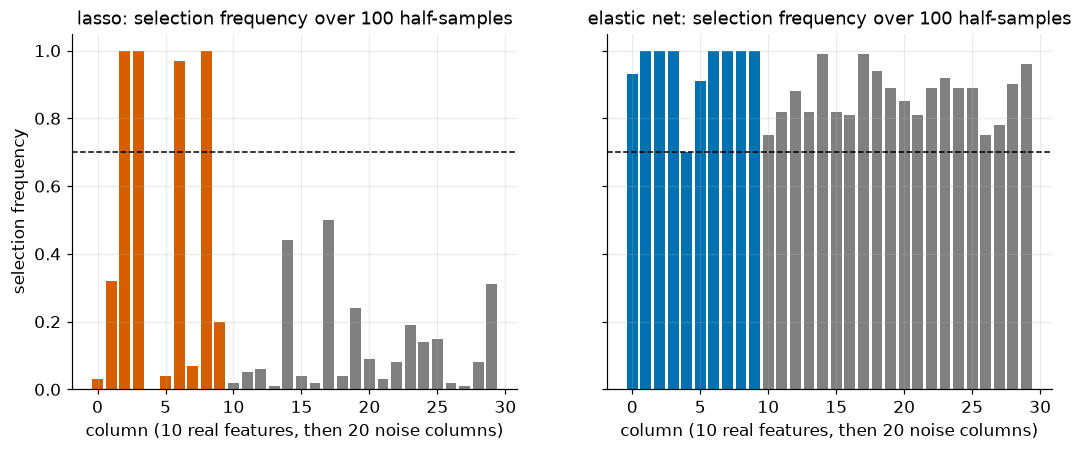

In [53]:
def solution_10_9():
    from sklearn.datasets import load_diabetes
    from sklearn.linear_model import ElasticNet, ElasticNetCV, Lasso, LassoCV
    from sklearn.model_selection import KFold, train_test_split
    from sklearn.preprocessing import StandardScaler

    d = load_diabetes()
    Xtr, _, ytr, _ = train_test_split(d.data, d.target, test_size=0.25, random_state=SEED)
    rng = np.random.default_rng(SEED)
    Xa = np.column_stack([Xtr, rng.normal(size=(len(ytr), 20))])
    names = list(d.feature_names) + [f"noise{j + 1}" for j in range(20)]
    Z = StandardScaler().fit_transform(Xa)
    n = len(ytr)
    kf = KFold(10, shuffle=True, random_state=SEED)

    def one_se(model):
        mean = model.mse_path_.mean(axis=1)
        se = model.mse_path_.std(axis=1, ddof=1) / np.sqrt(10)
        i = int(np.argmin(mean))
        return model.alphas_[int(np.where(mean <= mean[i] + se[i])[0].min())]

    lam_l = one_se(LassoCV(alphas=100, cv=kf).fit(Z, ytr))
    lam_e = one_se(ElasticNetCV(l1_ratio=0.5, alphas=100, cv=kf).fit(Z, ytr))
    cfg = {"lasso": lambda: Lasso(alpha=lam_l, tol=1e-8, max_iter=50000), "elastic net": lambda: ElasticNet(alpha=lam_e, l1_ratio=0.5, tol=1e-8, max_iter=50000)}
    sub_rng = np.random.default_rng(SEED + 1)
    halves = [sub_rng.choice(n, n // 2, replace=False) for _ in range(100)]
    freq, full = {}, {}
    for name, make in cfg.items():
        sel = np.array([make().fit(Z[h], ytr[h]).coef_ != 0 for h in halves])
        freq[name] = sel.mean(axis=0)
        full[name] = make().fit(Z, ytr).coef_ != 0
    print(f"alpha at the one-SE rule: lasso {lam_l:.2f}, elastic net {lam_e:.2f} (l1_ratio 0.5)")
    rows = []
    for name in cfg:
        stable = freq[name] >= 0.7
        rows.append({"method": name, "full fit: real / noise": f"{int(full[name][:10].sum())} / {int(full[name][10:].sum())}",
                     "frequency >= 0.7: real / noise": f"{int(stable[:10].sum())} / {int(stable[10:].sum())}",
                     "noise columns with frequency >= 0.2": int((freq[name][10:] >= 0.2).sum()),
                     "largest noise frequency": freq[name][10:].max()})
    print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.2f}"))
    for name in cfg:
        top = np.argsort(-freq[name])[:12]
        print(f"{name}: " + ", ".join(f"{names[j]} {freq[name][j]:.2f}" for j in top))
    fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2), sharey=True)
    for ax, (name, c) in zip(axes, [("lasso", VERMILION), ("elastic net", BLUE)]):
        colors = [c if j < 10 else "gray" for j in range(30)]
        ax.bar(range(30), freq[name], color=colors)
        ax.axhline(0.7, color="black", ls="--", lw=1)
        ax.set(xlabel="column (10 real features, then 20 noise columns)", title=f"{name}: selection frequency over 100 half-samples")
    axes[0].set_ylabel("selection frequency")
    plt.show()


with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=ConvergenceWarning)   # LassoCV tries very small lambdas, where the solver stops at its iteration cap
    solution_10_9()

The one-SE penalty of the lasso is $7.49$; the one-SE penalty of the elastic net is much smaller ($1.72$, with $\lambda_1=0.86$), because its cross-validation curve is flat and the ridge term makes the noise columns almost harmless for prediction. A single lasso fit on the full training set keeps 4 real features and 2 of the 20 noise columns. Stability selection with a threshold of $0.7$ keeps exactly the four real features that are always selected (`bp`, `bmi`, `s5` at frequency $1.00$, `s3` at $0.97$) and none of the noise: the most frequent noise column (`noise8`) has frequency $0.50$, and `sex`, with $0.32$, is left out. The elastic net tells another story: with its cross-validated penalty it keeps all ten real features and *all twenty* noise columns in more than $90\%$ of the half-samples (the most frequent noise column has frequency $0.99$), so no threshold separates real from noise. The elastic net is a prediction method that happens to be sparse; when the goal is to find the few features that matter among many useless ones, the penalty must be chosen for selection (the larger one-SE value of the lasso), and the frequencies, not a single fit, tell which columns to trust.

[5 s]
estimate / variance of the response  mean  5th percentile  95th percentile  repetitions below 1
   CV minimum of LassoCV (reported) 1.022           0.931            1.101                    7
   nested CV of the whole procedure 1.101           1.007            1.252                    1


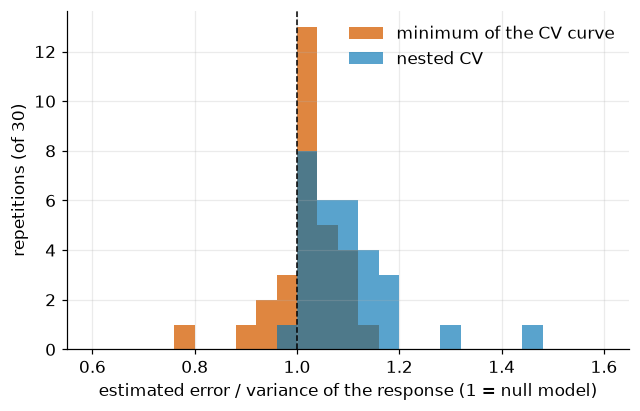

In [54]:
def solution_10_10():
    from sklearn.datasets import load_diabetes
    from sklearn.linear_model import LassoCV
    from sklearn.model_selection import KFold
    from sklearn.preprocessing import StandardScaler

    d = load_diabetes()
    reps, n, m = 30, 60, 200
    rows = []
    t0 = time.time()
    for r in range(reps):
        rng = np.random.default_rng(r)
        idx = rng.choice(len(d.target), n, replace=False)
        X = np.column_stack([d.data[idx], rng.normal(size=(n, m))])
        y = rng.permutation(d.target[idx])                                  # shuffled response: no feature carries information
        Z = StandardScaler().fit_transform(X)
        lc = LassoCV(alphas=50, cv=5, random_state=r).fit(Z, y)
        cv_min = lc.mse_path_.mean(axis=1).min()
        outer, errs = KFold(5, shuffle=True, random_state=r), []
        for tr, te in outer.split(Z):
            sc = StandardScaler().fit(X[tr])
            inner = LassoCV(alphas=50, cv=5, random_state=r).fit(sc.transform(X[tr]), y[tr])
            errs.append(np.mean((inner.predict(sc.transform(X[te])) - y[te]) ** 2))
        rows.append({"variance of y": np.var(y), "CV minimum": cv_min, "nested CV": np.mean(errs)})
    df = pd.DataFrame(rows)
    print(f"[{time.time() - t0:.0f} s]")
    ratio = df[["CV minimum", "nested CV"]].div(df["variance of y"], axis=0)
    print(pd.DataFrame({"estimate / variance of the response": ["CV minimum of LassoCV (reported)", "nested CV of the whole procedure"],
                        "mean": [ratio["CV minimum"].mean(), ratio["nested CV"].mean()],
                        "5th percentile": [ratio["CV minimum"].quantile(0.05), ratio["nested CV"].quantile(0.05)],
                        "95th percentile": [ratio["CV minimum"].quantile(0.95), ratio["nested CV"].quantile(0.95)],
                        "repetitions below 1": [int((ratio["CV minimum"] < 1).sum()), int((ratio["nested CV"] < 1).sum())]}).to_string(index=False, float_format=lambda v: f"{v:.3f}"))
    fig, ax = plt.subplots(figsize=(6.6, 4.0))
    b = np.linspace(0.6, 1.6, 26)
    ax.hist(ratio["CV minimum"], bins=b, color=VERMILION, alpha=0.75, label="minimum of the CV curve")
    ax.hist(ratio["nested CV"], bins=b, color=BLUE, alpha=0.65, label="nested CV")
    ax.axvline(1.0, color="black", ls="--", lw=1)
    ax.set(xlabel="estimated error / variance of the response (1 = null model)", ylabel="repetitions (of 30)")
    ax.legend(frameon=False)
    plt.show()


with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=ConvergenceWarning)   # LassoCV tries very small lambdas, where the solver stops at its iteration cap
    solution_10_10()

With the response shuffled, the null model has the mean squared error of the variance of the response (ratio 1), and no estimate of the error of a method that learns nothing can honestly be below it. The minimum of the cross-validation curve of `LassoCV`, the number that is usually reported, has a mean ratio of $1.02$ and is below $1$ in $7$ of the 30 repetitions (5th to 95th percentile $0.93$ to $1.10$): in one repetition out of four the method appears to predict better than the null model although there is nothing to predict. The nested estimate of the whole procedure has a mean ratio of $1.10$, is below $1$ in only one repetition, and shows what is true: a lasso with $\lambda$ chosen on noise does worse than the null model, because the selected noise columns add variance. The difference between the two estimates, $0.08$ of the variance on average, is the winner's curse of Section 5.4.3 for the choice of $\lambda$: the minimum of 50 estimated errors is optimistic, and the optimism is largest exactly when the signal is weak.

## C.11 Chapter 11

### Manual exercises

**Solution 11.1 — A tree and its pruning by hand.**

(a) The root has $\bar y=45/8=5.625$ and $\mathrm{RSS}=103.875$. The gains $\frac{n_Ln_R}{8}(\bar y_L-\bar y_R)^2$ of the seven thresholds $1.5,2.5,\dots,7.5$ are $7.875$, $35.042$, $63.075$, $28.125$, $2.408$, $3.375$ and $0.446$, so the first split is at $x\le3.5$, with gain $63.075$. Check: the left child $(3,1,2)$ has mean $2$ and $\mathrm{RSS}=2$, the right child $(9,11,10,4,5)$ has mean $7.8$ and $\mathrm{RSS}=38.8$, and $103.875-2-38.8=63.075$.

(b) In the left child the threshold $1.5$ separates $(3)$ from $(1,2)$ with gain $\frac{1\cdot2}{3}(3-1.5)^2=1.5$ (the threshold $2.5$ gains $0$). In the right child the thresholds $4.5,5.5,6.5,7.5$ gain $1.8$, $16.13$, $36.3$ and $9.8$, so the split is at $x\le6.5$, separating $(9,11,10)$ from $(4,5)$. The four leaves have values $3$, $1.5$, $10$ and $4.5$, residual sums of squares $0$, $0.5$, $2$ and $0.5$, and the training $\mathrm{RSS}$ of the tree is $3$, that is $97.1\%$ less than the root's.

(c) The internal nodes are the root, the left child $L=(3,1,2)$ and the right child $R=(9,11,10,4,5)$. With $R(t)$ the RSS of the node taken as a leaf and $R(T_t)$ that of its subtree:
$$g(L)=\frac{2-0.5}{2-1}=1.5,\qquad g(R)=\frac{38.8-2.5}{2-1}=36.3,\qquad g(\text{root})=\frac{103.875-3}{4-1}=33.625 .$$
The weakest link is $L$: pruning it gives the tree with three leaves $(3,1,2)$, $(9,11,10)$, $(4,5)$ and $\mathrm{RSS}=4.5$. **The values must be recomputed**: now $g(R)=36.3$ is unchanged but $g(\text{root})=\frac{103.875-4.5}{3-1}=49.6875$, so the next weakest link is $R$, not the root, although the root had the smaller value before the first pruning. Pruning $R$ gives the two leaves $(3,1,2)$, $(9,11,10,4,5)$ with $\mathrm{RSS}=40.8$, and $g(\text{root})=\frac{103.875-40.8}{2-1}=63.075$, the gain of the first split; pruning the root leaves a single leaf. The nested sequence is therefore: four leaves for $\alpha<1.5$, three leaves for $1.5\le\alpha<36.3$, two leaves for $36.3\le\alpha<63.075$ and the root alone for $\alpha\ge63.075$ (in units of the residual sum of squares; scikit-learn divides by the number of examples).

**Solution 11.2 — The Gini gain in closed form.**

(a) With $p=(n_Lp_L+n_Rp_R)/n$ the gain is $2p(1-p)-\frac{n_L}{n}2p_L(1-p_L)-\frac{n_R}{n}2p_R(1-p_R)$. The linear terms cancel because $p$ is the weighted average of $p_L$ and $p_R$, and what is left is $2\big[\frac{n_L}{n}p_L^2+\frac{n_R}{n}p_R^2-p^2\big]$, twice the variance of a variable that takes the values $p_L$ and $p_R$ with probabilities $n_L/n$ and $n_R/n$, that is $2\,\frac{n_Ln_R}{n^2}(p_L-p_R)^2$.

(b) With class $1$ as the second class: $p_L=0$, $p_R=10/35=2/7$, $n_L=25$, $n_R=35$, $n=60$, so the gain is $2\cdot\frac{25\cdot35}{3600}\cdot\big(\frac27\big)^2=0.0397$. Directly: the parent has Gini index $2\cdot\frac16\cdot\frac56=0.2778$, the left child $0$ and the right child $2\cdot\frac27\cdot\frac57=0.4082$, weighted $\frac{35}{60}0.4082=0.2381$, and $0.2778-0.2381=0.0397$.

(c) The misclassification rate of the parent is $10/60$, that of the children is $0$ and $10/60$ (weighted): the gain is **zero**, because the majority class is class $0$ in the parent and in both children, so that the error does not see that one child has become pure. The misclassification rate is piecewise linear in $p$ and not strictly concave, so that a split that keeps the majority classes is invisible to it, while the Gini index is strictly concave: by Proposition 11.4 its gain is never negative and it is strictly positive whenever $p_L\ne p_R$, here $0.0397$, a split that isolates a pure node of $25$ examples.

**Solution 11.3 — How many trees?**

(a) By (11.2) the excess of the variance over the floor $\rho\sigma^2$ is $(1-\rho)\sigma^2/B$; requiring it to be at most $0.05\,\rho\sigma^2$ gives $B\ge20\,(1-\rho)/\rho$. For $\rho=0.3$ this is $20\cdot0.7/0.3=46.7$, so $B=47$ trees. For $\rho=0.1$ it is $180$ trees and for $\rho=0.6$ only $14$: the more correlated the trees, the fewer are needed, and the less they help.

(b) Setting $380+\frac{3382-380}{B}=229+\frac{3736-229}{B}$ gives $151=505/B$, that is $B=3.34$: the forest has the smaller variance from $B=4$ on (the measured values at $B=5$ are $980$ and $930$, in Section 11.6.4). For $B=1$ the variance is $\sigma^2$ itself, and the forest's is larger ($3736$ against $3382$) because its trees are not allowed to use the best split at every node.

(c) The derivative of (11.2) with respect to $B$ is $-(1-\rho)\sigma^2/B^2\le0$, so the variance decreases with $B$, and its limit is $\rho\sigma^2$. If $\rho$ is close to $1$ the floor is nearly $\sigma^2$: the average of any number of nearly identical trees is as variable as one of them, and the only remedy is to decorrelate the trees, which is what $m_{\text{try}}$ does.

**Solution 11.4 — The weak learner is useless in the next round.**

(a) After the update the examples misclassified by $h_m$ have total weight $\varepsilon_me^{\alpha_m}/Z_m$, with $e^{\alpha_m}=\sqrt{(1-\varepsilon_m)/\varepsilon_m}$ and $Z_m=2\sqrt{\varepsilon_m(1-\varepsilon_m)}$ (Proposition 11.11 with normalized weights). So the weighted error is $\dfrac{\varepsilon_m\sqrt{(1-\varepsilon_m)/\varepsilon_m}}{2\sqrt{\varepsilon_m(1-\varepsilon_m)}}=\dfrac{\sqrt{\varepsilon_m(1-\varepsilon_m)}}{2\sqrt{\varepsilon_m(1-\varepsilon_m)}}=\dfrac12$.

(b) $\varepsilon_m=0.2$, $\alpha_m=\frac12\ln4=0.693$, $e^{\alpha_m}=2$. The misclassified point has weight $0.2\cdot2=0.4$ and each of the four others $0.2\cdot\frac12=0.1$, so $Z_m=0.4+0.4=0.8=2\sqrt{0.2\cdot0.8}$ and the new weights are $0.5$ for the misclassified point and $0.125$ for each of the other four. The weighted error of $h_m$ is $0.5$.

(c) Under the new weights the classifier $h_m$ is no better than a coin toss, so the next learner has to be a different one, one that is right where $h_m$ was wrong: this is how each round brings new information, and why the same stump is never useful twice in a row.

**Solution 11.5 — AdaBoost is gradient boosting for the exponential loss.**

(a) $-\partial\ell/\partial F=ye^{-yF}$, and $e^{-y_iF_{m-1}(\mathbf{x}_i)}=Ww_i$, so $r_i=Wy_iw_i$.

(b) $\sum_ir_ih(\mathbf{x}_i)=W\sum_iw_iy_ih(\mathbf{x}_i)$, and $y_ih(\mathbf{x}_i)=+1$ on the examples that $h$ classifies correctly (total weight $1-\varepsilon$) and $-1$ on the others (total weight $\varepsilon$), so the sum is $W(1-2\varepsilon)$. Among classifiers with values $\pm1$ the one that is most correlated with the pseudo-residuals is the one with the least weighted error, the choice of AdaBoost.

(c) $\sum_ie^{-y_i(F_{m-1}(\mathbf{x}_i)+\alpha h(\mathbf{x}_i))}=W\big[(1-\varepsilon)e^{-\alpha}+\varepsilon e^{\alpha}\big]$, minimized at $\alpha=\frac12\ln\frac{1-\varepsilon}{\varepsilon}$ (Proposition 11.11).

(d) $g_i=\partial\ell/\partial F=-y_iWw_i$ and $q_i=\partial^2\ell/\partial F^2=y_i^2Ww_i=Ww_i$, so the Newton value of a leaf is $w_j^\ast=-G_j/Q_j=\sum_{i\in R_j}y_iw_i\big/\sum_{i\in R_j}w_i$, the weighted mean of the labels in the leaf, a number in $[-1,1]$. It is the leaf value of Gentle AdaBoost. A pure leaf gets $\pm1$, whereas the line search of (c) applied to a leaf of weighted error $0$ would give an infinite value: the Newton step is a damped version of it.

### Python exercises

133 training and 45 test wines, 13 features, class counts in the training set [44 53 36]
the full tree has 8 leaves; the path has 5 distinct break points (without the root-only one)


CV minimum: alpha = 0.0144, 5 leaves, error 0.089 (SE 0.030);  one-SE rule: alpha = 0.0661, 3 leaves, error 0.112


                             model  test errors  error rate    SE
                         full tree            2       0.044 0.031
           pruned tree, CV minimum            3       0.067 0.037
               pruned tree, one-SE            6       0.133 0.051
               random forest (300)            0       0.000 0.000
      AdaBoost, stumps (20 rounds)            3       0.067 0.037
logistic regression (standardized)            0       0.000 0.000


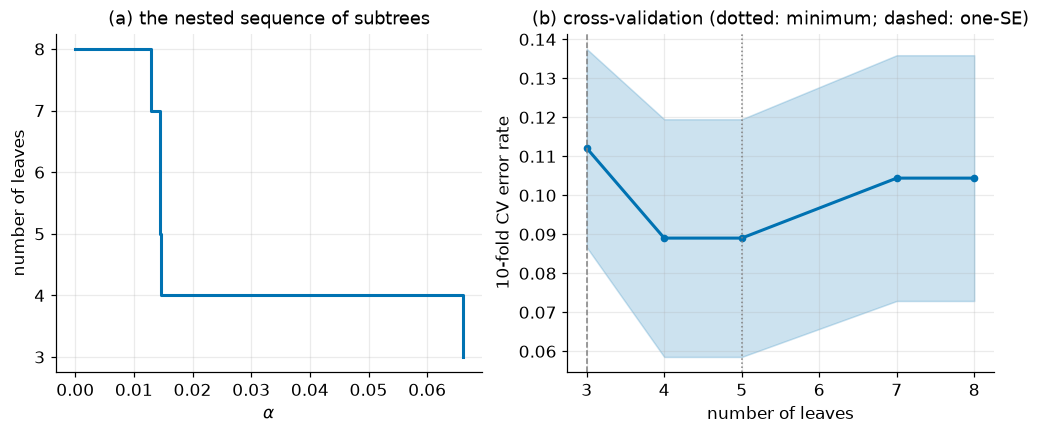

In [55]:
def solution_11_6():
    from sklearn.datasets import load_wine
    from sklearn.ensemble import AdaBoostClassifier, RandomForestClassifier
    from sklearn.linear_model import LogisticRegression
    from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score, train_test_split
    from sklearn.pipeline import make_pipeline
    from sklearn.preprocessing import StandardScaler
    from sklearn.tree import DecisionTreeClassifier

    wine = load_wine()
    Xtr, Xte, ytr, yte = train_test_split(wine.data, wine.target, test_size=0.25, random_state=SEED, stratify=wine.target)
    print(f"{len(ytr)} training and {len(yte)} test wines, {Xtr.shape[1]} features, class counts in the training set {np.bincount(ytr)}")
    full = DecisionTreeClassifier(random_state=SEED).fit(Xtr, ytr)
    raw = full.cost_complexity_pruning_path(Xtr, ytr).ccp_alphas
    alphas = np.unique(np.round(raw, 12))[:-1]                       # distinct break points, without the one that leaves only the root
    leaves = np.array([DecisionTreeClassifier(ccp_alpha=a * (1 + 1e-9), random_state=SEED).fit(Xtr, ytr).get_n_leaves() for a in alphas])
    print(f"the full tree has {full.get_n_leaves()} leaves; the path has {len(alphas)} distinct break points (without the root-only one)")

    skf = StratifiedKFold(10, shuffle=True, random_state=SEED)
    err = np.array([1 - cross_val_score(DecisionTreeClassifier(ccp_alpha=a * (1 + 1e-9), random_state=SEED), Xtr, ytr, cv=skf) for a in alphas])
    mean, se = err.mean(axis=1), err.std(axis=1, ddof=1) / np.sqrt(skf.get_n_splits())
    i_min = int(np.argmin(mean))
    i_1se = int(np.where(mean <= mean[i_min] + se[i_min])[0].max())  # the largest alpha within one SE of the minimum
    print(f"CV minimum: alpha = {alphas[i_min]:.4f}, {leaves[i_min]} leaves, error {mean[i_min]:.3f} (SE {se[i_min]:.3f});"
          f"  one-SE rule: alpha = {alphas[i_1se]:.4f}, {leaves[i_1se]} leaves, error {mean[i_1se]:.3f}")

    ada = GridSearchCV(AdaBoostClassifier(DecisionTreeClassifier(max_depth=1), random_state=SEED), {"n_estimators": [1, 2, 5, 10, 20, 50, 100, 200]}, cv=skf).fit(Xtr, ytr)
    models = {
        "full tree": full,
        "pruned tree, CV minimum": DecisionTreeClassifier(ccp_alpha=alphas[i_min] * (1 + 1e-9), random_state=SEED).fit(Xtr, ytr),
        "pruned tree, one-SE": DecisionTreeClassifier(ccp_alpha=alphas[i_1se] * (1 + 1e-9), random_state=SEED).fit(Xtr, ytr),
        "random forest (300)": RandomForestClassifier(300, random_state=SEED, n_jobs=2).fit(Xtr, ytr),
        f"AdaBoost, stumps ({ada.best_params_['n_estimators']} rounds)": ada.best_estimator_,
        "logistic regression (standardized)": make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)).fit(Xtr, ytr),
    }
    rows = []
    for name, m in models.items():
        e = float(np.mean(m.predict(Xte) != yte))
        rows.append({"model": name, "test errors": int(round(e * len(yte))), "error rate": e, "SE": float(np.sqrt(e * (1 - e) / len(yte)))})
    print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.3f}"))

    fig, axes = plt.subplots(1, 2, figsize=(11, 4.0))
    axes[0].step(alphas, leaves, where="post", color=BLUE, lw=2)
    axes[0].set(xlabel=r"$\alpha$", ylabel="number of leaves", title="(a) the nested sequence of subtrees")
    axes[1].plot(leaves, mean, color=BLUE, lw=2, marker="o", ms=4)
    axes[1].fill_between(leaves, mean - se, mean + se, color=BLUE, alpha=0.2)
    axes[1].axvline(leaves[i_min], color="gray", ls=":", lw=1)
    axes[1].axvline(leaves[i_1se], color="gray", ls="--", lw=1)
    axes[1].set(xlabel="number of leaves", ylabel="10-fold CV error rate", title="(b) cross-validation (dotted: minimum; dashed: one-SE)")
    plt.show()


solution_11_6()

The full tree has only $8$ leaves (the three Wine classes are easy to separate and the training set has $133$ wines), so pruning has little room: the cross-validated error is $0.089$ (SE $0.030$) at the minimum, with $5$ leaves, and $0.112$ at the one-SE value, with $3$ leaves. On the $45$ test wines the full tree makes $2$ errors, the tree of the CV minimum $3$, AdaBoost with $20$ stumps $3$, the one-SE tree $6$, and the forest and the standardized logistic regression none. With $45$ test examples the standard error of an error rate is $0.03$ to $0.05$, so the order among the full tree, the minimum-CV tree and AdaBoost ($2$ or $3$ errors) means nothing, and the $6$ errors of the three-leaf tree are the price of its simplicity, which the cross-validation had put within one standard error of the minimum. A rate of zero errors gives a standard error of zero by the formula, which is not a sensible estimate; the "rule of three" bounds the true error rate by about $3/45\approx0.07$ with $95\%$ confidence. What can be concluded is that the ensembles and the linear model are at least as good as any single tree on these data, and that a test set of $45$ wines cannot rank methods that are a few errors apart.

In [56]:
def solution_11_7():
    from sklearn.datasets import load_diabetes
    from sklearn.ensemble import RandomForestRegressor
    from sklearn.model_selection import train_test_split
    from sklearn.tree import DecisionTreeRegressor

    d = load_diabetes()
    Xtr, Xte, ytr, yte = train_test_split(d.data, d.target, test_size=0.25, random_state=SEED)
    n, B = len(ytr), 300
    rng = np.random.default_rng(SEED)
    inbag = np.zeros((B, n), dtype=bool)
    P_tr, P_te = np.zeros((B, n)), np.zeros((B, len(yte)))
    for b in range(B):
        idx = rng.integers(0, n, n)
        tree = DecisionTreeRegressor(max_features=1 / 3, min_samples_leaf=5, random_state=int(rng.integers(2 ** 31 - 1))).fit(Xtr[idx], ytr[idx])
        inbag[b, idx] = True
        P_tr[b], P_te[b] = tree.predict(Xtr), tree.predict(Xte)
    oob = ~inbag
    has = oob.sum(axis=0) > 0
    oob_pred = (P_tr * oob).sum(axis=0)[has] / oob.sum(axis=0)[has]
    rmse = lambda a, b_: float(np.sqrt(np.mean((a - b_) ** 2)))
    rf = RandomForestRegressor(B, max_features=1 / 3, min_samples_leaf=5, oob_score=True, random_state=SEED, n_jobs=2).fit(Xtr, ytr)
    print(f"each patient is out of the bag for {oob.sum(axis=0).mean():.1f} of the {B} trees on average ({oob.mean():.3f}; theory {np.exp(-1):.3f})")
    print(pd.DataFrame([{"forest": "ours", "OOB RMSE": rmse(oob_pred, ytr[has]), "test RMSE": rmse(P_te.mean(axis=0), yte)},
                        {"forest": "scikit-learn", "OOB RMSE": rmse(rf.oob_prediction_, ytr), "test RMSE": rmse(rf.predict(Xte), yte)}]).to_string(index=False, float_format=lambda v: f"{v:.2f}"))

    # (b) patients that are in the bootstrap sample of every one of 10 trees
    no_oob = int((oob[:10].sum(axis=0) == 0).sum())
    sims = [np.sum(np.all([np.isin(np.arange(n), rng.integers(0, n, n)) for _ in range(10)], axis=0)) for _ in range(500)]
    print(f"with B = 10 trees: {no_oob} of {n} patients have no OOB tree in our forest; expected n (1 - (1-1/n)^n)^10 = {n * (1 - (1 - 1 / n) ** n) ** 10:.2f};"
          f" simulation over 500 repetitions: {np.mean(sims):.2f}")
    cum = [int(np.sum(oob[:k].sum(axis=0) == 0)) for k in [5, 10, 20, 50]]
    print("patients without any OOB tree for B = 5, 10, 20, 50 (our forest):", cum)


solution_11_7()

each patient is out of the bag for 110.5 of the 300 trees on average (0.368; theory 0.368)
      forest  OOB RMSE  test RMSE
        ours     58.12      52.21
scikit-learn     57.96      52.50
with B = 10 trees: 1 of 331 patients have no OOB tree in our forest; expected n (1 - (1-1/n)^n)^10 = 3.40; simulation over 500 repetitions: 3.37
patients without any OOB tree for B = 5, 10, 20, 50 (our forest): [37, 1, 0, 0]


Our forest agrees with the library's up to the variation between two forests of $300$ trees grown from different random draws: the OOB RMSE is $58.12$ against $57.96$ and the test RMSE $52.21$ against $52.50$. Each patient is out of the bag for $110.5$ of the $300$ trees on average, $36.8\%$ as in Proposition 11.9. For (b), a patient is in the bootstrap sample of a given tree with probability $0.632$, so the probability of being in all $10$ samples is $0.632^{10}=0.0102$ and the expected number of patients without an OOB tree is $331\cdot0.0102=3.40$; a simulation over $500$ repetitions gives $3.37$. Our forest has one such patient, which is unremarkable (the count is close to a Poisson variable with mean $3.4$, which takes a value of at most $1$ about $15\%$ of the time). With $B=5$ trees $37$ patients ($11\%$) have no OOB prediction, with $B=20$ essentially none ($331\cdot0.632^{20}=0.03$): the OOB error of a very small forest is computed on fewer patients, or on fewer trees per patient, and is more variable.

In [57]:
def solution_11_8():
    from sklearn.datasets import load_diabetes
    from sklearn.ensemble import ExtraTreesRegressor, RandomForestRegressor
    from sklearn.model_selection import train_test_split

    d = load_diabetes()
    Xtr, Xte, ytr, yte = train_test_split(d.data, d.target, test_size=0.25, random_state=SEED)
    R, n_small, B = 40, 100, 50
    makers = {
        "random forest": lambda s: RandomForestRegressor(B, max_features=1 / 3, min_samples_leaf=5, random_state=s, n_jobs=2),
        "extremely randomized trees": lambda s: ExtraTreesRegressor(B, max_features=1 / 3, min_samples_leaf=5, random_state=s, n_jobs=2),
    }
    rng = np.random.default_rng(SEED)
    sets = [rng.choice(len(ytr), n_small, replace=False) for _ in range(R)]
    rows = []
    for name, make in makers.items():
        P = np.zeros((R, B, len(yte)))
        for r, idx in enumerate(sets):
            f = make(r).fit(Xtr[idx], ytr[idx])
            P[r] = np.array([t.predict(Xte) for t in f.estimators_])
        sigma2 = P.var(axis=0, ddof=1).mean()
        cov = np.mean([np.mean((P[:, 2 * k] - P[:, 2 * k].mean(axis=0)) * (P[:, 2 * k + 1] - P[:, 2 * k + 1].mean(axis=0))) * R / (R - 1) for k in range(B // 2)])
        var_avg = P.mean(axis=1).var(axis=0, ddof=1).mean()
        full = make(0).fit(Xtr, ytr)
        rows.append({"method": name, "sigma^2": sigma2, "rho": cov / sigma2, "rho sigma^2": cov, "variance of the average of 50": var_avg,
                     "formula (11.2)": cov + (sigma2 - cov) / B, "test RMSE (full training set)": float(np.sqrt(np.mean((full.predict(Xte) - yte) ** 2)))})
    print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.3g}"))


solution_11_8()

                    method  sigma^2    rho  rho sigma^2  variance of the average of 50  formula (11.2)  test RMSE (full training set)
             random forest 1.97e+03 0.0678          133                            171             170                           51.8
extremely randomized trees 1.22e+03 0.0625         76.1                           92.1            98.9                           53.3


The extra randomization acts almost entirely on $\sigma^2$, not on $\rho$. The variance of a single tree falls from $\sigma^2=1970$ for the random forest to $1220$ for the extremely randomized trees ($-38\%$), while the correlation is about the same ($0.068$ and $0.063$), so the variance of the average of $50$ trees is $171$ against $92$. Equation (11.2) reproduces both ($170$ and $171$ for the forest, $98.9$ and $92.1$ for the extremely randomized trees, a $7\%$ difference with only $40$ training sets). The price is the bias: a random threshold is a worse cut than the best one, and on the whole training set the test RMSE is $53.3$ against $51.8$ for the forest. Whether the variance saved is worth the bias added depends on the data, which is why `ExtraTreesRegressor` is a candidate to try next to the forest and not a replacement for it.

M =  20: largest difference of the decision functions on the test inputs 1.8e-15 (mean 6.9e-16); same predicted classes: True


M = 100: largest difference of the decision functions on the test inputs 6.9e-01 (mean 7.1e-03); same predicted classes: True


 lambda  minimum CV log loss  at round  CV log loss at round 300
 0.0000               0.1258       100                    0.1600
 1.0000               0.1082       252                    0.1087
10.0000               0.1208       299                    0.1208


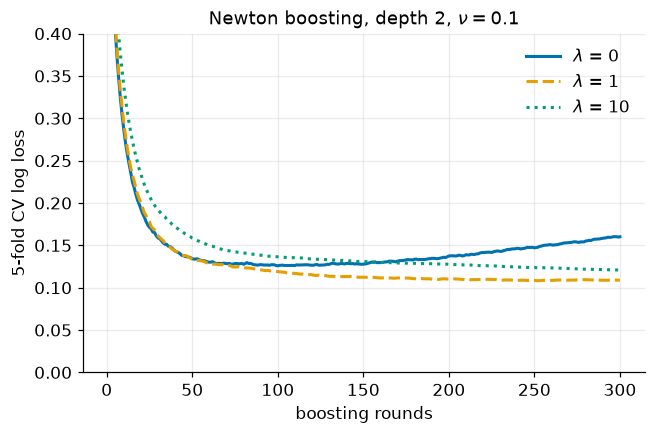

In [58]:
def solution_11_9():
    from sklearn.datasets import load_breast_cancer
    from sklearn.ensemble import GradientBoostingClassifier
    from sklearn.metrics import log_loss
    from sklearn.model_selection import StratifiedKFold, train_test_split
    from sklearn.tree import DecisionTreeRegressor

    bc = load_breast_cancer()
    y_all = 1 - bc.target
    Xtr, Xte, ytr, yte = train_test_split(bc.data, y_all, test_size=0.25, random_state=SEED, stratify=y_all)

    def boost(X, y, M, nu=0.1, depth=2, lam=0.0, Xva=None, yva=None):
        """Gradient boosting with the logistic loss and Newton leaf values. Returns the model and, if a validation set is given, its log loss after each round."""
        p0 = y.mean()
        F0 = np.log(p0 / (1 - p0))
        F, Fva = np.full(len(y), F0), (np.full(len(yva), F0) if Xva is not None else None)
        trees, vals, va_loss = [], [], []
        for m in range(M):
            p = 1 / (1 + np.exp(-F))
            r = y - p
            t = DecisionTreeRegressor(max_depth=depth, random_state=SEED).fit(X, r)
            leaf = t.apply(X)
            num = np.bincount(leaf, weights=r, minlength=t.tree_.node_count)
            den = np.bincount(leaf, weights=p * (1 - p), minlength=t.tree_.node_count)
            val = np.divide(num, den + lam, out=np.zeros_like(num), where=den > 1e-150)
            F = F + nu * val[leaf]
            trees.append(t); vals.append(val)
            if Xva is not None:
                Fva = Fva + nu * val[t.apply(Xva)]
                va_loss.append(log_loss(yva, np.clip(1 / (1 + np.exp(-Fva)), 1e-12, 1 - 1e-12)))
        return (F0, trees, vals, nu), np.array(va_loss)

    def decision(model, X, upto=None):
        F0, trees, vals, nu = model
        return F0 + nu * sum(v[t.apply(X)] for t, v in list(zip(trees, vals))[:upto])

    model, _ = boost(Xtr, ytr, 100)
    for M in [20, 100]:
        sk = GradientBoostingClassifier(n_estimators=M, learning_rate=0.1, max_depth=2, random_state=SEED).fit(Xtr, ytr)
        diff = np.abs(decision(model, Xte, M) - sk.decision_function(Xte))
        print(f"M = {M:3d}: largest difference of the decision functions on the test inputs {diff.max():.1e} (mean {diff.mean():.1e}); same predicted classes: {np.array_equal(decision(model, Xte, M) > 0, sk.decision_function(Xte) > 0)}")

    skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
    M_max = 300
    curves = {}
    for lam in [0.0, 1.0, 10.0]:
        c = np.zeros(M_max)
        for tr, va in skf.split(Xtr, ytr):
            _, l = boost(Xtr[tr], ytr[tr], M_max, lam=lam, Xva=Xtr[va], yva=ytr[va])
            c += l / skf.get_n_splits()
        curves[lam] = c
    print(pd.DataFrame([{"lambda": lam, "minimum CV log loss": c.min(), "at round": int(np.argmin(c)) + 1, "CV log loss at round 300": c[-1]} for lam, c in curves.items()]).to_string(index=False, float_format=lambda v: f"{v:.4f}"))
    fig, ax = plt.subplots(figsize=(6.6, 4.0))
    for (lam, c), color, ls in zip(curves.items(), [BLUE, ORANGE, GREEN], ["-", "--", ":"]):
        ax.plot(np.arange(1, M_max + 1), c, color=color, ls=ls, lw=2, label=rf"$\lambda$ = {lam:g}")
    ax.set(xlabel="boosting rounds", ylabel="5-fold CV log loss", ylim=(0, 0.4), title=r"Newton boosting, depth 2, $\nu=0.1$")
    ax.legend(frameon=False)
    plt.show()


solution_11_9()

After $20$ rounds the decision functions agree to $2\cdot10^{-15}$, and at $100$ rounds the largest difference over the test inputs is $0.69$ on the log-odds scale for one input (mean $0.007$), with the same predicted class for every test patient: the pattern of Section 11.9.2, agreement to rounding and then a divergence at a near-tie (we did not trace this particular divergence). Without regularization the minimum of the $5$-fold cross-validated log loss is $0.1259$ at round $100$, as for the library in Section 11.9.5, and it rises to $0.1597$ at round $300$. With $\lambda=1$ the minimum is **lower and later**, $0.1077$ at round $252$, and the curve is flat up to $300$ rounds ($0.1081$); with $\lambda=10$ learning is too slow, and at round $300$ the curve ($0.1208$) is still falling. The reason is in the denominator of the leaf value $\sum(y_i-p_i)/(\sum p_i(1-p_i)+\lambda)$: a leaf that holds a few patients whom the model already predicts with confidence has $\sum p_i(1-p_i)\approx0$, and without $\lambda$ the step is huge there; this is the source of the overconfidence of Section 11.9.5, and the penalty of Proposition 11.14 removes it where it matters. A moderate $\lambda$ is better than none and than a large one.

In [59]:
def solution_11_10():
    from sklearn.datasets import load_diabetes
    from sklearn.ensemble import RandomForestRegressor
    from sklearn.linear_model import LassoCV
    from sklearn.model_selection import KFold, train_test_split
    from sklearn.preprocessing import StandardScaler

    d = load_diabetes()
    names = list(d.feature_names)
    Xtr, _, ytr, _ = train_test_split(d.data, d.target, test_size=0.25, random_state=SEED)
    Xf, Xv, yf, yv = train_test_split(Xtr, ytr, test_size=0.25, random_state=SEED)
    print(f"forest grown on {len(yf)} patients, importances measured on {len(yv)} others")
    rg = np.random.default_rng(SEED)

    def study(X_fit, X_val, n_perm=30, groups=()):
        rf = RandomForestRegressor(300, max_features=1 / 3, min_samples_leaf=5, random_state=SEED, n_jobs=2).fit(X_fit, yf)
        base = rf.predict(X_val)
        cols = [[j] for j in range(X_val.shape[1])] + [list(g) for g in groups]
        preds = np.zeros((len(cols), n_perm, len(yv)))
        for c, cc in enumerate(cols):
            for k in range(n_perm):
                Xp = X_val.copy()
                Xp[:, cc] = X_val[rg.permutation(len(yv))][:, cc]
                preds[c, k] = rf.predict(Xp)
        return rf, base, cols, preds

    def increase(base, preds, idx):
        rm = lambda p: np.sqrt(np.mean((p - yv[idx]) ** 2, axis=-1))
        return (rm(preds[..., idx]) - rm(base[idx])).mean(axis=-1)

    j1, j2 = names.index("s1"), names.index("s2")
    rf, base, cols, preds = study(Xf, Xv, groups=[(j1, j2)])
    all_idx = np.arange(len(yv))
    imp = increase(base, preds, all_idx)
    boots = np.array([increase(base, preds, rg.integers(0, len(yv), len(yv))) for _ in range(500)])
    lo, hi = np.percentile(boots, [2.5, 97.5], axis=0)
    tab = pd.DataFrame({"feature": names + ["s1 + s2 together"], "MDI": list(rf.feature_importances_) + [np.nan],
                        "permutation: RMSE increase": imp, "95% CI low": lo, "95% CI high": hi})
    print(tab.to_string(index=False, float_format=lambda v: f"{v:.3f}"))
    print(f"correlation of s1 and s2 in the training set: {np.corrcoef(Xtr[:, j1], Xtr[:, j2])[0, 1]:.3f}; baseline RMSE on the validation patients {np.sqrt(np.mean((base - yv) ** 2)):.2f}")

    # (c) twenty noise columns
    noise_f, noise_v = rg.standard_normal((len(yf), 20)), rg.standard_normal((len(yv), 20))
    rf2, base2, cols2, preds2 = study(np.c_[Xf, noise_f], np.c_[Xv, noise_v], n_perm=20)
    imp2 = increase(base2, preds2, all_idx)
    print(f"\nwith 20 noise columns: largest MDI among them {rf2.feature_importances_[10:].max():.4f} (largest MDI of a real feature {rf2.feature_importances_[:10].max():.4f});"
          f" largest permutation increase among them {imp2[10:].max():.3f} (largest of a real feature {imp2[:10].max():.3f}); sum of the MDI of the noise {rf2.feature_importances_[10:].sum():.4f}")

    # (d) the lasso at the one-SE value of lambda
    sc = StandardScaler().fit(Xtr)
    lc = LassoCV(alphas=100, cv=KFold(10, shuffle=True, random_state=SEED)).fit(sc.transform(Xtr), ytr)
    mean, se = lc.mse_path_.mean(axis=1), lc.mse_path_.std(axis=1, ddof=1) / np.sqrt(10)
    i_min = int(np.argmin(mean))
    i_1se = int(np.where(mean <= mean[i_min] + se[i_min])[0].min())
    from sklearn.linear_model import Lasso
    w = Lasso(alpha=lc.alphas_[i_1se], max_iter=100000).fit(sc.transform(Xtr), ytr).coef_
    print(f"\nlasso at the one-SE value (lambda = {lc.alphas_[i_1se]:.2f}) keeps: {[n for n, v in zip(names, w) if v != 0]}")
    print("permutation importance with a 95% interval above zero:", [n for n, l in zip(names, lo[:10]) if l > 0])
    print("the three largest MDI:", [names[j] for j in np.argsort(-rf.feature_importances_)[:3]])


solution_11_10()

forest grown on 248 patients, importances measured on 83 others


         feature   MDI  permutation: RMSE increase  95% CI low  95% CI high
             age 0.033                       0.409      -0.131        1.040
             sex 0.006                       0.366       0.149        0.559
             bmi 0.264                       6.518       3.180        9.911
              bp 0.153                       2.097      -0.406        4.738
              s1 0.046                      -0.886      -1.492       -0.272
              s2 0.049                      -0.633      -1.445        0.129
              s3 0.089                       0.825      -0.800        2.561
              s4 0.062                      -0.072      -0.984        0.931
              s5 0.240                       5.747       1.891        9.875
              s6 0.059                       0.519      -0.297        1.355
s1 + s2 together   NaN                      -1.503      -2.605       -0.313
correlation of s1 and s2 in the training set: 0.893; baseline RMSE on the validation pat


with 20 noise columns: largest MDI among them 0.0237 (largest MDI of a real feature 0.2378); largest permutation increase among them 0.291 (largest of a real feature 8.262); sum of the MDI of the noise 0.2636

lasso at the one-SE value (lambda = 6.52) keeps: ['sex', 'bmi', 'bp', 's3', 's5']
permutation importance with a 95% interval above zero: ['sex', 'bmi', 's5']
the three largest MDI: ['bmi', 's5', 'bp']


With only $83$ validation patients the intervals are wide. The permutation importance singles out `bmi` ($6.52$ RMSE units, interval $3.18$ to $9.91$) and `s5` ($5.75$, $1.89$ to $9.88$); `sex` is small but its interval is above zero ($0.37$, $0.15$ to $0.56$); `bp` ($2.10$) and `s3` ($0.83$) have intervals that contain zero. For (b), the result is not the one of Section 11.7.2: `s1` and `s2` have *negative* importances ($-0.89$ and $-0.63$) and the pair permuted together $-1.50$ (interval $-2.61$ to $-0.31$), that is, the forest does *better* on the validation patients when they are scrambled. They are correlated at $0.893$, but they carry no information that the other features lack, and a forest that splits on them fits noise; the MDI nevertheless gives them $0.046$ and $0.049$, about $10\%$ of the total. The rule of permuting a correlated group together matters when the group carries information, as the six size features of Breast Cancer do, and does not turn a useless group into an important one; a negative importance is a sign that the model is hurt by the feature. For (c) the contrast is sharp: the $20$ noise columns receive in all $0.264$ of the MDI (the largest, $0.0237$, against $0.2378$ for the best real feature), while the largest permutation importance among them is $0.29$ RMSE units against $8.26$ for the best real feature. For (d) the lasso at the one-SE value keeps `sex`, `bmi`, `bp`, `s3` and `s5`, the five features of Chapter 10; the permutation importance with an interval above zero gives `sex`, `bmi` and `s5`, and the three largest MDI are `bmi`, `s5` and `bp`. The three lists agree on `bmi` and `s5`, and differ on the features that the lasso keeps and the forest measures with an interval that includes zero, a difference that $83$ validation patients cannot resolve.